# UniversityScope
**Global university performance and geographic exploration**  
Blessing Sekeramavi · Data science and international outreach

**In Colab: Runtime → Run all.** The interactive dashboard appears in the final cell. Static charts below also display in GitHub. Upload `times_higher_education_rankings.csv` through Colab's Files sidebar to reuse a saved snapshot. Without it, source retrieval is attempted.

Maps show country aggregates, not campus locations. Score charts use lower bounds when the publisher reports intervals. Missing values remain missing. The source uses a `latest` URL, so the ranking edition must be verified separately.


In [ ]:
%pip -q install "pandas>=2.2,<3" "numpy>=1.26,<3" "requests>=2.31,<3" "beautifulsoup4>=4.12,<5" "pycountry>=24.6" "matplotlib>=3.8,<4" "scikit-learn>=1.4,<2"


## 1. Prepare the project
This portable notebook contains the same helper files and world boundaries as the repository. `build_notebook.py` regenerates these cells when the canonical source changes. No separate clone or source download is needed.


In [ ]:
from pathlib import Path
import json
import importlib
from IPython.display import display, Image

project_files = {'pipeline.py': '"""UniversityScope: source loading and conservative numeric parsing."""\nfrom pathlib import Path\nimport json\nimport re\nimport hashlib\nfrom datetime import datetime, timezone\nimport pandas as pd\n\nSOURCE = \'https://www.timeshighereducation.com/world-university-rankings/latest/world-ranking\'\n\ndef bounds(value):\n    if pd.isna(value):\n        return None, None\n    text = str(value).strip().lstrip(\'=\').strip()\n    if re.fullmatch(r\'\\d+(?:\\.\\d+)?\', text):\n        return float(text), float(text)\n    match = re.fullmatch(r\'(\\d+(?:\\.\\d+)?)\\s*[-–—]\\s*(\\d+(?:\\.\\d+)?)\', text)\n    if match:\n        low, high = map(float, match.groups())\n        return (low, high) if low <= high else (None, None)\n    if re.fullmatch(r\'\\d+\\s*\\+\', text):\n        return float(text.rstrip(\'+\').strip()), None\n    return None, None\n\ndef clean(raw):\n    required = {\'name\', \'location\', \'rank\'}\n    if not required.issubset(raw.columns):\n        raise ValueError(f\'Missing columns: {required - set(raw.columns)}\')\n    if raw.empty:\n        raise ValueError(\'The university table is empty. Upload a CSV containing institution records.\')\n    df = raw.copy().reset_index(drop=True)\n    df[\'name\'] = df[\'name\'].fillna(\'Unnamed institution\').astype(str).str.strip()\n    df[\'location\'] = df[\'location\'].fillna(\'Unknown\').astype(str).str.strip()\n    df[\'rank_original\'] = df[\'rank\'].fillna(\'Unknown\').astype(str)\n    pairs = df[\'rank\'].apply(bounds)\n    df[\'rank_lower_bound\'] = [p[0] for p in pairs]\n    df[\'rank_upper_bound\'] = [p[1] for p in pairs]\n    valid_rank = df.rank_lower_bound.ge(1) & df.rank_lower_bound.mod(1).eq(0) & (df.rank_upper_bound.isna() | (df.rank_upper_bound.ge(1) & df.rank_upper_bound.mod(1).eq(0)))\n    df.loc[~valid_rank,[\'rank_lower_bound\',\'rank_upper_bound\']] = float(\'nan\')\n    disabled = df.get(\'disabled\', pd.Series(False, index=df.index)).astype(str).str.strip().str.lower().isin([\'true\', \'1\', \'1.0\'])\n    df[\'academic_status\'] = \'Unknown/unranked\'\n    df.loc[df[\'rank_lower_bound\'].notna(), \'academic_status\'] = \'Ranked\'\n    df.loc[df[\'rank_original\'].str.contains(\'reporter\', case=False), \'academic_status\'] = \'Reporter\'\n    df.loc[disabled, \'academic_status\'] = \'Disabled\'\n    for key in [\'overall\', \'teaching\', \'research\', \'citations\', \'industry_income\', \'international_outlook\']:\n        parsed = df.get(\'scores_\' + key, pd.Series(None, index=df.index, dtype=object)).apply(bounds)\n        for pos, label in enumerate([\'lower\', \'upper\']):\n            df[f\'score_{key}_{label}\'] = pd.to_numeric(pd.Series([p[pos] for p in parsed]), errors=\'coerce\')\n        valid = df[f\'score_{key}_lower\'].between(0, 100) & df[f\'score_{key}_upper\'].between(0, 100)\n        df.loc[~valid, [f\'score_{key}_lower\', f\'score_{key}_upper\']] = float(\'nan\')\n        df[f\'score_{key}_invalid_flag\'] = df.get(\'scores_\' + key, pd.Series(None, index=df.index, dtype=object)).notna() & ~valid\n    return df\n\ndef load_data(path=\'times_higher_education_rankings.csv\'):\n    path = Path(path)\n    if path.exists():\n        fingerprint = hashlib.sha256(path.read_bytes()).hexdigest()[:12]\n        return pd.read_csv(path), f\'Local snapshot {path.name} · SHA256 {fingerprint} · ranking edition unverified\'\n    import requests\n    from bs4 import BeautifulSoup\n    from requests.adapters import HTTPAdapter\n    from urllib3.util.retry import Retry\n    session = requests.Session()\n    session.mount(\'https://\', HTTPAdapter(max_retries=Retry(total=2, backoff_factor=0.5, status_forcelist=[429,500,502,503,504], allowed_methods=[\'GET\'])))\n    try:\n        response = session.get(SOURCE, headers={\'User-Agent\': \'UniversityScope portfolio research\'}, timeout=(10,30))\n        response.raise_for_status()\n    except requests.RequestException as error:\n        raise RuntimeError(\'Source is unavailable. Upload times_higher_education_rankings.csv and rerun; your saved snapshot will be used without a network request.\') from error\n    script = BeautifulSoup(response.text, \'html.parser\').find(\'script\', id=\'__NEXT_DATA__\')\n    if not script:\n        raise RuntimeError(\'Source layout changed. Upload your previously saved rankings CSV and rerun.\')\n    payload = json.loads(script.string)\n    try:\n        records = payload[\'props\'][\'pageProps\'][\'page\'][\'rankingsTableConfig\'][\'rankingsData\'][\'data\']\n    except KeyError as error:\n        raise RuntimeError(\'Source data path changed. Upload the original CSV and rerun.\') from error\n    raw = pd.DataFrame(records)\n    if raw.empty or not {\'name\',\'rank\',\'location\'}.issubset(raw):\n        raise RuntimeError(\'Source returned no valid university table. Upload your saved rankings CSV.\')\n    raw.to_csv(path, index=False)\n    metadata = {\'url\':SOURCE,\'retrieved_utc\':datetime.now(timezone.utc).isoformat(),\'sha256\':hashlib.sha256(path.read_bytes()).hexdigest(),\'page_title\':BeautifulSoup(response.text,\'html.parser\').title.get_text() if BeautifulSoup(response.text,\'html.parser\').title else None,\'ranking_edition\':None}\n    path.with_suffix(\'.metadata.json\').write_text(json.dumps(metadata, indent=2), encoding=\'utf-8\')\n    return raw, f"THE latest URL · retrieved {metadata[\'retrieved_utc\']} · ranking edition unverified"\n', 'geography.py': '"""Explicit country-name resolution shared by static and interactive maps."""\nimport pycountry\n\nALIASES={\'United States\':\'USA\',\'United Kingdom\':\'GBR\',\'South Korea\':\'KOR\',\'Russia\':\'RUS\',\'Taiwan\':\'TWN\',\'Hong Kong\':\'HKG\',\'Iran\':\'IRN\',\'Vietnam\':\'VNM\',\'Turkey\':\'TUR\',\'Türkiye\':\'TUR\',\'Palestine\':\'PSE\',\'Kosovo\':None,\'Northern Cyprus\':None}\n\ndef country_codes(names):\n    result={}\n    for name in names:\n        try:\n            country=pycountry.countries.get(alpha_3=ALIASES[name]) if name in ALIASES else pycountry.countries.lookup(name)\n            result[name]={\'iso\':country.alpha_3,\'numeric\':country.numeric} if country else None\n        except LookupError:result[name]=None\n    return result\n', 'analytics.py': '"""Reproducible descriptive analysis; no inferred institutional mission labels."""\nimport numpy as np\nimport pandas as pd\nfrom sklearn.cluster import KMeans\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.metrics import silhouette_score\n\nMETRICS = [\'teaching\', \'research\', \'citations\', \'industry_income\', \'international_outlook\']\nFEATURES = [\'score_\' + key + \'_lower\' for key in METRICS]\n\ndef cluster_profiles(df):\n    complete = df.loc[df.academic_status.eq(\'Ranked\')].dropna(subset=FEATURES).copy()\n    empty = pd.DataFrame(columns=[\'k\',\'silhouette\'])\n    if len(complete) < 10 or len(complete[FEATURES].drop_duplicates()) < 3:\n        return complete, empty, pd.DataFrame(), None\n    X = StandardScaler().fit_transform(complete[FEATURES])\n    results, models = [], {}\n    for k in range(2, min(6,len(complete[FEATURES].drop_duplicates()))):\n        model = KMeans(n_clusters=k,n_init=10,random_state=42).fit(X)\n        if len(set(model.labels_)) < 2:\n            continue\n        score = silhouette_score(X, model.labels_, sample_size=min(2000,len(X)),random_state=42)\n        results.append({\'k\': k,\'silhouette\':float(score)})\n        models[k] = model\n    if not results:\n        return complete, empty, pd.DataFrame(), None\n    scores = pd.DataFrame(results).sort_values(\'silhouette\',ascending=False).reset_index(drop=True)\n    best = int(scores.iloc[0][\'k\'])\n    labels = models[best].labels_\n    # Sort labels by centroid teaching score so charts stay interpretable across runs.\n    order = np.argsort(models[best].cluster_centers_[:,0])\n    relabel = {int(old):int(new) for new,old in enumerate(order)}\n    complete[\'cluster\'] = [relabel[int(label)] for label in labels]\n    profiles = complete.groupby(\'cluster\')[FEATURES].mean()\n    return complete, scores, profiles, best\n\ndef quality_report(raw, df):\n    return {\'records\':len(df),\'locations\':int(df.location.nunique()),\'statuses\':{str(k):int(v) for k,v in df.academic_status.value_counts().items()},\'duplicate_name_location_rows\':int(df.duplicated([\'name\',\'location\'],keep=False).sum()),\'unparsed_rank_rows\':int((df.academic_status.eq(\'Unknown/unranked\')).sum()),\'open_ended_rank_rows\':int((df.rank_lower_bound.notna() & df.rank_upper_bound.isna()).sum()),\'missing_scores\':{key:int(df[\'score_\'+key+\'_lower\'].isna().sum()) for key in [\'overall\']+METRICS},\'invalid_score_fields\':{key:int(df[\'score_\'+key+\'_invalid_flag\'].sum()) for key in [\'overall\']+METRICS}}\n', 'visuals.py': '"""Build static charts that render on GitHub, from the same cleaned snapshot."""\nfrom pathlib import Path\nimport json\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom matplotlib.patches import Polygon\nfrom matplotlib.collections import PatchCollection\nfrom matplotlib.colors import LogNorm\nfrom analytics import FEATURES, METRICS, cluster_profiles, quality_report\nfrom pipeline import load_data, clean\nfrom geography import country_codes\n\nBG, PANEL, TEXT, MUTED, CYAN, PURPLE = \'#0a1020\',\'#111d32\',\'#e6edf9\',\'#a5b8d4\',\'#58d9c9\',\'#a393fa\'\nLABELS = [\'Teaching\',\'Research\',\'Citations\',\'Industry income\',\'International outlook\']\n\ndef split_dateline(ring):\n    """Unwrap longitudes then clip at the antimeridian in this equirectangular view."""\n    if not ring:return []\n    unwrapped=[ring[0]]\n    for x,y in ring[1:]:\n        while x-unwrapped[-1][0]>180:x-=360\n        while x-unwrapped[-1][0]<-180:x+=360\n        unwrapped.append((x,y))\n    def clip(points,bound,greater):\n        out=[]\n        if not points:return out\n        previous=points[-1]\n        for current in points:\n            before=previous[0]>=bound if greater else previous[0]<=bound\n            inside=current[0]>=bound if greater else current[0]<=bound\n            if inside!=before:\n                t=(bound-previous[0])/(current[0]-previous[0])\n                out.append((bound,previous[1]+t*(current[1]-previous[1])))\n            if inside:out.append(current)\n            previous=current\n        return out\n    result=[]\n    for shift in [-720,-360,0,360,720]:\n        points=[(x+shift,y) for x,y in unwrapped]\n        points=clip(clip(points,-180,True),180,False)\n        if len(points)>=3:result.append(points)\n    return result\n\ndef country_rings(world):\n    """Decode published TopoJSON delta arcs; never invent geographic outlines."""\n    scale = world[\'transform\'][\'scale\']; translate = world[\'transform\'][\'translate\']\n    arcs=[]\n    for arc in world[\'arcs\']:\n        x=y=0; points=[]\n        for dx,dy in arc:\n            x+=dx; y+=dy\n            points.append((x*scale[0]+translate[0], y*scale[1]+translate[1]))\n        arcs.append(points)\n    for geometry in world[\'objects\'][\'countries\'][\'geometries\']:\n        polygons = [geometry[\'arcs\']] if geometry[\'type\']==\'Polygon\' else geometry[\'arcs\']\n        for polygon in polygons:\n            # Exterior rings are adequate at this overview scale; holes are not filled separately.\n            ring=[]\n            for ref in polygon[0]:\n                points=arcs[ref] if ref>=0 else list(reversed(arcs[~ref]))\n                ring.extend(points if not ring else points[1:])\n            for part in split_dateline(ring):\n                yield str(int(geometry[\'id\'])) if geometry.get(\'id\') else \'unknown\', part\n\ndef generate_visuals(df, provenance, raw=None, output_dir=\'assets\'):\n    output_dir=Path(output_dir);output_dir.mkdir(parents=True,exist_ok=True)\n    plt.rcParams.update({\'font.family\':\'DejaVu Sans\',\'font.size\':10,\'figure.facecolor\':BG,\'axes.facecolor\':BG,\'axes.edgecolor\':\'#30415e\',\'text.color\':TEXT,\'axes.labelcolor\':MUTED,\'xtick.color\':MUTED,\'ytick.color\':MUTED,\'grid.color\':\'#25334a\',\'svg.fonttype\':\'none\',\'savefig.facecolor\':BG})\n    ranked=df.loc[df.academic_status.eq(\'Ranked\')]\n    complete,scores,profiles,best=cluster_profiles(df)\n    df=df.copy();df[\'cluster\']=pd.Series(pd.NA,index=df.index,dtype=\'Int64\')\n    if best is not None:df.loc[complete.index,\'cluster\']=complete[\'cluster\']\n    artifacts=[]\n    def finish(fig,name,title,subtitle):\n        fig.suptitle(title,x=0.055,y=0.98,ha=\'left\',fontsize=21,fontweight=\'bold\',color=TEXT)\n        fig.text(0.055,0.90,subtitle,fontsize=10,color=MUTED)\n        fig.text(0.055,0.025,\'UniversityScope  |  Blessing Sekeramavi  |  Source: Times Higher Education; edition unverified\',fontsize=8,color=MUTED)\n        fig.subplots_adjust(top=0.82,bottom=0.14,left=0.12,right=0.94)\n        fig.savefig(output_dir/(name+\'.svg\'))\n        fig.savefig(output_dir/(name+\'.png\'),dpi=150)\n        plt.close(fig);artifacts.append(name)\n    # Country coverage from published boundary geometry.\n    world=json.loads((Path(__file__).parent/\'assets/world-countries.json\').read_text())\n    codes=country_codes(df.location.unique())\n    counts={}\n    for name,n in ranked.location.value_counts().items():\n        code=codes[name]\n        if code:\n            key=str(int(code[\'numeric\']));counts[key]=counts.get(key,0)+int(n)\n    fig,ax=plt.subplots(figsize=(13,7))\n    polygons=[];values=[];visible=set()\n    for country,ring in country_rings(world):\n        if ring:\n            polygons.append(Polygon(ring,closed=True));values.append(counts.get(country,0));visible.add(country)\n    collection=PatchCollection(polygons,cmap=\'viridis\',edgecolor=\'#52617a\',linewidth=0.25,norm=LogNorm(vmin=1,vmax=max(2,max(counts.values(),default=1))))\n    collection.set_array(np.ma.masked_equal(np.array(values),0));collection.cmap.set_bad(\'#17243b\');ax.add_collection(collection)\n    ax.set_xlim(-180,180);ax.set_ylim(-60,85);ax.set_aspect(\'equal\');ax.axis(\'off\')\n    bar=fig.colorbar(collection,ax=ax,orientation=\'horizontal\',fraction=0.045,pad=0.05,shrink=0.55);bar.set_label(\'Ranked institutions per country (logarithmic colour scale)\')\n    represented=sum(n for key,n in counts.items() if key in visible)\n    finish(fig,\'world-coverage\',\'A global view of university coverage\',f\'{len(ranked):,} ranked institutions · {represented:,} represented in low-resolution country geometry · equirectangular overview\')\n    fig,ax=plt.subplots(figsize=(12,7));top=ranked.location.value_counts().head(12).sort_values();ax.barh(top.index,top.values,color=CYAN,height=0.65);ax.bar_label(ax.containers[0],padding=6,color=TEXT);ax.set_xlim(0,float(top.max())*1.17 if len(top) else 1);ax.set_xlabel(\'Ranked institutions\');ax.grid(axis=\'x\',alpha=0.4);ax.set_axisbelow(True);fig.subplots_adjust(left=0.24)\n    if not len(top):ax.text(.5,.5,\'No ranked records\',transform=ax.transAxes,ha=\'center\')\n    finish(fig,\'country-coverage\',\'Where ranked institutions are represented\',f\'Top 12 countries / territories · {int(top.sum()):,} of {len(ranked):,} ranked institutions\');\n    # Scatter: full axis scale and zero/missing distinction.\n    fig,ax=plt.subplots(figsize=(12,7));valid=ranked.dropna(subset=[\'score_teaching_lower\',\'score_research_lower\']);ax.scatter(valid.score_teaching_lower,valid.score_research_lower,s=17,alpha=0.4,color=CYAN,edgecolors=\'none\',rasterized=False);ax.set(xlim=(0,100),ylim=(0,100),xlabel=\'Teaching score (lower bound)\',ylabel=\'Research score (lower bound)\');ax.grid(alpha=0.25);ax.set_axisbelow(True);r=valid.score_teaching_lower.corr(valid.score_research_lower);ax.text(0.98,0.04,f\'Pearson r = {r:.2f}\' if pd.notna(r) else \'Pearson r unavailable\',transform=ax.transAxes,ha=\'right\',color=TEXT)\n    finish(fig,\'teaching-research\',\'Teaching and research score profiles\',f\'{len(valid):,} complete ranked records · association does not establish causation\')\n    fig,ax=plt.subplots(figsize=(12,7));corr=ranked[FEATURES].corr();image=ax.imshow(corr,vmin=-1,vmax=1,cmap=\'coolwarm\',aspect=\'auto\');ax.set_xticks(range(5),[\'Teaching\',\'Research\',\'Citations\',\'Industry\',\'Intl outlook\']);ax.set_yticks(range(5),LABELS)\n    for i in range(5):\n        for j in range(5):ax.text(j,i,f\'{corr.iloc[i,j]:.2f}\' if pd.notna(corr.iloc[i,j]) else \'—\',ha=\'center\',va=\'center\',color=\'#07101e\',fontweight=\'bold\')\n    fig.colorbar(image,ax=ax,fraction=0.045,pad=0.04,label=\'Pearson correlation\')\n    finish(fig,\'score-correlations\',\'How performance dimensions relate\',f\'Ranked cohort · pairwise complete observations · lower score bounds\')\n    fig,axes=plt.subplots(1,2,figsize=(13,7),gridspec_kw={\'width_ratios\':[1,1.45]});status=df.academic_status.value_counts();axes[0].bar(status.index,status.values,color=[CYAN,PURPLE,\'#f4b77c\',\'#7f9ac0\'][:len(status)]);axes[0].bar_label(axes[0].containers[0],padding=4,color=TEXT);axes[0].set_ylabel(\'Institutions\');axes[0].tick_params(axis=\'x\',rotation=20);axes[0].set_ylim(0,status.max()*1.2)\n    groups=[name for name in [\'Ranked\',\'Reporter\',\'Disabled\',\'Unknown/unranked\'] if name in set(df.academic_status)];missing=df.groupby(\'academic_status\')[FEATURES].agg(lambda s:s.isna().mean()*100).loc[groups];im=axes[1].imshow(missing,vmin=0,vmax=100,cmap=\'magma\');axes[1].set_xticks(range(5),[\'Teaching\',\'Research\',\'Citations\',\'Industry\',\'Intl outlook\'],rotation=25,ha=\'right\');axes[1].set_yticks(range(len(groups)),groups)\n    for i in range(len(groups)):\n        for j in range(5):axes[1].text(j,i,f\'{missing.iloc[i,j]:.0f}%\',ha=\'center\',va=\'center\',color=\'#fff\' if missing.iloc[i,j]<60 else \'#111\')\n    axes[0].set_title(\'Source record classification\',loc=\'left\',color=MUTED);axes[1].set_title(\'Missing score fields by status\',loc=\'left\',color=MUTED);fig.subplots_adjust(wspace=0.45)\n    finish(fig,\'data-quality\',\'Coverage starts with data quality\',f\'{len(df):,} records preserved · missing scores remain missing · status uses source rank and disabled flag\')\n    fig,axes=plt.subplots(1,2,figsize=(13,7),gridspec_kw={\'width_ratios\':[1,1.6]});\n    if best is not None:\n        ordered=scores.sort_values(\'k\');axes[0].plot(ordered.k,ordered.silhouette,marker=\'o\',color=CYAN,linewidth=2);axes[0].set_xticks(ordered.k);axes[0].set(xlabel=\'Number of clusters (K)\',ylabel=\'Silhouette score\');axes[0].grid(alpha=0.25)\n        width=0.8/len(profiles)\n        for n,(cluster,row) in enumerate(profiles.iterrows()):axes[1].bar(np.arange(5)-0.4+width/2+n*width,row.values,width,label=f\'Cluster {cluster}\',color=[CYAN,PURPLE,\'#f4b77c\',\'#7f9ac0\',\'#ee91af\'][n])\n        axes[1].set_xticks(range(5),[\'Teaching\',\'Research\',\'Citations\',\'Industry\',\'Intl outlook\'],rotation=20);axes[1].set_ylim(0,100);axes[1].set_ylabel(\'Mean lower score bound\');axes[1].legend(frameon=False,labelcolor=TEXT);axes[1].grid(axis=\'y\',alpha=0.25);axes[1].set_axisbelow(True)\n    else:\n        for ax in axes:ax.text(.5,.5,\'Insufficient distinct complete profiles\',transform=ax.transAxes,ha=\'center\')\n    fig.subplots_adjust(wspace=0.3)\n    finish(fig,\'cluster-profiles\',\'Exploratory groups in performance scores\',f\'{len(complete):,} complete ranked records · selected K={best} by silhouette · descriptive groups, not institutional missions\')\n    report=quality_report(raw if raw is not None else df,df);report.update({\'provenance\':provenance,\'best_k\':best,\'clustering_complete_cases\':len(complete),\'silhouette_scores\':scores.to_dict(orient=\'records\'),\'visuals\':artifacts})\n    report[\'unresolved_country_names\']=[name for name,code in codes.items() if code is None]\n    report[\'ranked_records_in_geometry\']=represented\n    (output_dir/\'analysis-summary.json\').write_text(json.dumps(report,indent=2),encoding=\'utf-8\')\n    return df, report\n\nif __name__==\'__main__\':\n    raw,provenance=load_data();df,report=generate_visuals(clean(raw),provenance,raw)\n    from dashboard import build_dashboard\n    build_dashboard(df,provenance)\n    print(json.dumps({\'records\':report[\'records\'],\'visuals\':report[\'visuals\'],\'dashboard\':\'universityscope_dashboard.html\'},indent=2))\n', 'dashboard.py': '"""Generate a standalone dashboard and embed it directly in Colab/Jupyter."""\nfrom pathlib import Path\nimport json\nimport html\nimport pandas as pd\nfrom geography import country_codes\n\ndef build_dashboard(df, provenance, template=None, output=\'universityscope_dashboard.html\', world_path=None):\n    countries = country_codes(df[\'location\'].unique())\n    root = Path(__file__).resolve().parent\n    template = Path(template) if template else root / \'dashboard.html\'\n    world_path = Path(world_path) if world_path else root / \'assets/world-countries.json\'\n    columns = [\'name\', \'location\', \'rank_original\', \'rank_lower_bound\', \'academic_status\']\n    if \'cluster\' in df:\n        columns.append(\'cluster\')\n    columns += [c for c in df if c.startswith(\'score_\') and (c.endswith(\'_lower\') or c.endswith(\'_upper\'))]\n    data = json.loads(df[columns].to_json(orient=\'records\'))\n    world = json.loads(world_path.read_text(encoding=\'utf-8\'))\n    payload = json.dumps({\'rows\': data, \'countries\': countries, \'provenance\': provenance, \'world\':world}, ensure_ascii=False, allow_nan=False).replace(\'<\', \'\\\\u003c\')\n    document = template.read_text(encoding=\'utf-8\').replace(\'__PAYLOAD__\', payload)\n    Path(output).write_text(document, encoding=\'utf-8\')\n    return document\n\ndef show_dashboard(document, height=1050):\n    from IPython.display import HTML, display\n    display(HTML(\'<iframe title="UniversityScope interactive dashboard" style="width:100%;height:\' + str(height) + \'px;border:0;border-radius:16px" sandbox="allow-scripts allow-same-origin allow-downloads" srcdoc="\' + html.escape(document, quote=True) + \'"></iframe>\'))\n', 'dashboard.html': '<!doctype html>\n<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>UniversityScope | Global intelligence</title>\n<style>\n:root{color-scheme:dark;font-family:Inter,system-ui,sans-serif;background:#080d1a;color:#e8eefb}*{box-sizing:border-box}body{margin:0}header{padding:27px 30px 16px;border-bottom:1px solid #26314b;display:flex;justify-content:space-between;gap:20px;align-items:center}h1{font-size:28px;letter-spacing:-1px;margin:3px 0}h2{font-size:17px;margin:0 0 13px}p{color:#a5b5d0;font-size:13px;line-height:1.6;margin:6px 0}.eyebrow{color:#57d6cb;font-size:11px;letter-spacing:3px}.tag{border:1px solid #33425f;border-radius:20px;padding:8px 13px;color:#9bded8;font-size:12px}main{padding:20px 30px}.toolbar{display:flex;gap:12px;flex-wrap:wrap;align-items:end;margin:16px 0}label{font-size:12px;color:#a5b5d0;display:flex;flex-direction:column;gap:6px}input,select,button{font:inherit;padding:10px 12px;border:1px solid #33425f;border-radius:8px;background:#111c31;color:#e8eefb}button{cursor:pointer}button.active{background:#216e77;border-color:#63ddd1}button:focus-visible,input:focus-visible,select:focus-visible{outline:2px solid #63ddd1}.stats{display:grid;grid-template-columns:repeat(4,1fr);gap:14px}.stat{border-radius:12px;background:#111a2d;padding:17px}.number{font-size:28px;font-weight:650;margin-bottom:4px}.stat span{font-size:12px;color:#a5b5d0}.map-shell{background:radial-gradient(ellipse at center,#132840,#080d1a 70%);border:1px solid #26314b;border-radius:15px;overflow:hidden}.map-head{padding:18px;display:flex;justify-content:space-between;gap:10px;align-items:center}#map{height:470px;position:relative}#globe,#flat{position:absolute;inset:0}#flat{display:none}.map-note{padding:12px 18px;border-top:1px solid #26314b;color:#a5b5d0;font-size:12px}.charts{display:grid;grid-template-columns:1fr 1fr;gap:16px;margin:17px 0}.panel{background:#10192c;border:1px solid #26314b;border-radius:13px;padding:18px}.chart{height:300px}.table-wrap{max-height:380px;overflow:auto}table{border-collapse:collapse;width:100%;font-size:12px}th{text-align:left;color:#9fb0ce;background:#14213a;position:sticky;top:0}td,th{padding:11px 10px;border-bottom:1px solid #26314b}td:first-child{font-weight:550}#status{color:#ffcc84;min-height:18px;font-size:12px}.compare-controls{display:flex;gap:10px;flex-wrap:wrap}footer{padding:18px 0;color:#8193b0;font-size:12px}@media(max-width:760px){header,main{padding:18px}.stats{grid-template-columns:1fr 1fr}.charts{grid-template-columns:1fr}h1{font-size:24px}.tag{display:none}.toolbar label{flex:1;min-width:140px}.map-head{align-items:start;flex-direction:column}#map{height:390px}}\n</style>\n<script src="https://cdn.jsdelivr.net/npm/plotly.js-dist-min@2.35.2/plotly.min.js"></script>\n<script src="https://cdn.jsdelivr.net/npm/globe.gl@2.33.2/dist/globe.gl.min.js"></script>\n<script src="https://cdn.jsdelivr.net/npm/topojson-client@3.1.0/dist/topojson-client.min.js"></script>\n<script src="https://cdn.jsdelivr.net/npm/d3@7.9.0/dist/d3.min.js"></script>\n</head><body>\n<header><div><div class="eyebrow">HIGHER EDUCATION · DATA INTELLIGENCE</div><h1>UniversityScope</h1><p>Explore the world of universities. Find patterns. Compare performance.</p></div><div class="tag">Research portfolio / Blessing Sekeramavi</div></header>\n<main>\n<div class="stats"><div class="stat"><div class="number" id="total">—</div><span>Institutions in selection</span></div><div class="stat"><div class="number" id="ranked">—</div><span>Ranked institutions</span></div><div class="stat"><div class="number" id="countries">—</div><span>Countries / territories</span></div><div class="stat"><div class="number" id="coverage">—</div><span>With selected metric</span></div></div>\n<div class="toolbar"><label>Search institution<input id="search" placeholder="Oxford, Constructor, Tokyo…" type="search"></label><label>Country / territory<select id="country"><option value="">All locations</option></select></label><label>Institution status<select id="cohort"><option value="">All records</option><option>Ranked</option><option>Reporter</option><option>Disabled</option><option>Unknown/unranked</option></select></label><label>Performance dimension<select id="metric"><option value="overall">Overall</option><option value="teaching">Teaching</option><option value="research">Research</option><option value="citations">Citations</option><option value="international_outlook">International outlook</option><option value="industry_income">Industry income</option></select></label><button id="reset">Reset</button><button id="export">Export selection ↓</button></div>\n<p id="selectionNote" style="margin-bottom:10px">Maps show country totals. Score comparisons preserve missing values.</p>\n<div id="status" role="status" aria-live="polite"></div>\n<section class="map-shell"><div class="map-head"><div><h2>Global university footprint</h2><p id="mapdetail">Country totals • hover for coverage • click to filter</p></div><div><button id="globeBtn" class="active" aria-pressed="true">3D globe</button> <button id="flatBtn" aria-pressed="false">2D map</button></div></div><div id="map"><div id="globe"></div><div id="flat" role="img" aria-label="World map of institutions by country"></div></div><div style="padding:0 18px 12px;display:flex;align-items:center;gap:10px;font-size:12px;color:#a5b5d0"><span>Fewer institutions</span><span style="width:130px;height:9px;background:linear-gradient(90deg,#47739e,#47dcce);border-radius:8px"></span><span>More institutions</span></div><div class="map-note" id="mapnote">Country-level aggregates represent institutions with a recognized location. They are not university campus coordinates. Drag the globe to explore; scroll to zoom.</div></section>\n<div class="charts"><section class="panel"><h2>Where institutions are represented</h2><div id="bars" class="chart"></div></section><section class="panel"><h2>Teaching × research</h2><div id="scatter" class="chart"></div></section></div>\n<div class="charts"><section class="panel"><h2>Score distribution</h2><div id="distribution" class="chart"></div></section><section class="panel"><h2>Fitted score profiles</h2><div id="clusters" class="chart"></div></section></div>\n<section class="panel"><h2>Compare institutions</h2><p>Choose up to four. Values show lower score bounds; missing scores remain missing.</p><div id="compareControls" class="compare-controls"></div><div id="compare" class="chart"></div></section>\n<section class="panel" style="margin-top:17px"><h2>Institution explorer</h2><p id="tableNote"></p><div class="table-wrap"><table><thead><tr><th>Institution</th><th>Location</th><th>Rank / band</th><th>Status</th><th>Score range</th></tr></thead><tbody id="rows"></tbody></table></div></section>\n<footer id="source"></footer>\n</main>\n<script>\nconst payload=__PAYLOAD__,data=payload.rows,countryCodes=payload.countries;\nconst $=id=>document.getElementById(id),esc=v=>String(v??\'\').replace(/[&<>"\']/g,c=>({\'&\':\'&amp;\',\'<\':\'&lt;\',\'>\':\'&gt;\',\'"\':\'&quot;\',"\'":\'&#39;\'}[c]));\nconst finite=v=>typeof v===\'number\'&&Number.isFinite(v),fmt=v=>finite(v)?v.toFixed(1):\'—\';\nlet selected=data,features=[],globe=null,currentView=\'globe\',comparison=[];\nconst layout={paper_bgcolor:\'transparent\',plot_bgcolor:\'transparent\',font:{color:\'#b6c5df\',family:\'system-ui\',size:11},margin:{l:60,r:15,t:15,b:45},xaxis:{gridcolor:\'#23314b\',zeroline:false},yaxis:{gridcolor:\'#23314b\',zeroline:false},colorway:[\'#5ee0ce\',\'#9c91ff\',\'#ffbf7b\',\'#6bb8ff\']};\nconst config={responsive:true,displayModeBar:false};\nfunction plot(id,traces,extra={}){if(window.Plotly)Plotly.react(id,traces,{...layout,...extra},config)}\nfunction aggregate(){const out={};selected.forEach(r=>{const code=countryCodes[r.location];if(!code)return;const key=String(Number(code.numeric));if(!out[key])out[key]={count:0,name:r.location,iso:code.iso,values:[]};out[key].count++;const value=r[\'score_\'+$(\'metric\').value+\'_lower\'];if(finite(value))out[key].values.push(value)});return out}\nfunction color(n,max){return n?`rgba(71,${Math.round(115+105*Math.sqrt(n/max))},${Math.round(158+48*Math.sqrt(n/max))},0.92)`:\'#182741\'}\nfunction updateMap(){const agg=aggregate(),max=Math.max(1,...Object.values(agg).map(x=>x.count));if(globe){globe.polygonsData(features).polygonCapColor(f=>color(agg[String(Number(f.id))]?.count||0,max)).polygonAltitude(f=>agg[String(Number(f.id))]?0.015+0.12*Math.sqrt(agg[String(Number(f.id))].count/max):0.005).polygonLabel(f=>{const a=agg[String(Number(f.id))];return `<div style="padding:10px;background:#111c31;color:#e8eefb">${esc(a?.name||f.properties.name)}<br>${a?.count||0} institutions in selection<br>Median ${esc($(\'metric\').selectedOptions[0].text)} lower bound: ${a?.values.length?fmt(median(a.values)):\'unavailable\'}</div>`}).onPolygonClick(f=>{const a=agg[String(Number(f.id))];if(a){$(\'country\').value=a.name;render()}})}\nif(window.d3 && features.length){const width=$(\'map\').clientWidth||900,height=$(\'map\').clientHeight||470;const projection=d3.geoNaturalEarth1().fitExtent([[12,12],[width-12,height-12]],{type:\'FeatureCollection\',features});const path=d3.geoPath(projection);const svg=d3.select(\'#flat\').selectAll(\'svg\').data([null]).join(\'svg\').attr(\'viewBox\',`0 0 ${width} ${height}`).attr(\'width\',\'100%\').attr(\'height\',\'100%\');const shapes=svg.selectAll(\'path\').data(features,f=>f.id).join(\'path\').attr(\'d\',path).attr(\'fill\',f=>color(agg[String(Number(f.id))]?.count||0,max)).attr(\'stroke\',\'#445570\').attr(\'stroke-width\',0.45).attr(\'role\',\'button\').attr(\'tabindex\',0).attr(\'aria-label\',f=>{const a=agg[String(Number(f.id))];return `${a?.name||f.properties.name}: ${a?.count||0} institutions`}).on(\'click\',(_,f)=>{const a=agg[String(Number(f.id))];if(a){$(\'country\').value=a.name;render()}}).on(\'keydown\',(event,f)=>{if(event.key===\'Enter\'||event.key===\' \'){event.preventDefault();const a=agg[String(Number(f.id))];if(a){$(\'country\').value=a.name;render()}}});shapes.selectAll(\'title\').data(f=>[f]).join(\'title\').text(f=>{const a=agg[String(Number(f.id))];return `${a?.name||f.properties.name}: ${a?.count||0} institutions`})}\nconst mapped=Object.values(agg).reduce((a,b)=>a+b.count,0);const geometryIds=new Set(features.map(f=>String(Number(f.id))));const represented=Object.entries(agg).filter(([id])=>geometryIds.has(id)).reduce((sum,[,value])=>sum+value.count,0);$(\'mapnote\').textContent=`${mapped.toLocaleString()} of ${selected.length.toLocaleString()} records have ISO country matches; ${represented.toLocaleString()} are represented in the country geometry. ${selected.length-mapped} have unresolved codes. Small territories may be absent. These are country aggregates, not campus locations.`}\nfunction median(values){const s=[...values].sort((a,b)=>a-b);return s.length%2?s[(s.length-1)/2]:(s[s.length/2-1]+s[s.length/2])/2}\nfunction render(){const term=$(\'search\').value.toLocaleLowerCase(),country=$(\'country\').value,status=$(\'cohort\').value,key=\'score_\'+$(\'metric\').value+\'_lower\';selected=data.filter(r=>(!term||r.name.toLocaleLowerCase().includes(term))&&(!country||r.location===country)&&(!status||r.academic_status===status));$(\'total\').textContent=selected.length.toLocaleString();$(\'ranked\').textContent=selected.filter(r=>r.academic_status===\'Ranked\').length.toLocaleString();$(\'countries\').textContent=new Set(selected.map(r=>r.location)).size;$(\'coverage\').textContent=selected.filter(r=>finite(r[key])).length.toLocaleString();\nconst counts={};selected.forEach(r=>counts[r.location]=(counts[r.location]||0)+1);const top=Object.entries(counts).sort((a,b)=>b[1]-a[1]).slice(0,12).reverse();plot(\'bars\',[{type:\'bar\',orientation:\'h\',x:top.map(x=>x[1]),y:top.map(x=>x[0]),marker:{color:\'#5ed8cb\'},hovertemplate:\'%{y}: %{x} institutions<extra></extra>\'}],{margin:{l:125,r:15,t:5,b:40},xaxis:{...layout.xaxis,title:\'Institutions\'},yaxis:{...layout.yaxis,automargin:true}});\nconst valid=selected.filter(r=>r.academic_status===\'Ranked\'&&finite(r.score_teaching_lower)&&finite(r.score_research_lower));plot(\'scatter\',[{type:\'scattergl\',mode:\'markers\',x:valid.map(r=>r.score_teaching_lower),y:valid.map(r=>r.score_research_lower),text:valid.map(r=>esc(r.name)+\'<br>\'+esc(r.location)+\' · \'+esc(r.rank_original)),marker:{size:6,opacity:0.65,color:valid.map(r=>finite(r[key])?r[key]:null),colorscale:\'Viridis\',showscale:false},hovertemplate:\'%{text}<br>Teaching: %{x}<br>Research: %{y}<extra></extra>\'}],{xaxis:{...layout.xaxis,title:\'Teaching · lower score bound\',range:[0,100]},yaxis:{...layout.yaxis,title:\'Research · lower score bound\',range:[0,100]},annotations:valid.length?[]:[{text:\'No complete teaching / research pairs\',showarrow:false,x:0.5,y:0.5,xref:\'paper\',yref:\'paper\'}]});\nconst dimension=$(\'metric\').value;const scoreRows=selected.filter(r=>finite(r[key]));plot(\'distribution\',[{type:\'histogram\',x:scoreRows.map(r=>r[key]),marker:{color:\'#a393fa\'},xbins:{start:0,end:100,size:5},hovertemplate:\'Score bin: %{x}<br>Institutions: %{y}<extra></extra>\'}],{xaxis:{...layout.xaxis,title:$(\'metric\').selectedOptions[0].text+\' · lower score bound\',range:[0,100]},yaxis:{...layout.yaxis,title:\'Institutions\'},annotations:scoreRows.length?[]:[{text:\'No valid scores in selection\',showarrow:false,x:.5,y:.5,xref:\'paper\',yref:\'paper\'}]});\nconst clustered=selected.filter(r=>finite(r.cluster));const labels=[\'teaching\',\'research\',\'citations\',\'industry_income\',\'international_outlook\'];const clusterIds=[...new Set(clustered.map(r=>r.cluster))].sort((a,b)=>a-b);const clusterTraces=clusterIds.map(id=>{const members=clustered.filter(r=>r.cluster===id);return {type:\'bar\',name:\'Cluster \'+id,x:[\'Teaching\',\'Research\',\'Citations\',\'Industry\',\'Intl outlook\'],y:labels.map(m=>{const vals=members.map(r=>r[\'score_\'+m+\'_lower\']).filter(finite);return vals.length?vals.reduce((a,b)=>a+b,0)/vals.length:null})}});plot(\'clusters\',clusterTraces,{barmode:\'group\',yaxis:{...layout.yaxis,title:\'Mean lower score bound\',range:[0,100]},legend:{orientation:\'h\',y:1.15},margin:{l:50,r:10,t:40,b:45},annotations:clusterTraces.length?[]:[{text:\'No fitted clusters in this selection\',showarrow:false,x:.5,y:.5,xref:\'paper\',yref:\'paper\'}]});\n$(\'selectionNote\').textContent=`${selected.length.toLocaleString()} records selected · ${scoreRows.length.toLocaleString()} have ${$(\'metric\').selectedOptions[0].text.toLowerCase()} scores · clusters are fitted on the full complete ranked cohort, then filtered.`;\n$(\'rows\').innerHTML=selected.slice(0,250).map(r=>{const lo=r[key],hi=r[key.replace(\'_lower\',\'_upper\')];return `<tr><td>${esc(r.name)}</td><td>${esc(r.location)}</td><td>${esc(r.rank_original)}</td><td>${esc(r.academic_status)}</td><td>${finite(lo)?fmt(lo)+(finite(hi)&&hi!==lo?\'–\'+fmt(hi):\'\'):\'—\'}</td></tr>`}).join(\'\');$(\'tableNote\').textContent=`${selected.length.toLocaleString()} matches · showing first ${Math.min(selected.length,250)} · export includes all matches · ${$(\'metric\').selectedOptions[0].text} scores.`;updateMap();compare()}\nfunction compare(){const metrics=[\'teaching\',\'research\',\'citations\',\'international_outlook\',\'industry_income\'];const traces=comparison.filter(x=>x!==\'\').map(idx=>{const r=data[Number(idx)];return{type:\'bar\',name:r.name,x:[\'Teaching\',\'Research\',\'Citations\',\'Intl outlook\',\'Industry\'],y:metrics.map(m=>finite(r[\'score_\'+m+\'_lower\'])?r[\'score_\'+m+\'_lower\']:null),hovertemplate:esc(r.name)+\'<br>%{x}: %{y}<extra></extra>\'}});plot(\'compare\',traces,{barmode:\'group\',yaxis:{...layout.yaxis,title:\'Lower score bound\',range:[0,100]},legend:{orientation:\'h\',y:1.18},margin:{l:50,r:10,t:55,b:40},annotations:traces.length?[]:[{text:\'Choose institutions above\',showarrow:false,x:0.5,y:0.5,xref:\'paper\',yref:\'paper\'}]})}\nfunction switchView(view){currentView=view;$(\'globe\').style.display=view===\'globe\'?\'block\':\'none\';$(\'flat\').style.display=view===\'flat\'?\'block\':\'none\';for(const [id,v]of[[\'globeBtn\',\'globe\'],[\'flatBtn\',\'flat\']]){$(id).classList.toggle(\'active\',view===v);$(id).setAttribute(\'aria-pressed\',String(view===v))}if(view===\'flat\')updateMap();if(globe && view===\'globe\')globe.controls().autoRotate=!matchMedia(\'(prefers-reduced-motion: reduce)\').matches;if(globe&&view===\'flat\')globe.controls().autoRotate=false}\nfunction csvValue(v){let s=String(v??\'\');if(/^[=+@-]/.test(s))s="\'"+s;return \'"\'+s.replace(/"/g,\'""\')+\'"\'}\n$(\'export\').onclick=()=>{const cols=[\'name\',\'location\',\'rank_original\',\'academic_status\',...[\'overall\',\'teaching\',\'research\',\'citations\',\'industry_income\',\'international_outlook\'].flatMap(m=>[\'score_\'+m+\'_lower\',\'score_\'+m+\'_upper\'])];const csv=[cols.join(\',\'),...selected.map(r=>cols.map(c=>csvValue(r[c])).join(\',\'))].join(\'\\r\\n\');const url=URL.createObjectURL(new Blob([\'\\ufeff\'+csv],{type:\'text/csv;charset=utf-8\'}));const a=document.createElement(\'a\');a.href=url;a.download=\'universityscope_selection.csv\';a.click();setTimeout(()=>URL.revokeObjectURL(url),1000)};\nfor(const name of [...new Set(data.map(r=>r.location))].sort()){const o=document.createElement(\'option\');o.value=name;o.textContent=name;$(\'country\').appendChild(o)}\nconst options=data.map((r,i)=>({r,i})).sort((a,b)=>a.r.name.localeCompare(b.r.name));for(let slot=0;slot<4;slot++){const label=document.createElement(\'label\');label.textContent=\'Institution \'+(slot+1);const select=document.createElement(\'select\');select.setAttribute(\'aria-label\',\'Comparison institution \'+(slot+1));select.innerHTML=\'<option value="">Choose institution</option>\'+options.map(({r,i})=>`<option value="${i}">${esc(r.name)} · ${esc(r.location)}</option>`).join(\'\');select.style.maxWidth=\'280px\';select.onchange=()=>{comparison[slot]=select.value;compare()};label.appendChild(select);$(\'compareControls\').appendChild(label)}\nfor(const id of [\'search\',\'country\',\'cohort\',\'metric\'])$(id).addEventListener(id===\'search\'?\'input\':\'change\',render);$(\'reset\').onclick=()=>{$(\'search\').value=\'\';$(\'country\').value=\'\';$(\'cohort\').value=\'\';render()};$(\'globeBtn\').onclick=()=>switchView(\'globe\');$(\'flatBtn\').onclick=()=>switchView(\'flat\');$(\'source\').textContent=payload.provenance+\' · Country-level coverage, not all universities worldwide. Source scores support initial screening; partnership fit requires further evidence. Charts use lower score bounds; zero and missing remain distinct.\';\nasync function start(){if(window.topojson && payload.world){features=topojson.feature(payload.world,payload.world.objects.countries).features}if(!window.Plotly){$(\'status\').textContent=\'Chart library could not load. Check network access to jsDelivr and rerun this cell. The institution explorer is available.\'}render();try{if(!window.d3||!features.length)throw Error(\'Map libraries unavailable\');if(!window.Globe)throw Error(\'3D library unavailable\');globe=Globe()($(\'globe\')).backgroundColor(\'#080d1a\').showAtmosphere(true).atmosphereColor(\'#67d6dd\').atmosphereAltitude(0.15).polygonSideColor(()=>\'#16424e\').polygonStrokeColor(()=>\'#44617c\').polygonsTransitionDuration(matchMedia(\'(prefers-reduced-motion: reduce)\').matches?0:450);globe.width($(\'map\').clientWidth).height($(\'map\').clientHeight);globe.pointOfView({lat:22,lng:15,altitude:2.25});globe.controls().autoRotate=!matchMedia(\'(prefers-reduced-motion: reduce)\').matches;globe.controls().autoRotateSpeed=0.25;globe.controls().enableZoom=true;updateMap();new ResizeObserver(()=>{globe.width($(\'map\').clientWidth).height($(\'map\').clientHeight);if(currentView===\'flat\')updateMap()}).observe($(\'map\'));}catch(error){$(\'status\').textContent=\'3D globe unavailable: \'+error.message+\'. Use the 2D map and institution explorer.\';switchView(\'flat\')}if(!window.d3||!features.length){$(\'status\').textContent+=\' Map libraries are unavailable; the table and CSV export remain available.\'}window.addEventListener(\'resize\',()=>{if(currentView===\'flat\')updateMap()})}\n\nstart();\n</script></body></html>\n', 'assets/world-countries.json': '{"type":"Topology","objects":{"countries":{"type":"GeometryCollection","geometries":[{"type":"MultiPolygon","arcs":[[[0]],[[1]]],"id":"242","properties":{"name":"Fiji"}},{"type":"Polygon","arcs":[[2,3,4,5,6,7,8,9,10]],"id":"834","properties":{"name":"Tanzania"}},{"type":"Polygon","arcs":[[11,12,13,14]],"id":"732","properties":{"name":"W. Sahara"}},{"type":"MultiPolygon","arcs":[[[15,16,17,18]],[[19]],[[20]],[[21]],[[22]],[[23]],[[24]],[[25]],[[26]],[[27]],[[28]],[[29]],[[30]],[[31]],[[32]],[[33]],[[34]],[[35]],[[36]],[[37]],[[38]],[[39]],[[40]],[[41]],[[42]],[[43]],[[44]],[[45]],[[46]],[[47]]],"id":"124","properties":{"name":"Canada"}},{"type":"MultiPolygon","arcs":[[[-19,48,49,50]],[[51]],[[52]],[[53]],[[54]],[[55]],[[56]],[[57]],[[-17,58]],[[59]]],"id":"840","properties":{"name":"United States of America"}},{"type":"Polygon","arcs":[[60,61,62,63,64,65]],"id":"398","properties":{"name":"Kazakhstan"}},{"type":"Polygon","arcs":[[-63,66,67,68,69]],"id":"860","properties":{"name":"Uzbekistan"}},{"type":"MultiPolygon","arcs":[[[70,71]],[[72]],[[73]],[[74]]],"id":"598","properties":{"name":"Papua New Guinea"}},{"type":"MultiPolygon","arcs":[[[-72,75]],[[76,77]],[[78]],[[79,80]],[[81]],[[82]],[[83]],[[84]],[[85]],[[86]],[[87]],[[88]],[[89]]],"id":"360","properties":{"name":"Indonesia"}},{"type":"MultiPolygon","arcs":[[[90,91]],[[92,93,94,95,96,97]]],"id":"032","properties":{"name":"Argentina"}},{"type":"MultiPolygon","arcs":[[[-92,98]],[[99,-95,100,101]]],"id":"152","properties":{"name":"Chile"}},{"type":"Polygon","arcs":[[-8,102,103,104,105,106,107,108,109,110,111]],"id":"180","properties":{"name":"Dem. Rep. Congo"}},{"type":"Polygon","arcs":[[112,113,114,115]],"id":"706","properties":{"name":"Somalia"}},{"type":"Polygon","arcs":[[-3,116,117,118,-113,119]],"id":"404","properties":{"name":"Kenya"}},{"type":"Polygon","arcs":[[120,121,122,123,124,125,126,127]],"id":"729","properties":{"name":"Sudan"}},{"type":"Polygon","arcs":[[-122,128,129,130,131]],"id":"148","properties":{"name":"Chad"}},{"type":"Polygon","arcs":[[132,133]],"id":"332","properties":{"name":"Haiti"}},{"type":"Polygon","arcs":[[-133,134]],"id":"214","properties":{"name":"Dominican Rep."}},{"type":"MultiPolygon","arcs":[[[135]],[[136]],[[137]],[[138]],[[139]],[[140]],[[141,142,143]],[[144]],[[145]],[[146,147,148,149,-66,150,151,152,153,154,155,156,157,158,159,160,161]],[[162]],[[163,164]]],"id":"643","properties":{"name":"Russia"}},{"type":"MultiPolygon","arcs":[[[165]],[[166]],[[167]]],"id":"044","properties":{"name":"Bahamas"}},{"type":"Polygon","arcs":[[168]],"id":"238","properties":{"name":"Falkland Is."}},{"type":"MultiPolygon","arcs":[[[169]],[[-161,170,171,172]],[[173]],[[174]]],"id":"578","properties":{"name":"Norway"}},{"type":"Polygon","arcs":[[175]],"id":"304","properties":{"name":"Greenland"}},{"type":"Polygon","arcs":[[176]],"id":"260","properties":{"name":"Fr. S. Antarctic Lands"}},{"type":"Polygon","arcs":[[177,-77]],"id":"626","properties":{"name":"Timor-Leste"}},{"type":"Polygon","arcs":[[178,179,180,181,182,183,184],[185]],"id":"710","properties":{"name":"South Africa"}},{"type":"Polygon","arcs":[[-186]],"id":"426","properties":{"name":"Lesotho"}},{"type":"Polygon","arcs":[[-50,186,187,188,189]],"id":"484","properties":{"name":"Mexico"}},{"type":"Polygon","arcs":[[190,191,-93]],"id":"858","properties":{"name":"Uruguay"}},{"type":"Polygon","arcs":[[-191,-98,192,193,194,195,196,197,198,199,200]],"id":"076","properties":{"name":"Brazil"}},{"type":"Polygon","arcs":[[-194,201,-96,-100,202]],"id":"068","properties":{"name":"Bolivia"}},{"type":"Polygon","arcs":[[-195,-203,-102,203,204,205]],"id":"604","properties":{"name":"Peru"}},{"type":"Polygon","arcs":[[-196,-206,206,207,208,209,210]],"id":"170","properties":{"name":"Colombia"}},{"type":"Polygon","arcs":[[-209,211,212,213]],"id":"591","properties":{"name":"Panama"}},{"type":"Polygon","arcs":[[-213,214,215,216]],"id":"188","properties":{"name":"Costa Rica"}},{"type":"Polygon","arcs":[[-216,217,218,219]],"id":"558","properties":{"name":"Nicaragua"}},{"type":"Polygon","arcs":[[-219,220,221,222,223]],"id":"340","properties":{"name":"Honduras"}},{"type":"Polygon","arcs":[[-222,224,225]],"id":"222","properties":{"name":"El Salvador"}},{"type":"Polygon","arcs":[[-189,226,227,-223,-226,228]],"id":"320","properties":{"name":"Guatemala"}},{"type":"Polygon","arcs":[[-188,229,-227]],"id":"084","properties":{"name":"Belize"}},{"type":"Polygon","arcs":[[-197,-211,230,231]],"id":"862","properties":{"name":"Venezuela"}},{"type":"Polygon","arcs":[[-198,-232,232,233]],"id":"328","properties":{"name":"Guyana"}},{"type":"Polygon","arcs":[[-199,-234,234,235]],"id":"740","properties":{"name":"Suriname"}},{"type":"MultiPolygon","arcs":[[[-200,-236,236]],[[237,238,239,240,241,242,243,244]],[[245]]],"id":"250","properties":{"name":"France"}},{"type":"Polygon","arcs":[[-205,246,-207]],"id":"218","properties":{"name":"Ecuador"}},{"type":"Polygon","arcs":[[247]],"id":"630","properties":{"name":"Puerto Rico"}},{"type":"Polygon","arcs":[[248]],"id":"388","properties":{"name":"Jamaica"}},{"type":"Polygon","arcs":[[249]],"id":"192","properties":{"name":"Cuba"}},{"type":"Polygon","arcs":[[-181,250,251,252]],"id":"716","properties":{"name":"Zimbabwe"}},{"type":"Polygon","arcs":[[-180,253,254,-251]],"id":"072","properties":{"name":"Botswana"}},{"type":"Polygon","arcs":[[-179,255,256,257,-254]],"id":"516","properties":{"name":"Namibia"}},{"type":"Polygon","arcs":[[258,259,260,261,262,263,264]],"id":"686","properties":{"name":"Senegal"}},{"type":"Polygon","arcs":[[-261,265,266,267,268,269,270]],"id":"466","properties":{"name":"Mali"}},{"type":"Polygon","arcs":[[-13,271,-266,-260,272]],"id":"478","properties":{"name":"Mauritania"}},{"type":"Polygon","arcs":[[273,274,275,276,277]],"id":"204","properties":{"name":"Benin"}},{"type":"Polygon","arcs":[[-131,278,279,-277,280,-268,281,282]],"id":"562","properties":{"name":"Niger"}},{"type":"Polygon","arcs":[[-278,-280,283,284]],"id":"566","properties":{"name":"Nigeria"}},{"type":"Polygon","arcs":[[-130,285,286,287,288,289,-284,-279]],"id":"120","properties":{"name":"Cameroon"}},{"type":"Polygon","arcs":[[-275,290,291,292]],"id":"768","properties":{"name":"Togo"}},{"type":"Polygon","arcs":[[-292,293,294,295]],"id":"288","properties":{"name":"Ghana"}},{"type":"Polygon","arcs":[[-270,296,-295,297,298,299]],"id":"384","properties":{"name":"Côte d\'Ivoire"}},{"type":"Polygon","arcs":[[-262,-271,-300,300,301,302,303]],"id":"324","properties":{"name":"Guinea"}},{"type":"Polygon","arcs":[[-263,-304,304]],"id":"624","properties":{"name":"Guinea-Bissau"}},{"type":"Polygon","arcs":[[-299,305,306,-301]],"id":"430","properties":{"name":"Liberia"}},{"type":"Polygon","arcs":[[-302,-307,307]],"id":"694","properties":{"name":"Sierra Leone"}},{"type":"Polygon","arcs":[[-269,-281,-276,-293,-296,-297]],"id":"854","properties":{"name":"Burkina Faso"}},{"type":"Polygon","arcs":[[-108,308,-286,-129,-121,309]],"id":"140","properties":{"name":"Central African Rep."}},{"type":"Polygon","arcs":[[-107,310,311,312,-287,-309]],"id":"178","properties":{"name":"Congo"}},{"type":"Polygon","arcs":[[-288,-313,313,314]],"id":"266","properties":{"name":"Gabon"}},{"type":"Polygon","arcs":[[-289,-315,315]],"id":"226","properties":{"name":"Eq. Guinea"}},{"type":"Polygon","arcs":[[-7,316,317,-252,-255,-258,318,-103]],"id":"894","properties":{"name":"Zambia"}},{"type":"Polygon","arcs":[[-6,319,-317]],"id":"454","properties":{"name":"Malawi"}},{"type":"Polygon","arcs":[[-5,320,-184,321,-182,-253,-318,-320]],"id":"508","properties":{"name":"Mozambique"}},{"type":"Polygon","arcs":[[-183,-322]],"id":"748","properties":{"name":"eSwatini"}},{"type":"MultiPolygon","arcs":[[[-106,322,-311]],[[-104,-319,-257,323]]],"id":"024","properties":{"name":"Angola"}},{"type":"Polygon","arcs":[[-9,-112,324]],"id":"108","properties":{"name":"Burundi"}},{"type":"Polygon","arcs":[[325,326,327,328,329,330,331]],"id":"376","properties":{"name":"Israel"}},{"type":"Polygon","arcs":[[-331,332,333]],"id":"422","properties":{"name":"Lebanon"}},{"type":"Polygon","arcs":[[334]],"id":"450","properties":{"name":"Madagascar"}},{"type":"Polygon","arcs":[[-327,335]],"id":"275","properties":{"name":"Palestine"}},{"type":"Polygon","arcs":[[-265,336]],"id":"270","properties":{"name":"Gambia"}},{"type":"Polygon","arcs":[[337,338,339]],"id":"788","properties":{"name":"Tunisia"}},{"type":"Polygon","arcs":[[-12,340,341,-338,342,-282,-267,-272]],"id":"012","properties":{"name":"Algeria"}},{"type":"Polygon","arcs":[[-326,343,344,345,346,-328,-336]],"id":"400","properties":{"name":"Jordan"}},{"type":"Polygon","arcs":[[347,348,349,350,351]],"id":"784","properties":{"name":"United Arab Emirates"}},{"type":"Polygon","arcs":[[352,353]],"id":"634","properties":{"name":"Qatar"}},{"type":"Polygon","arcs":[[354,355,356]],"id":"414","properties":{"name":"Kuwait"}},{"type":"Polygon","arcs":[[-345,357,358,359,360,-357,361]],"id":"368","properties":{"name":"Iraq"}},{"type":"MultiPolygon","arcs":[[[-351,362,363,364]],[[-349,365]]],"id":"512","properties":{"name":"Oman"}},{"type":"MultiPolygon","arcs":[[[366]],[[367]]],"id":"548","properties":{"name":"Vanuatu"}},{"type":"Polygon","arcs":[[368,369,370,371]],"id":"116","properties":{"name":"Cambodia"}},{"type":"Polygon","arcs":[[-369,372,373,374,375,376]],"id":"764","properties":{"name":"Thailand"}},{"type":"Polygon","arcs":[[-370,-377,377,378,379]],"id":"418","properties":{"name":"Laos"}},{"type":"Polygon","arcs":[[-376,380,381,382,383,-378]],"id":"104","properties":{"name":"Myanmar"}},{"type":"Polygon","arcs":[[-371,-380,384,385]],"id":"704","properties":{"name":"Vietnam"}},{"type":"MultiPolygon","arcs":[[[386,386,386]],[[-147,387,388,389,390]]],"id":"408","properties":{"name":"North Korea"}},{"type":"Polygon","arcs":[[-389,391]],"id":"410","properties":{"name":"South Korea"}},{"type":"Polygon","arcs":[[-149,392]],"id":"496","properties":{"name":"Mongolia"}},{"type":"Polygon","arcs":[[-383,393,394,395,396,397,398,399,400]],"id":"356","properties":{"name":"India"}},{"type":"Polygon","arcs":[[-382,401,-394]],"id":"050","properties":{"name":"Bangladesh"}},{"type":"Polygon","arcs":[[-400,402]],"id":"064","properties":{"name":"Bhutan"}},{"type":"Polygon","arcs":[[-398,403]],"id":"524","properties":{"name":"Nepal"}},{"type":"Polygon","arcs":[[-396,404,405,406,407]],"id":"586","properties":{"name":"Pakistan"}},{"type":"Polygon","arcs":[[-69,408,409,-407,410,411]],"id":"004","properties":{"name":"Afghanistan"}},{"type":"Polygon","arcs":[[-68,412,413,-409]],"id":"762","properties":{"name":"Tajikistan"}},{"type":"Polygon","arcs":[[-62,414,-413,-67]],"id":"417","properties":{"name":"Kyrgyzstan"}},{"type":"Polygon","arcs":[[-64,-70,-412,415,416]],"id":"795","properties":{"name":"Turkmenistan"}},{"type":"Polygon","arcs":[[-360,417,418,419,420,421,-416,-411,-406,422]],"id":"364","properties":{"name":"Iran"}},{"type":"Polygon","arcs":[[-332,-334,423,424,-358,-344]],"id":"760","properties":{"name":"Syria"}},{"type":"Polygon","arcs":[[-420,425,426,427,428]],"id":"051","properties":{"name":"Armenia"}},{"type":"Polygon","arcs":[[-172,429,430]],"id":"752","properties":{"name":"Sweden"}},{"type":"Polygon","arcs":[[-156,431,432,433,434]],"id":"112","properties":{"name":"Belarus"}},{"type":"Polygon","arcs":[[-155,435,-164,436,437,438,439,440,441,442,-432]],"id":"804","properties":{"name":"Ukraine"}},{"type":"Polygon","arcs":[[-433,-443,443,444,445,446,-142,447]],"id":"616","properties":{"name":"Poland"}},{"type":"Polygon","arcs":[[448,449,450,451,452,453,454]],"id":"040","properties":{"name":"Austria"}},{"type":"Polygon","arcs":[[-441,455,456,457,458,-449,459]],"id":"348","properties":{"name":"Hungary"}},{"type":"Polygon","arcs":[[-439,460]],"id":"498","properties":{"name":"Moldova"}},{"type":"Polygon","arcs":[[-438,461,462,463,-456,-440,-461]],"id":"642","properties":{"name":"Romania"}},{"type":"Polygon","arcs":[[-434,-448,-144,464,465]],"id":"440","properties":{"name":"Lithuania"}},{"type":"Polygon","arcs":[[-157,-435,-466,466,467]],"id":"428","properties":{"name":"Latvia"}},{"type":"Polygon","arcs":[[-158,-468,468]],"id":"233","properties":{"name":"Estonia"}},{"type":"Polygon","arcs":[[-446,469,-453,470,-238,471,472,473,474,475,476]],"id":"276","properties":{"name":"Germany"}},{"type":"Polygon","arcs":[[-463,477,478,479,480,481]],"id":"100","properties":{"name":"Bulgaria"}},{"type":"MultiPolygon","arcs":[[[482]],[[-480,483,484,485,486]]],"id":"300","properties":{"name":"Greece"}},{"type":"MultiPolygon","arcs":[[[-359,-425,487,488,-427,-418]],[[-479,489,-484]]],"id":"792","properties":{"name":"Turkey"}},{"type":"Polygon","arcs":[[-486,490,491,492,493]],"id":"008","properties":{"name":"Albania"}},{"type":"Polygon","arcs":[[-458,494,495,496,497,498]],"id":"191","properties":{"name":"Croatia"}},{"type":"Polygon","arcs":[[-452,499,-239,-471]],"id":"756","properties":{"name":"Switzerland"}},{"type":"Polygon","arcs":[[-472,-245,500]],"id":"442","properties":{"name":"Luxembourg"}},{"type":"Polygon","arcs":[[-473,-501,-244,501,502]],"id":"056","properties":{"name":"Belgium"}},{"type":"Polygon","arcs":[[-474,-503,503]],"id":"528","properties":{"name":"Netherlands"}},{"type":"Polygon","arcs":[[504,505]],"id":"620","properties":{"name":"Portugal"}},{"type":"Polygon","arcs":[[-505,506,-242,507]],"id":"724","properties":{"name":"Spain"}},{"type":"Polygon","arcs":[[508,509]],"id":"372","properties":{"name":"Ireland"}},{"type":"Polygon","arcs":[[510]],"id":"540","properties":{"name":"New Caledonia"}},{"type":"MultiPolygon","arcs":[[[511]],[[512]],[[513]],[[514]],[[515]]],"id":"090","properties":{"name":"Solomon Is."}},{"type":"MultiPolygon","arcs":[[[516]],[[517]]],"id":"554","properties":{"name":"New Zealand"}},{"type":"MultiPolygon","arcs":[[[518]],[[519]]],"id":"036","properties":{"name":"Australia"}},{"type":"Polygon","arcs":[[520]],"id":"144","properties":{"name":"Sri Lanka"}},{"type":"MultiPolygon","arcs":[[[521]],[[-61,-150,-393,-148,-391,522,-385,-379,-384,-401,-403,-399,-404,-397,-408,-410,-414,-415]]],"id":"156","properties":{"name":"China"}},{"type":"Polygon","arcs":[[523]],"id":"158","properties":{"name":"Taiwan"}},{"type":"MultiPolygon","arcs":[[[-451,524,525,-240,-500]],[[526]],[[527]]],"id":"380","properties":{"name":"Italy"}},{"type":"MultiPolygon","arcs":[[[-476,528]],[[529]]],"id":"208","properties":{"name":"Denmark"}},{"type":"MultiPolygon","arcs":[[[-510,530]],[[531]]],"id":"826","properties":{"name":"United Kingdom"}},{"type":"Polygon","arcs":[[532]],"id":"352","properties":{"name":"Iceland"}},{"type":"MultiPolygon","arcs":[[[-152,533,-421,-429,534]],[[-419,-426]]],"id":"031","properties":{"name":"Azerbaijan"}},{"type":"Polygon","arcs":[[-153,-535,-428,-489,535]],"id":"268","properties":{"name":"Georgia"}},{"type":"MultiPolygon","arcs":[[[536]],[[537]],[[538]],[[539]],[[540]],[[541]],[[542]]],"id":"608","properties":{"name":"Philippines"}},{"type":"MultiPolygon","arcs":[[[-374,543]],[[-81,544,545,546]]],"id":"458","properties":{"name":"Malaysia"}},{"type":"Polygon","arcs":[[-546,547]],"id":"096","properties":{"name":"Brunei"}},{"type":"Polygon","arcs":[[-450,-459,-499,548,-525]],"id":"705","properties":{"name":"Slovenia"}},{"type":"Polygon","arcs":[[-160,549,-430,-171]],"id":"246","properties":{"name":"Finland"}},{"type":"Polygon","arcs":[[-442,-460,-455,550,-444]],"id":"703","properties":{"name":"Slovakia"}},{"type":"Polygon","arcs":[[-445,-551,-454,-470]],"id":"203","properties":{"name":"Czechia"}},{"type":"Polygon","arcs":[[-126,551,552,553]],"id":"232","properties":{"name":"Eritrea"}},{"type":"MultiPolygon","arcs":[[[554]],[[555]],[[556]]],"id":"392","properties":{"name":"Japan"}},{"type":"Polygon","arcs":[[-193,-97,-202]],"id":"600","properties":{"name":"Paraguay"}},{"type":"Polygon","arcs":[[-364,557,558]],"id":"887","properties":{"name":"Yemen"}},{"type":"Polygon","arcs":[[-346,-362,-356,559,-354,560,-352,-365,-559,561]],"id":"682","properties":{"name":"Saudi Arabia"}},{"type":"MultiPolygon","arcs":[[[562]],[[563]],[[564]],[[565]],[[566]],[[567]],[[568]],[[569]]],"id":"010","properties":{"name":"Antarctica"}},{"type":"Polygon","arcs":[[570,571]],"properties":{"name":"N. Cyprus"}},{"type":"Polygon","arcs":[[-572,572]],"id":"196","properties":{"name":"Cyprus"}},{"type":"Polygon","arcs":[[-341,-15,573]],"id":"504","properties":{"name":"Morocco"}},{"type":"Polygon","arcs":[[-124,574,575,-329,576]],"id":"818","properties":{"name":"Egypt"}},{"type":"Polygon","arcs":[[-123,-132,-283,-343,-340,577,-575]],"id":"434","properties":{"name":"Libya"}},{"type":"Polygon","arcs":[[-114,-119,578,-127,-554,579,580]],"id":"231","properties":{"name":"Ethiopia"}},{"type":"Polygon","arcs":[[-553,581,582,-580]],"id":"262","properties":{"name":"Djibouti"}},{"type":"Polygon","arcs":[[-115,-581,-583,583]],"properties":{"name":"Somaliland"}},{"type":"Polygon","arcs":[[-11,584,-110,585,-117]],"id":"800","properties":{"name":"Uganda"}},{"type":"Polygon","arcs":[[-10,-325,-111,-585]],"id":"646","properties":{"name":"Rwanda"}},{"type":"Polygon","arcs":[[-496,586,587]],"id":"070","properties":{"name":"Bosnia and Herz."}},{"type":"Polygon","arcs":[[-481,-487,-494,588,589]],"id":"807","properties":{"name":"Macedonia"}},{"type":"Polygon","arcs":[[-457,-464,-482,-590,590,591,-587,-495]],"id":"688","properties":{"name":"Serbia"}},{"type":"Polygon","arcs":[[-492,592,-497,-588,-592,593]],"id":"499","properties":{"name":"Montenegro"}},{"type":"Polygon","arcs":[[-493,-594,-591,-589]],"properties":{"name":"Kosovo"}},{"type":"Polygon","arcs":[[594]],"id":"780","properties":{"name":"Trinidad and Tobago"}},{"type":"Polygon","arcs":[[-109,-310,-128,-579,-118,-586]],"id":"728","properties":{"name":"S. Sudan"}}]},"land":{"type":"GeometryCollection","geometries":[{"type":"MultiPolygon","arcs":[[[0]],[[1]],[[3,320,184,255,323,104,322,311,313,315,289,284,273,290,293,297,305,307,302,304,263,336,258,272,13,573,341,338,577,575,329,332,423,487,535,153,435,164,436,461,477,489,484,490,592,497,548,525,240,507,505,506,242,501,503,474,528,476,446,142,464,466,468,158,549,430,172,161,387,391,389,522,385,371,372,543,374,380,401,394,404,422,360,354,559,352,560,347,365,349,362,557,561,346,576,124,551,581,583,115,119],[421,416,64,150,533]],[[17,48,186,229,227,223,219,216,213,209,230,232,234,236,200,191,93,100,203,246,207,211,214,217,220,224,228,189,50,15,58]],[[19]],[[20]],[[21]],[[22]],[[23]],[[24]],[[25]],[[26]],[[27]],[[28]],[[29]],[[30]],[[31]],[[32]],[[33]],[[34]],[[35]],[[36]],[[37]],[[38]],[[39]],[[40]],[[41]],[[42]],[[43]],[[44]],[[45]],[[46]],[[47]],[[51]],[[52]],[[53]],[[54]],[[55]],[[56]],[[57]],[[59]],[[70,75]],[[72]],[[73]],[[74]],[[77,177]],[[78]],[[546,79,544,547]],[[81]],[[82]],[[83]],[[84]],[[85]],[[86]],[[87]],[[88]],[[89]],[[90,98]],[[133,134]],[[135]],[[136]],[[137]],[[138]],[[139]],[[140]],[[144]],[[145]],[[162]],[[165]],[[166]],[[167]],[[168]],[[169]],[[173]],[[174]],[[175]],[[176]],[[245]],[[247]],[[248]],[[249]],[[334]],[[366]],[[367]],[[482]],[[508,530]],[[510]],[[511]],[[512]],[[513]],[[514]],[[515]],[[516]],[[517]],[[518]],[[519]],[[520]],[[521]],[[523]],[[526]],[[527]],[[529]],[[531]],[[532]],[[536]],[[537]],[[538]],[[539]],[[540]],[[541]],[[542]],[[554]],[[555]],[[556]],[[562]],[[563]],[[564]],[[565]],[[566]],[[567]],[[568]],[[569]],[[570,572]],[[594]]]}]}},"arcs":[[[99478,40237],[69,98],[96,-171],[-46,-308],[-172,-81],[-153,73],[-27,260],[107,203],[126,-74]],[[0,41087],[57,27],[-34,-284],[-23,-32],[99822,-145],[-177,-124],[-36,220],[139,121],[88,33],[163,184],[-99999,0]],[[59417,50018],[47,-65],[1007,-1203],[19,-343],[399,-590]],[[60889,47817],[-128,-728],[16,-335],[178,-216],[8,-153],[-76,-357],[16,-180],[-18,-282],[97,-370],[115,-583],[101,-129]],[[61198,44484],[-221,-342],[-303,-230],[-167,10],[-99,-177],[-193,-16],[-73,-74],[-334,166],[-209,-48]],[[59599,43773],[-77,804],[-95,275],[-55,164],[-273,110]],[[59099,45126],[-157,177],[-177,100],[-111,99],[-116,150]],[[58538,45652],[-150,745],[-161,330],[-55,343],[27,307],[-50,544]],[[58149,47921],[115,28],[101,214],[108,308],[69,124],[-3,192],[-60,134],[-16,233]],[[58463,49154],[80,74],[16,348],[-110,333]],[[58449,49909],[98,71],[304,-7],[566,45]],[[47592,66920],[1,-40],[-6,-114]],[[47587,66766],[-1,-895],[-911,31],[9,-1512],[-261,-53],[-68,-304],[53,-853],[-1088,4],[-60,-197]],[[45260,62987],[12,249]],[[45272,63236],[5,-1],[625,48],[33,213],[114,265],[92,816],[386,637],[131,745],[86,44],[91,460],[234,63],[100,-76],[126,0],[90,134],[172,19],[-7,317],[42,0]],[[15878,79530],[-38,1],[-537,581],[-199,255],[-503,244],[-155,523],[40,363],[-356,252],[-48,476],[-336,429],[-6,304]],[[13740,82958],[154,285],[-7,373],[-473,376],[-284,674],[-173,424],[-255,266],[-187,242],[-147,306],[-279,-192],[-270,-330],[-247,388],[-194,259],[-271,164],[-273,17],[1,3364],[2,2193]],[[10837,91767],[518,-142],[438,-285],[289,-54],[244,247],[336,184],[413,-72],[416,259],[455,148],[191,-245],[207,138],[62,278],[192,-63],[470,-530],[369,401],[38,-449],[341,97],[105,173],[337,-34],[424,-248],[650,-217],[383,-100],[272,38],[374,-300],[-390,-293],[502,-127],[750,70],[236,103],[296,-354],[302,299],[-283,251],[179,202],[338,27],[223,59],[224,-141],[279,-321],[310,47],[491,-266],[431,94],[405,-14],[-32,367],[247,103],[431,-200],[-2,-559],[177,471],[223,-16],[126,594],[-298,364],[-324,239],[22,653],[329,429],[366,-95],[281,-261],[378,-666],[-247,-290],[517,-120],[-1,-604],[371,463],[332,-380],[-83,-438],[269,-399],[290,427],[202,510],[16,649],[394,-46],[411,-87],[373,-293],[17,-293],[-207,-315],[196,-316],[-36,-288],[-544,-413],[-386,-91],[-287,178],[-83,-297],[-268,-498],[-81,-259],[-322,-399],[-397,-39],[-220,-250],[-18,-384],[-323,-74],[-340,-479],[-301,-665],[-108,-466],[-16,-686],[409,-99],[125,-553],[130,-448],[388,117],[517,-256],[277,-225],[199,-279],[348,-163],[294,-248],[459,-34],[302,-58],[-45,-511],[86,-594],[201,-661],[414,-561],[214,192],[150,607],[-145,934],[-196,311],[445,276],[314,415],[154,411],[-23,395],[-188,502],[-338,445],[328,619],[-121,535],[-93,922],[194,137],[476,-161],[286,-57],[230,155],[258,-200],[342,-343],[85,-229],[495,-45],[-8,-496],[92,-747],[254,-92],[201,-348],[402,328],[266,652],[184,274],[216,-527],[362,-754],[307,-709],[-112,-371],[370,-333],[250,-338],[442,-152],[179,-189],[110,-500],[216,-78],[112,-223],[20,-664],[-202,-222],[-199,-207],[-458,-210],[-349,-486],[-470,-96],[-594,125],[-417,4],[-287,-41],[-233,-424],[-354,-262],[-401,-782],[-320,-545],[236,97],[446,776],[583,493],[415,58],[246,-289],[-262,-397],[88,-637],[91,-446],[361,-295],[459,86],[278,664],[19,-429],[180,-214],[-344,-387],[-615,-351],[-276,-239],[-310,-426],[-211,44],[-11,500],[483,488],[-445,-19],[-309,-72]],[[31350,77248],[-181,334],[0,805],[-123,171],[-187,-100],[-92,155],[-212,-446],[-84,-460],[-99,-269],[-118,-91],[-89,-30],[-28,-146],[-512,0],[-422,-4],[-125,-109],[-294,-425],[-34,-46],[-89,-231],[-255,1],[-273,-3],[-125,-93],[44,-116],[25,-181],[-5,-60],[-363,-293],[-286,-93],[-323,-316],[-70,0],[-94,93],[-31,85],[6,61],[61,207],[131,325],[81,349],[-56,514],[-59,536],[-290,277],[35,105],[-41,73],[-76,0],[-56,93],[-14,140],[-54,-61],[-75,18],[17,59],[-65,58],[-27,155],[-216,189],[-224,197],[-272,229],[-261,214],[-248,-167],[-91,-6],[-342,154],[-225,-77],[-269,183],[-284,94],[-194,36],[-86,100],[-49,325],[-94,-3],[-1,-227],[-575,0],[-951,0],[-944,0],[-833,0],[-834,0],[-819,0],[-847,0],[-273,0],[-824,0],[-789,0]],[[26668,87478],[207,273],[381,-6],[-6,-114],[-325,-326],[-196,13],[-61,160]],[[27840,93593],[-306,313],[12,213],[133,39],[636,-63],[479,-325],[25,-163],[-296,17],[-299,13],[-304,-80],[-80,36]],[[27690,87261],[107,177],[114,-13],[70,-121],[-108,-310],[-123,50],[-73,176],[13,41]],[[23996,94879],[-151,-229],[-403,44],[-337,155],[148,266],[399,159],[243,-208],[101,-187]],[[23933,96380],[-126,-17],[-521,38],[-74,165],[559,-9],[195,-109],[-33,-68]],[[23124,97116],[332,-205],[-76,-214],[-411,-122],[-226,138],[-119,221],[-22,245],[360,-24],[162,-39]],[[25514,94532],[-449,73],[-738,190],[-96,325],[-34,293],[-279,258],[-574,72],[-322,183],[104,242],[573,-37],[308,-190],[547,1],[240,-194],[-64,-222],[319,-134],[177,-140],[374,-26],[406,-50],[441,128],[566,51],[451,-42],[298,-223],[62,-244],[-174,-157],[-414,-127],[-355,72],[-797,-91],[-570,-11]],[[19093,96754],[392,-92],[-93,-177],[-518,-170],[-411,191],[224,188],[406,60]],[[19177,97139],[361,-120],[-339,-115],[-461,1],[5,84],[285,177],[149,-27]],[[34555,80899],[-148,-372],[-184,-517],[181,199],[187,-126],[-98,-206],[247,-162],[128,144],[277,-182],[-86,-433],[194,101],[36,-313],[86,-367],[-117,-520],[-125,-22],[-183,111],[60,484],[-77,75],[-322,-513],[-166,21],[196,277],[-267,144],[-298,-35],[-539,18],[-43,175],[173,208],[-121,160],[234,356],[287,941],[172,336],[241,204],[129,-26],[-54,-160]],[[26699,89048],[304,-203],[318,-184],[25,-281],[204,46],[199,-196],[-247,-186],[-432,142],[-156,266],[-275,-314],[-396,-306],[-95,346],[-377,-57],[242,292],[35,465],[95,542],[201,-49],[51,-259],[143,91],[161,-155]],[[28119,93327],[263,235],[616,-299],[383,-282],[36,-258],[515,134],[290,-376],[670,-234],[242,-238],[263,-553],[-510,-275],[654,-386],[441,-130],[400,-543],[437,-39],[-87,-414],[-487,-687],[-342,253],[-437,568],[-359,-74],[-35,-338],[292,-344],[377,-272],[114,-157],[181,-584],[-96,-425],[-350,160],[-697,473],[393,-509],[289,-357],[45,-206],[-753,236],[-596,343],[-337,287],[97,167],[-414,304],[-405,286],[5,-171],[-803,-94],[-235,203],[183,435],[522,10],[571,76],[-92,211],[96,294],[360,576],[-77,261],[-107,203],[-425,286],[-563,201],[178,150],[-294,367],[-245,34],[-219,201],[-149,-175],[-503,-76],[-1011,132],[-588,174],[-450,89],[-231,207],[290,270],[-394,2],[-88,599],[213,528],[286,241],[717,158],[-204,-382],[219,-369],[256,477],[704,242],[477,-611],[-42,-387],[550,172]],[[23749,94380],[579,-20],[530,-144],[-415,-526],[-331,-115],[-298,-442],[-317,22],[-173,519],[4,294],[145,251],[276,161]],[[15873,95551],[472,442],[570,383],[426,-9],[381,87],[-38,-454],[-214,-205],[-259,-29],[-517,-252],[-444,-91],[-377,128]],[[13136,82508],[267,47],[-84,-671],[242,-475],[-111,1],[-167,270],[-103,272],[-140,184],[-51,260],[16,188],[131,-76]],[[20696,97433],[546,-81],[751,-215],[212,-281],[108,-247],[-453,66],[-457,192],[-619,21],[268,176],[-335,142],[-21,227]],[[15692,79240],[-140,-82],[-456,269],[-84,209],[-248,207],[-50,168],[-286,107],[-107,321],[24,137],[291,-129],[171,-89],[261,-63],[94,-204],[138,-280],[277,-244],[115,-327]],[[16239,94566],[397,-123],[709,-33],[270,-171],[298,-249],[-349,-149],[-681,-415],[-344,-414],[0,-257],[-731,-285],[-147,259],[-641,312],[119,250],[192,432],[241,388],[-272,362],[939,93]],[[20050,95391],[247,99],[291,-26],[49,-289],[-169,-281],[-940,-91],[-701,-256],[-423,-14],[-35,193],[577,261],[-1255,-70],[-389,106],[379,577],[262,165],[782,-199],[493,-350],[485,-45],[-397,565],[255,215],[286,-68],[94,-282],[109,-210]],[[20410,93755],[311,-239],[175,-575],[86,-417],[466,-293],[502,-279],[-31,-260],[-456,-48],[178,-227],[-94,-217],[-503,93],[-478,160],[-322,-36],[-522,-201],[-704,-88],[-494,-56],[-151,279],[-379,161],[-246,-66],[-343,468],[185,62],[429,101],[392,-26],[362,103],[-537,138],[-594,-47],[-394,12],[-146,217],[644,237],[-428,-9],[-485,156],[233,443],[193,235],[744,359],[284,-114],[-139,-277],[618,179],[386,-298],[314,302],[254,-194],[227,-580],[140,244],[-197,606],[244,86],[276,-94]],[[22100,93536],[-306,386],[329,286],[331,-124],[496,75],[72,-172],[-259,-283],[420,-254],[-50,-532],[-455,-229],[-268,50],[-192,225],[-690,456],[5,189],[567,-73]],[[20389,94064],[372,24],[211,-130],[-244,-390],[-434,413],[95,83]],[[22639,95907],[212,-273],[9,-303],[-127,-440],[-458,-60],[-298,94],[5,345],[-455,-46],[-18,457],[299,-18],[419,201],[390,-34],[22,77]],[[23329,98201],[192,180],[285,42],[-122,135],[646,30],[355,-315],[468,-127],[455,-112],[220,-390],[334,-190],[-381,-176],[-513,-445],[-492,-42],[-575,76],[-299,240],[4,215],[220,157],[-508,-4],[-306,196],[-176,268],[193,262]],[[24559,98965],[413,112],[324,19],[545,96],[409,220],[344,-30],[300,-166],[211,319],[367,95],[498,65],[849,24],[148,-63],[802,100],[601,-38],[602,-37],[742,-47],[597,-75],[508,-161],[-12,-157],[-678,-257],[-672,-119],[-251,-133],[605,3],[-656,-358],[-452,-167],[-476,-483],[-573,-98],[-177,-120],[-841,-64],[383,-74],[-192,-105],[230,-292],[-264,-202],[-429,-167],[-132,-232],[-388,-176],[39,-134],[475,23],[6,-144],[-742,-355],[-726,163],[-816,-91],[-414,71],[-525,31],[-35,284],[514,133],[-137,427],[170,41],[742,-255],[-379,379],[-450,113],[225,229],[492,141],[79,206],[-392,231],[-118,304],[759,-26],[220,-64],[433,216],[-625,68],[-972,-38],[-491,201],[-232,239],[-324,173],[-61,202]],[[29106,90427],[-180,-174],[-312,-30],[-69,289],[118,331],[255,82],[217,-163],[3,-253],[-32,-82]],[[23262,91636],[169,-226],[-173,-207],[-374,179],[-226,-65],[-380,266],[245,183],[194,256],[295,-168],[166,-106],[84,-112]],[[32078,80046],[96,49],[365,-148],[284,-247],[8,-108],[-135,-11],[-360,186],[-258,279]],[[32218,78370],[97,-288],[202,-79],[257,16],[-137,-242],[-102,-38],[-353,250],[-69,198],[105,183]],[[31350,77248],[48,-194],[-296,-286],[-286,-204],[-293,-175],[-147,-351],[-47,-133],[-3,-313],[92,-313],[115,-15],[-29,216],[83,-131],[-22,-169],[-188,-96],[-133,11],[-205,-103],[-121,-29],[-162,-29],[-231,-171],[408,111],[82,-112],[-389,-177],[-177,-1],[8,72],[-84,-164],[82,-27],[-60,-424],[-203,-455],[-20,152],[-61,30],[-91,148],[57,-318],[69,-105],[5,-223],[-89,-230],[-157,-472],[-25,24],[86,402],[-142,225],[-33,491],[-53,-255],[59,-375],[-183,93],[191,-191],[12,-562],[79,-41],[29,-204],[39,-591],[-176,-439],[-288,-175],[-182,-346],[-139,-38],[-141,-217],[-39,-199],[-305,-383],[-157,-281],[-131,-351],[-43,-419],[50,-411],[92,-505],[124,-418],[1,-256],[132,-685],[-9,-398],[-12,-230],[-69,-361],[-83,-75],[-137,72],[-44,259],[-105,136],[-148,508],[-129,452],[-42,231],[57,393],[-77,325],[-217,494],[-108,90],[-281,-268],[-49,30],[-135,275],[-174,147],[-314,-75],[-247,66],[-212,-41],[-114,-92],[50,-157],[-5,-240],[59,-117],[-53,-77],[-103,87],[-104,-112],[-202,18],[-207,312],[-242,-73],[-202,137],[-173,-42],[-234,-138],[-253,-438],[-276,-255],[-152,-282],[-63,-266],[-3,-407],[14,-284],[52,-201]],[[23016,65864],[-108,-18],[-197,130],[-217,184],[-78,277],[-61,414],[-164,337],[-96,346],[-139,404],[-196,236],[-227,-11],[-175,-467],[-230,177],[-144,178],[-69,325],[-92,309],[-165,260],[-142,186],[-102,210],[-481,0],[0,-244],[-221,0],[-552,-4],[-634,416],[-419,287],[26,116],[-353,-64],[-316,-46]],[[17464,69802],[-46,302],[-180,340],[-130,71],[-30,169],[-156,30],[-100,159],[-258,59],[-71,95],[-33,324],[-270,594],[-231,821],[10,137],[-123,195],[-215,495],[-38,482],[-148,323],[61,489],[-10,507],[-89,453],[109,557],[34,536],[33,536],[-50,792],[-88,506],[-80,274],[33,115],[402,-200],[148,-558],[69,156],[-45,484],[-94,485]],[[6833,62443],[49,-51],[45,-79],[71,-207],[-7,-33],[-108,-126],[-89,-92],[-41,-99],[-69,84],[8,165],[-46,216],[14,65],[48,97],[-19,116],[16,55],[21,-11],[107,-100]],[[6668,62848],[-23,-71],[-94,-43],[-47,125],[-32,48],[-3,37],[27,50],[99,-56],[73,-90]],[[6456,63091],[-9,-63],[-149,17],[21,72],[137,-26]],[[6104,63411],[23,-38],[80,-196],[-15,-34],[-19,8],[-97,21],[-35,133],[-11,24],[74,82]],[[5732,63705],[5,-138],[-33,-58],[-93,107],[14,43],[43,58],[64,-12]],[[3759,86256],[220,-54],[27,-226],[-171,-92],[-182,110],[-168,161],[274,101]],[[7436,84829],[185,-40],[117,-183],[-240,-281],[-277,-225],[-142,152],[-43,277],[252,210],[148,90]],[[13740,82958],[-153,223],[-245,188],[-78,515],[-358,478],[-150,558],[-267,38],[-441,15],[-326,170],[-574,613],[-266,112],[-486,211],[-385,-51],[-546,272],[-330,252],[-309,-125],[58,-411],[-154,-38],[-321,-123],[-245,-199],[-308,-126],[-39,348],[125,580],[295,182],[-76,148],[-354,-329],[-190,-394],[-400,-420],[203,-287],[-262,-424],[-299,-248],[-278,-180],[-69,-261],[-434,-305],[-87,-278],[-325,-252],[-191,45],[-259,-165],[-282,-201],[-231,-197],[-477,-169],[-43,99],[304,276],[271,182],[296,324],[345,66],[137,243],[385,353],[62,119],[205,208],[48,448],[141,349],[-320,-179],[-90,102],[-150,-215],[-181,300],[-75,-212],[-104,294],[-278,-236],[-170,0],[-24,352],[50,216],[-179,211],[-361,-113],[-235,277],[-190,142],[-1,334],[-214,252],[108,340],[226,330],[99,303],[225,43],[191,-94],[224,285],[201,-51],[212,183],[-52,270],[-155,106],[205,228],[-170,-7],[-295,-128],[-85,-131],[-219,131],[-392,-67],[-407,142],[-117,238],[-351,343],[390,247],[620,289],[228,0],[-38,-296],[586,23],[-225,366],[-342,225],[-197,296],[-267,252],[-381,187],[155,309],[493,19],[350,270],[66,287],[284,281],[271,68],[526,262],[256,-40],[427,315],[421,-124],[201,-266],[123,114],[469,-35],[-16,-136],[425,-101],[283,59],[585,-186],[534,-56],[214,-77],[370,96],[421,-177],[302,-83]],[[2297,88264],[171,-113],[173,61],[225,-156],[276,-79],[-23,-64],[-211,-125],[-211,128],[-106,107],[-245,-34],[-66,52],[17,223]],[[74266,79657],[-212,-393],[-230,-56],[-13,-592],[-155,-267],[-551,194],[-200,-1058],[-143,-131],[-550,-236],[250,-1026],[-190,-154],[22,-337]],[[72294,75601],[-171,87],[-140,212],[-412,62],[-461,16],[-100,-65],[-396,248],[-158,-122],[-43,-349],[-457,204],[-183,-84],[-62,-259]],[[69711,75551],[-159,-109],[-367,-412],[-121,-422],[-104,-4],[-76,280],[-353,19],[-57,484],[-135,4],[21,593],[-333,431],[-476,-46],[-326,-86],[-265,533],[-227,223],[-431,423],[-52,51],[-715,-349],[11,-2178]],[[65546,74986],[-142,-29],[-195,463],[-188,166],[-315,-123],[-123,-197]],[[64583,75266],[-15,144],[68,246],[-53,206],[-322,202],[-125,530],[-154,150],[-9,192],[270,-56],[11,432],[236,96],[243,-88],[50,576],[-50,365],[-278,-28],[-236,144],[-321,-260],[-259,-124]],[[63639,77993],[-142,96],[29,304],[-177,395],[-207,-17],[-235,401],[160,448],[-81,120],[222,649],[285,-342],[35,431],[573,643],[434,15],[612,-409],[329,-239],[295,249],[440,12],[356,-306],[80,175],[391,-25],[69,280],[-450,406],[267,288],[-52,161],[266,153],[-200,405],[127,202],[1039,205],[136,146],[695,218],[250,245],[499,-127],[88,-612],[290,144],[356,-202],[-23,-322],[267,33],[696,558],[-102,-185],[355,-457],[620,-1500],[148,309],[383,-340],[399,151],[154,-106],[133,-341],[194,-115],[119,-251],[358,79],[147,-361]],[[69711,75551],[83,-58],[-234,-382],[205,-223],[198,147],[329,-311],[-355,-425],[-212,58]],[[69725,74357],[-114,-15],[-40,164],[58,274],[-371,-137],[-89,-380],[-132,-326],[-232,28],[-72,-261],[204,-140],[60,-440],[-156,-598]],[[68841,72526],[-210,124],[-154,4]],[[68477,72654],[7,362],[-369,253],[-291,289],[-181,278],[-317,408],[-137,609],[-93,108],[-301,-27],[-106,121],[-30,471],[-374,312],[-234,-343],[-237,-204],[45,-297],[-313,-8]],[[89166,49043],[482,-407],[513,-338],[192,-302],[154,-297],[43,-349],[462,-365],[68,-313],[-256,-64],[62,-393],[248,-388],[180,-627],[159,20],[-11,-262],[215,-100],[-84,-111],[295,-249],[-30,-171],[-184,-41],[-69,153],[-238,66],[-281,89],[-216,377],[-158,325],[-144,517],[-362,259],[-235,-169],[-170,-195],[35,-436],[-218,-203],[-155,99],[-288,25]],[[89175,45193],[-4,1925],[-5,1925]],[[92399,48417],[106,-189],[33,-307],[-87,-157],[-52,348],[-65,229],[-126,193],[-158,252],[-200,174],[77,143],[150,-166],[94,-130],[117,-142],[111,-248]],[[92027,47129],[-152,-144],[-142,-138],[-148,1],[-228,171],[-158,165],[23,183],[249,-86],[152,46],[42,283],[40,15],[27,-314],[158,45],[78,202],[155,211],[-30,348],[166,11],[56,-97],[-5,-327],[-93,-361],[-146,-48],[-44,-166]],[[92988,47425],[84,-134],[135,-375],[131,-200],[-39,-166],[-78,-59],[-120,227],[-122,375],[-59,450],[38,57],[30,-175]],[[89175,45193],[-247,485],[-282,118],[-69,-168],[-352,-18],[118,481],[175,164],[-72,642],[-134,496],[-538,500],[-229,50],[-417,546],[-82,-287],[-107,-52],[-63,216],[-1,257],[-212,290],[299,213],[198,-11],[-23,156],[-407,1],[-110,352],[-248,109],[-117,293],[374,143],[142,192],[446,-242],[44,-220],[78,-955],[287,-354],[232,627],[319,356],[247,1],[238,-206],[206,-212],[298,-113]],[[84713,45326],[28,-117],[5,-179]],[[84746,45030],[-181,-441],[-238,-130],[-33,71],[25,201],[119,360],[275,235]],[[87280,46506],[-27,445],[49,212],[58,200],[63,-173],[0,-282],[-143,-402]],[[82744,53024],[-158,-533],[204,-560],[-48,-272],[312,-546],[-329,-70],[-93,-403],[12,-535],[-267,-404],[-7,-589],[-107,-903],[-41,210],[-316,-266],[-110,361],[-198,34],[-139,189],[-330,-212],[-101,285],[-182,-32],[-229,68],[-43,793],[-138,164],[-134,505],[-38,517],[32,548],[165,392]],[[80461,51765],[47,-395],[190,-334],[179,121],[177,-43],[162,299],[133,52],[263,-166],[226,126],[143,822],[107,205],[96,672],[319,0],[241,-100]],[[85936,48924],[305,-172],[101,-452],[-234,244],[-232,49],[-157,-39],[-192,21],[65,325],[344,24]],[[85242,48340],[-192,108],[-54,254],[281,29],[69,-195],[-104,-196]],[[85536,51864],[20,-322],[164,-52],[26,-241],[-15,-517],[-143,58],[-42,-359],[114,-312],[-78,-71],[-112,374],[-82,755],[56,472],[92,215]],[[84146,51097],[319,25],[275,429],[48,-132],[-223,-587],[-209,-113],[-267,115],[-463,-29],[-243,-85],[-39,-447],[248,-526],[150,268],[518,201],[-22,-272],[-121,86],[-121,-347],[-245,-229],[263,-757],[-50,-203],[249,-682],[-2,-388],[-148,-173],[-109,207],[134,484],[-273,-229],[-69,164],[36,228],[-200,346],[21,576],[-186,-179],[24,-689],[11,-846],[-176,-85],[-119,173],[79,544],[-43,570],[-117,4],[-86,405],[115,387],[40,469],[139,891],[58,243],[237,439],[217,-174],[350,-82]],[[83414,44519],[-368,414],[259,116],[146,-180],[97,-180],[-17,-159],[-117,-11]],[[83705,45536],[185,45],[249,216],[-41,-328],[-417,-168],[-370,73],[0,216],[220,123],[174,-177]],[[82849,45639],[172,48],[69,-251],[-321,-119],[-193,-79],[-149,5],[95,340],[153,5],[74,209],[100,-158]],[[80134,46785],[38,-210],[533,-59],[61,244],[515,-284],[101,-383],[417,-108],[341,-351],[-317,-225],[-306,238],[-251,-16],[-288,44],[-260,106],[-322,225],[-204,59],[-116,-74],[-506,243],[-48,254],[-255,44],[191,564],[337,-35],[224,-231],[115,-45]],[[78991,49939],[47,-412],[97,-330],[204,-52],[135,-374],[-70,-735],[-11,-914],[-308,-12],[-234,494],[-356,482],[-119,358],[-210,481],[-138,443],[-212,827],[-244,493],[-81,508],[-103,461],[-250,372],[-145,506],[-209,330],[-290,652],[-24,300],[178,-24],[430,-114],[246,-577],[215,-401],[153,-246],[263,-635],[283,-9],[233,-405],[161,-495],[211,-270],[-111,-482],[159,-205],[100,-15]],[[30935,19481],[106,-274],[139,-443],[361,-355],[389,-147],[-125,-296],[-264,-29],[-141,208]],[[31400,18145],[-168,16],[-297,1],[0,1319]],[[33993,32727],[-70,-473],[-74,-607],[3,-588],[-61,-132],[-21,-382]],[[33770,30545],[-19,-308],[353,-506],[-38,-408],[173,-257],[-14,-289],[-267,-757],[-412,-317],[-557,-123],[-305,59],[59,-352],[-57,-442],[51,-298],[-167,-208],[-284,-82],[-267,216],[-108,-155],[39,-587],[188,-178],[152,186],[82,-307],[-255,-183],[-223,-367],[-41,-595],[-66,-316],[-262,-2],[-218,-302],[-80,-443],[273,-433],[266,-119],[-96,-531],[-328,-333],[-180,-692],[-254,-234],[-113,-276],[89,-614],[185,-342],[-117,30]],[[30952,19680],[-257,93],[-672,79],[-115,344],[6,443],[-185,-38],[-98,214],[-24,626],[213,260],[88,375],[-33,299],[148,504],[101,782],[-30,347],[122,112],[-30,223],[-129,118],[92,248],[-126,224],[-65,682],[112,120],[-47,720],[65,605],[75,527],[166,215],[-84,576],[-1,543],[210,386],[-7,494],[159,576],[1,544],[-72,108],[-128,1020],[171,607],[-27,572],[100,537],[182,555],[196,367],[-83,232],[58,190],[-9,985],[302,291],[96,614],[-34,148]],[[31359,37147],[231,534],[364,-144],[163,-427],[109,475],[316,-24],[45,-127]],[[32587,37434],[511,-964],[227,-89],[339,-437],[286,-231],[40,-261],[-273,-898],[280,-160],[312,-91],[220,95],[252,453],[45,521]],[[34826,35372],[138,114],[139,-341],[-6,-472],[-234,-326],[-186,-241],[-314,-573],[-370,-806]],[[31400,18145],[-92,-239],[-238,-183],[-137,19],[-164,48],[-202,177],[-291,86],[-350,330],[-283,317],[-383,662],[229,-124],[390,-395],[369,-212],[143,271],[90,405],[256,244],[198,-70]],[[30669,40193],[136,-402],[37,-426],[146,-250],[-88,-572],[150,-663],[109,-814],[200,81]],[[30952,19680],[-247,4],[-134,-145],[-250,-213],[-45,-552],[-118,-14],[-313,192],[-318,412],[-346,338],[-87,374],[79,346],[-140,393],[-36,1007],[119,568],[293,457],[-422,172],[265,522],[94,982],[309,-208],[145,1224],[-186,157],[-87,-738],[-175,83],[87,845],[95,1095],[127,404],[-80,576],[-22,666],[117,19],[170,954],[192,945],[118,881],[-64,885],[83,487],[-34,730],[163,721],[50,1143],[89,1227],[87,1321],[-20,967],[-58,832]],[[30452,39739],[143,151],[74,303]],[[58538,45652],[-109,60],[-373,-99],[-75,-71],[-79,-377],[62,-261],[-49,-699],[-34,-593],[75,-105],[194,-230],[76,107],[23,-637],[-212,5],[-114,325],[-103,252],[-213,82],[-62,310],[-170,-187],[-222,83],[-93,268],[-176,55],[-131,-15],[-15,184],[-96,15]],[[56642,44124],[-127,35],[-172,-89],[-121,15],[-68,-54],[15,703],[-93,219],[-21,363],[41,356],[-56,228],[-5,372],[-337,-5],[24,213],[-142,-2],[-15,-103],[-172,-23],[-69,-344],[-42,-148],[-154,83],[-91,-83],[-184,-47],[-106,309],[-64,191],[-80,354],[-68,440],[-820,8],[-98,-71],[-80,11],[-115,-79]],[[53422,46976],[-39,183]],[[53383,47159],[71,62],[9,258],[45,152],[101,124]],[[53609,47755],[73,-60],[95,226],[152,-6],[17,-167],[104,-105],[164,370],[161,289],[71,189],[-10,486],[121,574],[127,304],[183,285],[32,189],[7,216],[45,205],[-14,335],[34,524],[55,368],[83,316],[16,357]],[[55125,52650],[25,412],[108,300],[149,190],[229,-200],[177,-218],[203,-59],[207,-115],[83,357],[38,46],[127,-60],[309,295],[110,-125],[90,18],[41,143],[104,51],[209,-62],[178,-14],[91,63]],[[57603,53672],[169,-488],[124,-71],[75,99],[128,-39],[155,125],[66,-252],[244,-393]],[[58564,52653],[-16,-691],[111,-80],[-89,-210],[-107,-157],[-106,-308],[-59,-274],[-15,-475],[-65,-225],[-2,-446]],[[58216,49787],[-80,-165],[-10,-351],[-38,-46],[-26,-323]],[[58062,48902],[70,-268],[17,-713]],[[61551,49585],[-165,488],[-3,2152],[243,670]],[[61626,52895],[76,186],[178,11],[247,417],[362,26],[785,1773]],[[63274,55308],[194,493],[125,363],[0,308],[0,596],[1,244],[2,9]],[[63596,57321],[89,12],[128,88],[147,59],[132,202],[105,2],[6,-163],[-25,-344],[1,-310],[-59,-214],[-78,-639],[-134,-659],[-172,-755],[-238,-866],[-237,-661],[-327,-806],[-278,-479],[-415,-586],[-259,-450],[-304,-715],[-64,-312],[-63,-140]],[[59417,50018],[-3,627],[80,239],[137,391],[101,431],[-123,678],[-32,296],[-132,411]],[[59445,53091],[171,352],[188,390]],[[59804,53833],[145,-99],[0,-332],[95,-194],[193,0],[352,-502],[87,-6],[65,16],[62,-68],[185,-47],[82,247],[254,247],[112,-200],[190,0]],[[61551,49585],[-195,-236],[-68,-246],[-104,-44],[-40,-416],[-89,-238],[-54,-393],[-112,-195]],[[56824,55442],[-212,258],[-96,170],[-18,184],[45,246],[-1,241],[-160,369],[-31,253]],[[56351,57163],[3,143],[-102,174],[-3,343],[-58,228],[-98,-34],[28,217],[72,246],[-32,245],[92,181],[-58,138],[73,365],[127,435],[240,-41],[-14,2345]],[[56621,62148],[3,248],[320,2],[0,1180]],[[56944,63578],[1117,0],[1077,0],[1102,0]],[[60240,63578],[90,-580],[-61,-107],[40,-608],[102,-706],[106,-145],[152,-219]],[[60669,61213],[-141,-337],[-204,-97],[-88,-181],[-27,-393],[-120,-868],[30,-236]],[[60119,59101],[-45,-508],[-112,-582],[-168,-293],[-119,-451],[-28,-241],[-132,-166],[-82,-618],[4,-531]],[[59437,55711],[-3,460],[-39,12],[5,294],[-33,203],[-143,233],[-34,426],[34,436],[-129,41],[-19,-132],[-167,-30],[67,-173],[23,-355],[-152,-324],[-138,-426],[-144,-61],[-233,345],[-105,-122],[-29,-172],[-143,-112],[-9,-122],[-277,0],[-38,122],[-200,20],[-100,-101],[-77,51],[-143,344],[-48,163],[-200,-81],[-76,-274],[-72,-528],[-95,-111],[-85,-65],[189,-230]],[[56351,57163],[-176,-101],[-141,-239],[-201,-645],[-261,-273],[-269,36],[-78,-54],[28,-208],[-145,-207],[-118,-230],[-350,-226],[-69,134],[-46,11],[-52,-152],[-229,-44]],[[54244,54965],[43,160],[-87,407],[-39,245],[-121,100],[-164,345],[60,279],[127,-60],[78,42],[155,-6],[-151,537],[10,393],[-18,392],[-111,378]],[[54026,58177],[28,279],[-178,13],[0,380],[-115,219],[120,778],[354,557],[15,769],[107,1199],[60,254],[-116,203],[-4,188],[-104,153],[-68,919]],[[54125,64088],[280,323],[1108,-1132],[1108,-1131]],[[30080,62227],[24,-321],[-21,-228],[-68,-99],[71,-177],[-5,-161]],[[30081,61241],[-185,100],[-131,-41],[-169,43],[-130,-110],[-149,184],[24,190],[256,-82],[210,-47],[100,131],[-127,256],[2,226],[-175,92],[62,163],[170,-26],[241,-93]],[[30080,62227],[34,101],[217,-3],[165,-152],[73,15],[50,-209],[152,11],[-9,-176],[124,-21],[136,-217],[-103,-240],[-132,128],[-127,-25],[-92,28],[-50,-107],[-106,-37],[-43,144],[-92,-85],[-111,-405],[-71,94],[-14,170]],[[76049,98451],[600,133],[540,-297],[640,-572],[-69,-531],[-606,-73],[-773,170],[-462,226],[-213,423],[-379,117],[722,404]],[[78565,97421],[704,-336],[-82,-240],[-1566,-228],[507,776],[229,66],[208,-38]],[[88563,95563],[734,-26],[1004,-313],[-219,-439],[-1023,16],[-461,-139],[-550,384],[149,406],[366,111]],[[91172,95096],[697,-155],[-321,-234],[-444,53],[-516,233],[66,192],[518,-89]],[[88850,93928],[263,234],[348,54],[394,-226],[34,-155],[-421,-4],[-569,66],[-49,31]],[[62457,98194],[542,107],[422,8],[57,-160],[159,142],[262,97],[412,-129],[-107,-90],[-373,-78],[-250,-45],[-39,-97],[-324,-98],[-301,140],[158,185],[-618,18]],[[56314,82678],[-511,-9],[-342,67]],[[55461,82736],[63,260],[383,191]],[[55907,83187],[291,-103],[123,-94],[-30,-162],[23,-150]],[[64863,94153],[665,518],[-75,268],[621,312],[917,380],[925,110],[475,220],[541,76],[193,-233],[-187,-184],[-984,-293],[-848,-282],[-863,-562],[-414,-577],[-435,-568],[56,-491],[531,-484],[-164,-52],[-907,77],[-74,262],[-503,158],[-40,320],[284,126],[-10,323],[551,503],[-255,73]],[[89698,82309],[96,-569],[-7,-581],[114,-597],[280,-1046],[-411,195],[-171,-854],[271,-605],[-8,-413],[-211,356],[-182,-457],[-51,496],[31,575],[-32,638],[64,446],[13,790],[-163,581],[24,808],[257,271],[-110,274],[123,83],[73,-391]],[[86327,75524],[-39,104]],[[86288,75628],[-2,300],[142,16],[40,698],[-73,506],[238,208],[338,-104],[186,575],[96,647],[107,216],[146,532],[-459,-175],[-240,-233],[-423,1],[-112,555],[-329,420],[-483,189],[-103,579],[-97,363],[-104,254],[-172,596],[-244,217],[-415,176],[-369,-16],[-345,-106],[-229,-294],[152,-141],[4,-326],[-155,-189],[-251,-627],[3,-260],[-392,-373],[-333,223]],[[82410,80055],[-331,-49],[-146,198],[-166,63],[-407,-416],[-366,-98],[-255,-146],[-350,96],[-258,-6],[-168,302],[-272,284],[-279,78],[-351,-78],[-263,-109],[-394,248],[-53,443],[-327,152],[-252,69],[-311,244],[-288,-612],[113,-348],[-270,-411],[-402,148],[-277,22],[-186,276],[-289,8],[-242,182],[-423,-278],[-530,-509],[-292,-102]],[[74375,79706],[-109,-49]],[[63639,77993],[-127,-350],[-269,-97],[-276,-610],[252,-561],[-27,-398],[303,-696]],[[63495,75281],[-166,-238],[-48,-150],[-122,40],[-191,359],[-78,20]],[[62890,75312],[-175,137],[-85,242],[-259,124],[-169,-93],[-48,110],[-378,283],[-409,96],[-235,101],[-34,-70]],[[61098,76242],[-354,499],[-317,223],[-240,347],[202,95],[231,494],[-156,234],[410,241],[-8,129],[-249,-95]],[[60617,78409],[9,262],[143,165],[269,43],[44,197],[-62,326],[113,310],[-3,173],[-410,192],[-162,-6],[-172,277],[-213,-94],[-352,208],[6,116],[-99,256],[-222,29],[-23,183],[70,120],[-178,334],[-288,-57],[-84,30],[-70,-134],[-104,23]],[[58829,81362],[-68,379],[-66,196],[54,55],[224,-20],[108,129],[-80,157],[-187,104],[16,107],[-113,108],[-174,387],[60,159],[-27,277],[-272,141],[-146,-70],[-39,146],[-293,149]],[[57826,83766],[-89,348],[-24,287],[-134,136]],[[57579,84537],[120,187],[-83,551],[198,341],[-42,103]],[[57772,85719],[316,327],[-291,280]],[[57797,86326],[594,755],[258,341],[105,301],[-411,405],[113,385],[-250,440],[187,506],[-323,673],[256,445],[-425,394],[41,414]],[[57942,91385],[224,54],[473,237]],[[58639,91676],[286,206],[456,-358],[761,-140],[1050,-668],[213,-281],[18,-393],[-308,-311],[-454,-157],[-1240,449],[-204,-75],[453,-433],[18,-274],[18,-604],[358,-180],[217,-153],[36,286],[-168,254],[177,224],[672,-368],[233,144],[-186,433],[647,578],[256,-34],[260,-206],[161,406],[-231,352],[136,353],[-204,367],[777,-190],[158,-331],[-351,-73],[1,-328],[219,-203],[429,128],[68,377],[580,282],[970,507],[209,-29],[-273,-359],[344,-61],[199,202],[521,16],[412,245],[317,-356],[315,391],[-291,343],[145,195],[820,-179],[385,-185],[1006,-675],[186,309],[-282,313],[-8,125],[-335,58],[92,280],[-149,461],[-8,189],[512,535],[183,537],[206,116],[736,-156],[57,-328],[-263,-479],[173,-189],[89,-413],[-63,-809],[307,-362],[-120,-395],[-544,-839],[318,-87],[110,213],[306,151],[74,293],[240,281],[-162,336],[130,390],[-304,49],[-67,328],[222,593],[-361,482],[497,398],[-64,421],[139,13],[145,-328],[-109,-570],[297,-108],[-127,426],[465,233],[577,31],[513,-337],[-247,492],[-28,630],[483,119],[669,-26],[602,77],[-226,309],[321,388],[319,16],[540,293],[734,79],[93,162],[729,55],[227,-133],[624,314],[510,-10],[77,255],[265,252],[656,242],[476,-191],[-378,-146],[629,-90],[75,-292],[254,143],[812,-7],[626,-289],[223,-221],[-69,-307],[-307,-175],[-730,-328],[-209,-175],[345,-83],[410,-149],[251,112],[141,-379],[122,153],[444,93],[892,-97],[67,-276],[1162,-88],[15,451],[590,-104],[443,4],[449,-312],[128,-378],[-165,-247],[349,-465],[437,-240],[268,620],[446,-266],[473,159],[538,-182],[204,166],[455,-83],[-201,549],[367,256],[2509,-384],[236,-351],[727,-451],[1122,112],[553,-98],[231,-244],[-33,-432],[342,-168],[372,121],[492,15],[525,-116],[526,66],[484,-526],[344,189],[-224,378],[123,262],[886,-165],[578,36],[799,-282],[-99610,-258],[681,-451],[728,-588],[-24,-367],[187,-147],[-64,429],[754,-88],[544,-553],[-276,-257],[-455,-61],[-7,-578],[-111,-122],[-260,17],[-212,206],[-369,172],[-62,257],[-283,96],[-315,-76],[-151,207],[60,219],[-333,-140],[126,-278],[-158,-251],[99997,-3],[-357,-260],[-360,44],[250,-315],[166,-487],[128,-159],[32,-244],[-71,-157],[-518,129],[-777,-445],[-247,-69],[-425,-415],[-403,-362],[-102,-269],[-397,409],[-724,-464],[-126,219],[-268,-253],[-371,81],[-90,-388],[-333,-572],[10,-239],[316,-132],[-37,-860],[-258,-22],[-119,-494],[116,-255],[-486,-302],[-96,-674],[-415,-144],[-83,-600],[-400,-551],[-103,407],[-119,862],[-155,1313],[134,819],[234,353],[14,276],[432,132],[496,744],[479,608],[499,471],[223,833],[-337,-50],[-167,-487],[-705,-649],[-227,727],[-717,-201],[-696,-990],[230,-362],[-620,-154],[-430,-61],[20,427],[-431,90],[-344,-291],[-850,102],[-914,-175],[-899,-1153],[-1065,-1394],[438,-74],[136,-370],[270,-132],[178,295],[305,-38],[401,-650],[9,-503],[-217,-590],[-23,-705],[-126,-945],[-418,-855],[-94,-409],[-377,-688],[-374,-682],[-179,-349],[-370,-346],[-175,-8],[-175,287],[-373,-432],[-43,-197]],[[0,92833],[36,24],[235,-1],[402,-169],[-24,-81],[-286,-141],[-363,-36],[99694,-30],[-49,187],[-99645,247]],[[59287,77741],[73,146],[198,-127],[89,-23],[36,-117],[42,-18]],[[59725,77602],[2,-51],[136,-142],[284,35],[-55,-210],[-304,-103],[-377,-342],[-154,121],[61,277],[-304,173],[50,113],[265,197],[-42,71]],[[28061,66408],[130,47],[184,-18],[8,-153],[-303,-95],[-19,219]],[[28391,66555],[220,-265],[-48,-420],[-51,75],[4,309],[-124,234],[-1,67]],[[28280,65474],[84,-23],[97,-491],[1,-343],[-68,-29],[-70,340],[-104,171],[60,375]],[[33000,19946],[333,354],[236,-148],[167,237],[222,-266],[-83,-207],[-375,-177],[-125,207],[-236,-266],[-139,266]],[[54206,97653],[105,202],[408,20],[350,-206],[915,-440],[-699,-233],[-155,-435],[-243,-111],[-132,-490],[-335,-23],[-598,361],[252,210],[-416,170],[-541,499],[-216,463],[757,212],[152,-207],[396,8]],[[57942,91385],[117,414],[-356,235],[-431,-200],[-137,-433],[-265,-262],[-298,143],[-362,-29],[-309,312],[-167,-156]],[[55734,91409],[-172,-24],[-41,-389],[-523,95],[-74,-329],[-267,2],[-183,-421],[-278,-655],[-431,-831],[101,-202],[-97,-234],[-275,10],[-180,-554],[17,-784],[177,-300],[-92,-694],[-231,-405],[-122,-341]],[[53063,85353],[-187,363],[-548,-684],[-371,-138],[-384,301],[-99,635],[-88,1363],[256,381],[733,496],[549,609],[508,824],[668,1141],[465,444],[763,741],[610,259],[457,-31],[423,489],[506,-26],[499,118],[869,-433],[-358,-158],[305,-371]],[[57613,97879],[-412,-318],[-806,-70],[-819,98],[-50,163],[-398,11],[-304,271],[858,165],[403,-142],[281,177],[702,-148],[545,-207]],[[56867,96577],[-620,-241],[-490,137],[191,152],[-167,189],[575,119],[110,-222],[401,-134]],[[37010,99398],[932,353],[975,-27],[354,218],[982,57],[2219,-74],[1737,-469],[-513,-227],[-1062,-26],[-1496,-58],[140,-105],[984,65],[836,-204],[540,181],[231,-212],[-305,-344],[707,220],[1348,229],[833,-114],[156,-253],[-1132,-420],[-157,-136],[-888,-102],[643,-28],[-324,-431],[-224,-383],[9,-658],[333,-386],[-434,-24],[-457,-187],[513,-313],[65,-502],[-297,-55],[360,-508],[-617,-42],[322,-241],[-91,-208],[-391,-91],[-388,-2],[348,-400],[4,-263],[-549,244],[-143,-158],[375,-148],[364,-361],[105,-476],[-495,-114],[-214,228],[-344,340],[95,-401],[-322,-311],[732,-25],[383,-32],[-745,-515],[-755,-466],[-813,-204],[-306,-2],[-288,-228],[-386,-624],[-597,-414],[-192,-24],[-370,-145],[-399,-138],[-238,-365],[-4,-415],[-141,-388],[-453,-472],[112,-462],[-125,-488],[-142,-577],[-391,-36],[-410,482],[-556,3],[-269,324],[-186,577],[-481,735],[-141,385],[-38,530],[-384,546],[100,435],[-186,208],[275,691],[418,220],[110,247],[58,461],[-318,-209],[-151,-88],[-249,-84],[-341,193],[-19,401],[109,314],[258,9],[567,-157],[-478,375],[-249,202],[-276,-83],[-232,147],[310,550],[-169,220],[-220,409],[-335,626],[-353,230],[3,247],[-745,346],[-590,43],[-743,-24],[-677,-44],[-323,188],[-482,372],[729,186],[559,31],[-1188,154],[-627,241],[39,229],[1051,285],[1018,284],[107,214],[-750,213],[243,235],[961,413],[404,63],[-115,265],[658,156],[854,93],[853,5],[303,-184],[737,325],[663,-221],[390,-46],[577,-192],[-660,318],[38,253]],[[69148,21851],[179,-186],[263,-74],[9,-112],[-77,-269],[-427,-38],[-7,314],[41,244],[19,121]],[[84713,45326],[32,139],[239,133],[194,20],[87,74],[105,-74],[-102,-160],[-289,-258],[-233,-170]],[[54540,33696],[133,292],[109,-162],[47,-252],[125,-43],[175,-112],[149,43],[248,302],[0,2182]],[[55526,35946],[75,-88],[165,-562],[-26,-360],[62,-207],[199,60],[139,264],[132,177],[68,283],[135,137],[117,-71],[133,-166],[226,-29],[178,138],[28,184],[48,283],[152,47],[83,222],[93,393],[249,442],[393,435]],[[58175,37528],[113,-7],[134,-100],[94,71],[148,-59]],[[58664,37433],[133,-832],[72,-419],[-49,-659],[23,-212]],[[58843,35311],[-140,108],[-80,-42],[-26,-172],[-76,-222],[2,-204],[166,-320],[163,63],[56,263]],[[58908,34785],[211,-5]],[[59119,34780],[-70,-430],[-32,-491],[-72,-267],[-190,-298],[-54,-86],[-118,-300],[-77,-303],[-158,-424],[-314,-609],[-196,-355],[-210,-269],[-290,-229],[-141,-31],[-36,-164],[-169,88],[-138,-113],[-301,114],[-168,-72],[-115,31],[-286,-233],[-238,-94],[-171,-223],[-127,-14],[-117,210],[-94,11],[-120,264],[-13,-82],[-37,159],[2,346],[-90,396],[89,108],[-7,453],[-182,553],[-139,501],[-1,1],[-199,768]],[[58049,33472],[-121,182],[-130,-120],[-151,-232],[-148,-374],[209,-454],[99,59],[51,188],[155,93],[47,192],[85,288],[-96,178]],[[23016,65864],[-107,-518],[-49,-426],[-20,-791],[-27,-289],[48,-322],[86,-288],[56,-458],[184,-440],[65,-337],[109,-291],[295,-157],[114,-247],[244,165],[212,60],[208,106],[175,101],[176,241],[67,345],[22,496],[48,173],[188,155],[294,137],[246,-21],[169,50],[66,-125],[-9,-285],[-149,-351],[-66,-360],[51,-103],[-42,-255],[-69,-461],[-71,152],[-58,-10]],[[25472,61510],[-53,-8],[-99,-357],[-51,70],[-33,-27],[2,-87]],[[25238,61101],[-257,7],[-259,-1],[-1,-333],[-125,-1],[103,-198],[103,-136],[31,-128],[45,-36],[-7,-201],[-357,-2],[-133,-481],[39,-111],[-32,-138],[-7,-172]],[[24381,59170],[-314,636],[-144,191],[-226,155],[-156,-43],[-223,-223],[-140,-58],[-196,156],[-208,112],[-260,271],[-208,83],[-314,275],[-233,282],[-70,158],[-155,35],[-284,187],[-116,270],[-299,335],[-139,373],[-66,288],[93,57],[-29,169],[64,153],[1,204],[-93,266],[-25,235],[-94,298],[-244,587],[-280,462],[-135,368],[-238,241],[-51,145],[42,365],[-142,138],[-164,287],[-69,412],[-149,48],[-162,311],[-130,288],[-12,184],[-149,446],[-99,452],[5,227],[-201,234],[-93,-25],[-159,163],[-44,-240],[46,-284],[27,-444],[95,-243],[206,-407],[46,-139],[42,-42],[37,-203],[49,8],[56,-381],[85,-150],[59,-210],[174,-300],[92,-550],[83,-259],[77,-277],[15,-311],[134,-20],[112,-268],[100,-264],[-6,-106],[-117,-217],[-49,3],[-74,359],[-181,337],[-201,286],[-142,150],[9,432],[-42,320],[-132,183],[-191,264],[-37,-76],[-70,154],[-171,143],[-164,343],[20,44],[115,-33],[103,221],[10,266],[-214,422],[-163,163],[-102,369],[-103,388],[-129,472],[-113,531]],[[33993,32727],[180,63],[279,-457],[103,18],[286,-379],[218,-327],[160,-402],[-122,-280],[77,-334]],[[35174,30629],[-121,-372],[-313,-328],[-205,118],[-151,-63],[-256,253],[-189,-19],[-169,327]],[[34826,35372],[54,341],[38,350],[0,325],[-100,107],[-104,-96],[-103,26],[-33,228],[-26,541],[-52,177],[-187,160],[-114,-116],[-293,113],[18,802],[-82,329]],[[33842,38659],[87,122],[-27,337],[77,259],[49,465],[-66,367],[-151,166],[-30,233],[41,342],[-533,24],[-107,688],[81,10],[-3,255],[-55,172],[-12,342],[-161,175],[-175,-6],[-115,172],[-188,117],[-109,220],[-311,98],[-302,529],[23,396],[-34,227],[29,443],[-363,-100],[-147,-222],[-243,-239],[-62,-179],[-143,-13],[-206,50]],[[30686,44109],[-157,-102],[-126,68],[18,898],[-228,-348],[-245,15],[-105,315],[-184,34],[59,254],[-155,359],[-115,532],[73,108],[0,250],[168,171],[-28,319],[71,206],[20,275],[318,402],[227,114],[37,89],[251,-28]],[[30585,48040],[125,1620],[6,256],[-43,339],[-123,215],[1,430],[156,97],[56,-61],[9,226],[-162,61],[-4,370],[541,-13],[92,203],[77,-187],[55,-349],[52,73]],[[31423,51320],[153,-312],[216,38],[54,181],[206,138],[115,97],[32,250],[198,168],[-15,124],[-235,51],[-39,372],[12,396],[-125,153],[52,55],[206,-76],[221,-148],[80,140],[200,92],[310,221],[102,225],[-37,167]],[[33129,53652],[145,26],[64,-136],[-36,-259],[96,-90],[63,-274],[-77,-209],[-44,-502],[71,-299],[20,-274],[171,-277],[137,-29],[30,116],[88,25],[126,104],[90,157],[154,-50],[67,21]],[[34294,51702],[151,-48],[25,120],[-46,118],[28,171],[112,-53],[131,61],[159,-125]],[[34854,51946],[121,-122],[86,160],[62,-25],[38,-166],[133,42],[107,224],[85,436],[164,540]],[[35650,53035],[95,28],[69,-327],[155,-1033],[149,-97],[7,-408],[-208,-487],[86,-178],[491,-92],[10,-593],[211,388],[349,-212],[462,-361],[135,-346],[-45,-327],[323,182],[540,-313],[415,23],[411,-489],[355,-662],[214,-170],[237,-24],[101,-186],[94,-752],[46,-358],[-110,-977],[-142,-385],[-391,-822],[-177,-668],[-206,-513],[-69,-11],[-78,-435],[20,-1107],[-77,-910],[-30,-390],[-88,-233],[-49,-790],[-282,-771],[-47,-610],[-225,-256],[-65,-355],[-302,2],[-437,-227],[-195,-263],[-311,-173],[-327,-470],[-235,-586],[-41,-441],[46,-326],[-51,-597],[-63,-289],[-195,-325],[-308,-1040],[-244,-468],[-189,-277],[-127,-562],[-183,-337]],[[33842,38659],[-4,182],[-259,302],[-258,9],[-484,-172],[-133,-520],[-7,-318],[-110,-708]],[[30669,40193],[175,638],[-119,496],[63,199],[-49,219],[108,295],[6,503],[13,415],[60,200],[-240,951]],[[30452,39739],[-279,340],[-24,242],[-551,593],[-498,646],[-214,365],[-115,488],[46,170],[-236,775],[-274,1090],[-262,1177],[-114,269],[-87,435],[-216,386],[-198,239],[90,264],[-134,563],[86,414],[221,373]],[[27693,48568],[33,-246],[-79,-141],[8,-216],[114,47],[113,-64],[116,-298],[157,243],[53,398],[170,514],[334,233],[303,619],[86,384],[-38,449]],[[29063,50490],[74,56],[184,-280],[89,-279],[129,-152],[163,-620],[207,-74],[153,157],[101,-103],[166,51],[213,-276],[-179,-602],[83,-14],[139,-314]],[[29063,50490],[-119,140],[-137,195],[-79,-94],[-235,82],[-68,255],[-52,-10],[-278,338]],[[28095,51396],[-37,183],[103,44],[-12,296],[65,214],[138,40],[117,371],[106,310],[-102,141],[52,343],[-62,540],[59,155],[-44,500],[-112,315]],[[28366,54848],[36,287],[89,-43],[52,176],[-64,348],[34,86]],[[28513,55702],[143,-18],[209,412],[114,63],[3,195],[51,500],[159,274],[175,11],[22,123],[218,-49],[218,298],[109,132],[134,285],[98,-36],[73,-156],[-54,-199]],[[30185,57537],[-178,-99],[-71,-295],[-107,-169],[-81,-220],[-34,-422],[-77,-345],[144,-40],[35,-271],[62,-130],[21,-238],[-33,-219],[10,-123],[69,-49],[66,-207],[357,57],[161,-75],[196,-508],[112,63],[200,-32],[158,68],[99,-102],[-50,-318],[-62,-199],[-22,-423],[56,-393],[79,-175],[9,-133],[-140,-294],[100,-130],[74,-207],[85,-589]],[[28366,54848],[-93,170],[-59,319],[68,158],[-70,40],[-52,196],[-138,164],[-122,-38],[-56,-205],[-112,-149],[-61,-20],[-27,-123],[132,-321],[-75,-76],[-40,-87],[-130,-30],[-48,353],[-36,-101],[-92,35],[-56,238],[-114,39],[-72,69],[-119,-1],[-8,-128],[-32,89]],[[26954,55439],[14,117],[23,120],[-10,107],[41,70],[-58,88],[-1,238],[107,53]],[[27070,56232],[100,-212],[-6,-126],[111,-26],[26,48],[77,-145],[136,42],[119,150],[168,119],[95,176],[153,-34],[-10,-58],[155,-21],[124,-102],[90,-177],[105,-164]],[[26954,55439],[-151,131],[-56,124],[32,103],[-11,130],[-77,142],[-109,116],[-95,76],[-19,173],[-73,105],[18,-172],[-55,-141],[-64,164],[-89,58],[-38,120],[2,179],[36,187],[-78,83],[64,114]],[[26191,57131],[42,76],[183,-156],[63,77],[89,-50],[46,-121],[82,-40],[66,126]],[[26762,57043],[70,-321],[108,-238],[130,-252]],[[26191,57131],[-96,186],[-130,238],[-61,200],[-117,185],[-140,267],[31,91],[46,-88],[21,41]],[[25745,58251],[86,25],[35,135],[41,5],[-6,290],[65,14],[58,-4],[60,158],[82,-120],[29,74],[51,70],[97,163],[4,121],[27,-5],[36,141],[29,17],[47,-90],[56,-27],[61,76],[70,0],[97,77],[38,81],[95,-12]],[[26903,59440],[-24,-57],[-14,-132],[29,-216],[-64,-202],[-30,-237],[-9,-261],[15,-152],[7,-266],[-43,-58],[-26,-253],[19,-156],[-56,-151],[12,-159],[43,-97]],[[25745,58251],[-48,185],[-84,51]],[[25613,58487],[19,237],[-38,64],[-57,42],[-122,-70],[-10,79],[-84,95],[-60,118],[-82,50]],[[25179,59102],[58,150],[-22,116],[20,113],[131,166],[127,225]],[[25493,59872],[29,-23],[61,104],[79,8],[26,-48],[43,29],[129,-53],[128,15],[90,66],[32,66],[89,-31],[66,-40],[73,14],[55,51],[127,-82],[44,-13],[85,-110],[80,-132],[101,-91],[73,-162]],[[25613,58487],[-31,-139],[-161,9],[-100,57],[-115,117],[-154,37],[-79,127]],[[24973,58695],[9,86],[95,149],[52,66],[-15,69],[65,37]],[[25238,61101],[-2,-468],[-22,-667],[83,0]],[[25297,59966],[90,-107],[24,88],[82,-75]],[[24973,58695],[-142,103],[-174,11],[-127,117],[-149,244]],[[25472,61510],[1,-87],[53,-3],[-5,-160],[-45,-256],[24,-91],[-29,-212],[18,-56],[-32,-299],[-55,-156],[-50,-19],[-55,-205]],[[30185,57537],[-8,-139],[-163,-69],[91,-268],[-3,-309],[-123,-344],[105,-468],[120,38],[62,427],[-86,208],[-14,447],[346,241],[-38,278],[97,186],[100,-415],[195,-9],[180,-330],[11,-195],[249,-6],[297,61],[159,-264],[213,-74],[155,185],[4,149],[344,35],[333,9],[-236,-175],[95,-279],[222,-44],[210,-291],[45,-473],[144,13],[109,-139]],[[33400,55523],[-220,-347],[-24,-215],[95,-220],[-69,-110],[-171,-95],[5,-273],[-75,-163],[188,-448]],[[33400,55523],[183,-217],[171,-385],[8,-304],[105,-14],[149,-289],[109,-205]],[[34125,54109],[-44,-532],[-169,-154],[15,-139],[-51,-305],[123,-429],[89,-1],[37,-333],[169,-514]],[[34125,54109],[333,-119],[30,107],[225,43],[298,-159]],[[35011,53981],[-144,-508],[22,-404],[109,-351],[-49,-254],[-24,-270],[-71,-248]],[[35011,53981],[95,-65],[204,-140],[294,-499],[46,-242]],[[51718,79804],[131,-155],[400,-109],[-140,-404],[-35,-421]],[[52074,78715],[-77,-101],[-126,54],[9,-150],[-203,-332],[-5,-267],[133,92],[95,-259]],[[51900,77752],[-11,-167],[82,-222],[-97,-180],[72,-457],[151,-75],[-32,-256]],[[52065,76395],[-252,-334],[-548,160],[-404,-192],[-32,-355]],[[50829,75674],[-322,-77],[-313,267],[-101,-127],[-511,268],[-111,230]],[[49471,76235],[144,354],[53,1177],[-287,620],[-205,299],[-424,227],[-28,431],[360,129],[466,-152],[-88,669],[263,-254],[646,461],[84,484],[243,119]],[[50698,80799],[40,-207],[129,-10],[129,-237],[194,-279],[143,46],[243,-269]],[[51576,79843],[62,-52],[80,13]],[[52429,75765],[179,226],[47,-507],[-92,-456],[-126,120],[-64,398],[56,219]],[[27693,48568],[148,442],[-60,258],[-106,-275],[-166,259],[56,167],[-47,536],[97,89],[52,368],[105,381],[-20,241],[153,126],[190,236]],[[31588,61519],[142,-52],[50,-118],[-71,-149],[-209,4],[-163,-21],[-16,253],[40,86],[227,-3]],[[28453,61504],[187,-53],[147,-142],[46,-161],[-195,-11],[-84,-99],[-156,95],[-159,215],[34,135],[116,41],[64,-20]],[[27147,64280],[240,-42],[219,-7],[261,-201],[110,-216],[260,66],[98,-138],[235,-366],[173,-267],[92,8],[165,-120],[-20,-167],[205,-24],[210,-242],[-33,-138],[-185,-75],[-187,-29],[-191,46],[-398,-57],[186,329],[-113,154],[-179,39],[-96,171],[-66,336],[-157,-23],[-259,159],[-83,124],[-362,91],[-97,115],[104,148],[-273,30],[-199,-307],[-115,-8],[-40,-144],[-138,-65],[-118,56],[146,183],[60,213],[126,131],[142,116],[210,56],[67,65]],[[58175,37528],[-177,267],[-215,90],[-82,375],[0,208],[-119,64],[-315,649],[-87,342],[-56,105],[-107,473]],[[57017,40101],[311,-65],[90,-68],[94,13],[154,383],[241,486],[100,46],[33,205],[159,235],[210,81]],[[58409,41417],[18,-220],[232,12],[128,-125],[60,-146],[132,-43],[145,-190],[0,-748],[-54,-409],[-12,-442],[45,-175],[-31,-348],[-42,-53],[-74,-426],[-292,-671]],[[55526,35946],[0,1725],[274,20],[8,2105],[207,19],[428,207],[106,-243],[177,231],[85,2],[156,133]],[[56967,40145],[50,-44]],[[54540,33696],[-207,446],[-108,432],[-62,575],[-68,428],[-93,910],[-7,707],[-35,322],[-108,243],[-144,489],[-146,708],[-60,371],[-226,577],[-17,453]],[[53259,40357],[134,113],[166,100],[180,-17],[166,-267],[42,41],[1126,26],[192,-284],[673,-83],[510,241]],[[56448,40227],[228,134],[180,-34],[109,-133],[2,-49]],[[45357,58612],[-115,460],[-138,210],[122,112],[134,415],[66,304]],[[45426,60113],[96,189],[138,-51],[135,129],[155,6],[133,-173],[184,-157],[168,-435],[184,-405]],[[46619,59216],[13,-368],[54,-338],[104,-166],[24,-229],[-13,-184]],[[46801,57931],[-40,-33],[-151,47],[-21,-66],[-61,-13],[-200,144],[-134,6]],[[46194,58016],[-513,25],[-75,-67],[-92,19],[-147,-96]],[[45367,57897],[-46,453]],[[45321,58350],[253,-13],[67,83],[50,5],[103,136],[119,-124],[121,-11],[120,133],[-56,170],[-92,-99],[-86,3],[-110,145],[-88,-9],[-63,-140],[-302,-17]],[[46619,59216],[93,107],[47,348],[88,14],[194,-165],[157,117],[107,-39],[42,131],[1114,9],[62,414],[-48,73],[-134,2550],[-134,2550],[425,10]],[[48632,65335],[937,-1289],[937,-1289],[66,-277],[173,-169],[129,-96],[3,-376],[308,58]],[[51185,61897],[1,-1361],[-152,-394],[-24,-364],[-247,-94],[-379,-51],[-102,-210],[-178,-23]],[[50104,59400],[-178,-3],[-70,114],[-153,-84],[-259,-246],[-53,-184],[-216,-265],[-38,-152],[-116,-120],[-134,79],[-76,-144],[-41,-405],[-221,-490],[7,-200],[-76,-250],[18,-343]],[[48498,56707],[-114,-88],[-65,-74],[-43,253],[-80,-67],[-48,11],[-51,-172],[-215,5],[-77,89],[-36,-54]],[[47769,56610],[-85,170],[15,176],[-35,69],[-59,-58],[11,192],[57,152],[-114,248],[-33,163],[-62,130],[-55,15],[-67,-83],[-90,-79],[-76,-128],[-119,48],[-77,150],[-46,19],[-73,-78],[-44,-1],[-16,216]],[[47587,66766],[1045,-1431]],[[45426,60113],[-24,318],[78,291],[34,557],[-30,583],[-34,294],[28,295],[-72,281],[-146,255]],[[50747,54278],[-229,-69]],[[50518,54209],[-69,407],[13,1357],[-56,122],[-11,290],[-96,207],[-85,174],[35,311]],[[50249,57077],[96,67],[56,258],[136,56],[61,176]],[[50598,57634],[93,173],[100,2],[212,-340]],[[51003,57469],[-11,-197],[62,-350],[-54,-238],[29,-159],[-135,-366],[-86,-181],[-52,-372],[7,-376],[-16,-952]],[[54026,58177],[-78,-34],[-9,-188]],[[53939,57955],[-52,-13],[-188,647],[-65,24],[-217,-331],[-215,173],[-150,34],[-80,-83],[-163,18],[-164,-252],[-141,-14],[-337,305],[-131,-145],[-142,10],[-104,223],[-279,221],[-298,-70],[-72,-128],[-39,-340],[-80,-238],[-19,-527]],[[50598,57634],[6,405],[-320,134],[-9,286],[-156,386],[-37,269],[22,286]],[[51185,61897],[392,263],[804,1161],[952,1126]],[[53333,64447],[439,-255],[156,-324],[197,220]],[[53939,57955],[110,-235],[-31,-107],[-14,-196],[-234,-457],[-74,-377],[-39,-307],[-59,-132],[-56,-414],[-148,-243],[-43,-299],[-63,-238],[-26,-246],[-191,-199],[-156,243],[-105,-10],[-165,-345],[-81,-6],[-132,-570],[-71,-418]],[[52361,53399],[-289,-213],[-105,31],[-107,-132],[-222,13],[-149,370],[-91,427],[-197,389],[-209,-7],[-245,1]],[[54244,54965],[-140,-599],[-67,-107],[-21,-458],[28,-249],[-23,-176],[132,-309],[23,-212],[103,-305],[127,-190],[12,-269],[29,-172]],[[54447,51919],[-20,-319],[-220,140],[-225,156],[-350,23]],[[53632,51919],[-35,32],[-164,-76],[-169,79],[-132,-38]],[[53132,51916],[-452,13]],[[52680,51929],[40,466],[-108,391],[-127,100],[-56,265],[-72,85],[4,163]],[[50518,54209],[-224,-126]],[[50294,54083],[-62,207],[-74,375],[-22,294],[61,532],[-69,215],[-27,466],[1,429],[-116,305],[20,184]],[[50006,57090],[243,-13]],[[50294,54083],[-436,-346],[-154,-203],[-250,-171],[-248,168]],[[49206,53531],[13,233],[-121,509],[73,667],[117,496],[-74,841]],[[49214,56277],[-38,444],[7,336],[482,27],[123,-43],[90,96],[128,-47]],[[48498,56707],[125,-129],[49,-195],[125,-125],[97,149],[130,22],[190,-152]],[[49206,53531],[-126,-7],[-194,116],[-178,-7],[-329,-103],[-193,-170],[-275,-217],[-54,15]],[[47857,53158],[22,487],[26,74],[-8,233],[-118,247],[-88,40],[-81,162],[60,262],[-28,286],[13,172]],[[47655,55121],[44,0],[17,258],[-22,114],[27,82],[103,71],[-69,473],[-64,245],[23,200],[55,46]],[[47655,55121],[-78,15],[-57,-238],[-78,3],[-55,126],[19,237],[-116,362],[-73,-67],[-59,-13]],[[47158,55546],[-77,-34],[3,217],[-44,155],[9,171],[-60,249],[-78,211],[-222,1],[-65,-112],[-76,-13],[-48,-128],[-32,-163],[-148,-260]],[[46320,55840],[-122,349],[-108,232],[-71,76],[-69,118],[-32,261],[-41,130],[-80,97]],[[45797,57103],[123,288],[84,-11],[73,99],[61,1],[44,78],[-24,196],[31,62],[5,200]],[[45797,57103],[-149,247],[-117,39],[-63,166],[1,90],[-84,125],[-18,127]],[[47857,53158],[-73,-5],[-286,282],[-252,449],[-237,324],[-187,381]],[[46822,54589],[66,189],[15,172],[126,320],[129,276]],[[46822,54589],[-75,44],[-200,238],[-144,316],[-49,216],[-34,437]],[[55125,52650],[-178,33],[-188,99],[-166,-313],[-146,-550]],[[56824,55442],[152,-239],[2,-192],[187,-308],[116,-255],[70,-355],[208,-234],[44,-187]],[[53609,47755],[-104,203],[-84,-100],[-112,-255]],[[53309,47603],[-228,626]],[[53081,48229],[212,326],[-105,391],[95,148],[187,73],[23,261],[148,-283],[245,-25],[85,279],[36,393],[-31,461],[-131,350],[120,684],[-69,117],[-207,-48],[-78,305],[21,258]],[[53081,48229],[-285,596],[-184,488],[-169,610],[9,196],[61,189],[67,430],[56,438]],[[52636,51176],[94,35],[404,-6],[-2,711]],[[52636,51176],[-52,90],[96,663]],[[59099,45126],[131,-264],[71,-501],[-47,-160],[-56,-479],[53,-490],[-87,-205],[-85,-549],[147,-153]],[[59226,42325],[-843,-487],[26,-421]],[[56448,40227],[-181,369],[-188,483],[13,1880],[579,-7],[-24,203],[41,222],[-49,277],[32,286],[-29,184]],[[59599,43773],[-77,-449],[77,-768],[97,9],[100,-191],[116,-427],[24,-760],[-120,-124],[-85,-410],[-181,365],[-21,417],[59,274],[-16,237],[-110,149],[-77,-54],[-159,284]],[[61198,44484],[45,-265],[-11,-588],[34,-519],[11,-923],[49,-290],[-83,-422],[-108,-410],[-177,-366],[-254,-225],[-313,-287],[-313,-634],[-107,-108],[-194,-420],[-115,-136],[-23,-421],[132,-448],[54,-346],[4,-177],[49,29],[-8,-579],[-45,-275],[65,-101],[-41,-245],[-116,-211],[-229,-199],[-334,-320],[-122,-219],[24,-248],[71,-40],[-24,-311]],[[58908,34785],[-24,261],[-41,265]],[[53383,47159],[-74,444]],[[53259,40357],[-26,372],[38,519],[96,541],[15,254],[90,532],[66,243],[159,386],[90,263],[29,438],[-15,335],[-83,211],[-74,358],[-68,355],[15,122],[85,235],[-84,570],[-57,396],[-139,374],[26,115]],[[58062,48902],[169,-46],[85,336],[147,-38]],[[59922,69905],[-49,-186]],[[59873,69719],[-100,82],[-58,-394],[69,-66],[-71,-81],[-12,-156],[131,80]],[[59832,69184],[7,-230],[-139,-944]],[[59700,68010],[-27,153],[-155,862]],[[59518,69025],[80,194],[-19,34],[74,276],[56,446],[40,149],[8,6]],[[59757,70130],[93,-1],[25,104],[75,8]],[[59950,70241],[4,-242],[-38,-90],[6,-4]],[[59757,70130],[99,482],[138,416],[5,21]],[[59999,71049],[125,-31],[45,-231],[-151,-223],[-68,-323]],[[63761,43212],[74,-251],[69,-390],[45,-711],[72,-276],[-28,-284],[-49,-174],[-94,347],[-53,-175],[53,-438],[-24,-250],[-77,-137],[-18,-500],[-109,-689],[-137,-814],[-172,-1120],[-106,-821],[-125,-685],[-226,-140],[-243,-250],[-160,151],[-220,211],[-77,312],[-18,524],[-98,471],[-26,425],[50,426],[128,102],[1,197],[133,447],[25,377],[-65,280],[-52,372],[-23,544],[97,331],[38,375],[138,22],[155,121],[103,107],[122,7],[158,337],[229,364],[83,297],[-38,253],[118,-71],[153,410],[6,356],[92,264],[96,-254]],[[59873,69719],[0,-362],[-41,-173]],[[45321,58350],[36,262]],[[52633,68486],[-118,1061],[-171,238],[-3,143],[-227,352],[-24,445],[171,330],[65,487],[-44,563],[57,303]],[[52339,72408],[302,239],[195,-71],[-9,-299],[236,217],[20,-113],[-139,-290],[-2,-273],[96,-147],[-36,-511],[-183,-297],[53,-322],[143,-10],[70,-281],[106,-92]],[[53191,70158],[-16,-454],[-135,-170],[-86,-189],[-191,-228],[30,-244],[-24,-250],[-136,-137]],[[47592,66920],[-2,700],[449,436],[277,90],[227,159],[107,295],[324,234],[12,438],[161,51],[126,219],[363,99],[51,230],[-73,125],[-96,624],[-17,359],[-104,379]],[[49397,71358],[267,323],[300,102],[175,244],[268,180],[471,105],[459,48],[140,-87],[262,232],[297,5],[113,-137],[190,35]],[[52633,68486],[90,-522],[15,-274],[-49,-482],[21,-270],[-36,-323],[24,-371],[-110,-247],[164,-431],[11,-253],[99,-330],[130,109],[219,-275],[122,-370]],[[59922,69905],[309,-234],[544,630]],[[60775,70301],[112,-720]],[[60887,69581],[-53,-89],[-556,-296],[277,-591],[-92,-101],[-46,-197],[-212,-82],[-66,-213],[-120,-182],[-310,94]],[[59709,67924],[-9,86]],[[64327,64904],[49,29],[11,-162],[217,93],[230,-15],[168,-18],[190,400],[207,379],[176,364]],[[65575,65974],[52,-202]],[[65627,65772],[38,-466]],[[65665,65306],[-142,-3],[-23,-384],[50,-82],[-126,-117],[-1,-241],[-81,-245],[-7,-238]],[[65335,63996],[-56,-125],[-835,298],[-106,599],[-11,136]],[[64113,65205],[-18,430],[75,310],[76,64],[84,-185],[5,-346],[-61,-348]],[[64274,65130],[-77,-42],[-84,117]],[[63326,68290],[58,-261],[-25,-135],[89,-445]],[[63448,67449],[-196,-16],[-69,282],[-248,57]],[[62935,67772],[204,567],[187,-49]],[[60775,70301],[615,614],[105,715],[-26,431],[152,146],[142,369]],[[61763,72576],[119,92],[324,-77],[97,-150],[133,100]],[[62436,72541],[180,-705],[182,-177],[21,-345],[-139,-204],[-65,-461],[193,-562],[340,-324],[143,-449],[-46,-428],[89,0],[3,-314],[153,-311]],[[63490,68261],[-164,29]],[[62935,67772],[-516,47],[-784,1188],[-413,414],[-335,160]],[[65665,65306],[125,-404],[155,-214],[203,-78],[165,-107],[125,-339],[75,-196],[100,-75],[-1,-132],[-101,-352],[-44,-166],[-117,-189],[-104,-404],[-126,31],[-58,-141],[-44,-300],[34,-395],[-26,-72],[-128,2],[-174,-221],[-27,-288],[-63,-125],[-173,5],[-109,-149],[1,-238],[-134,-165],[-153,56],[-186,-199],[-128,-34]],[[64752,60417],[-91,413],[-217,975]],[[64444,61805],[833,591],[185,1182],[-127,418]],[[65575,65974],[80,201],[35,-51],[-26,-244],[-37,-108]],[[96448,41190],[175,-339],[-92,-78],[-93,259],[10,158]],[[96330,41322],[-39,163],[-6,453],[133,-182],[45,-476],[-75,74],[-58,-32]],[[78495,57780],[-66,713],[178,492],[359,112],[261,-84]],[[79227,59013],[229,-232],[126,407],[246,-217]],[[79828,58971],[64,-394],[-34,-708],[-467,-455],[122,-358],[-292,-43],[-240,-238]],[[78981,56775],[-233,87],[-112,307],[-141,611]],[[78495,57780],[-249,271],[-238,-11],[41,464],[-245,-3],[-22,-650],[-150,-863],[-90,-522],[19,-428],[181,-18],[113,-539],[50,-512],[155,-338],[168,-69],[144,-306]],[[78372,54256],[-91,-243],[-183,-71],[-22,304],[-227,258],[-48,-105]],[[77801,54399],[-110,227],[-47,292],[-148,334],[-135,280],[-45,-347],[-53,328],[30,369],[82,566]],[[77375,56448],[135,607],[152,551],[-108,539],[4,274],[-32,330],[-185,470],[-66,296],[96,109],[101,514],[-113,390],[-177,431],[-134,519],[117,107],[127,639],[196,26],[162,256],[159,137]],[[77809,62643],[120,-182],[16,-355],[188,-27],[-68,-623],[6,-530],[293,353],[83,-104],[163,17],[56,205],[210,-40],[211,-480],[18,-583],[224,-515],[-12,-500],[-90,-266]],[[77809,62643],[59,218],[237,384]],[[78105,63245],[25,-139],[148,-16],[-42,676],[144,86]],[[78380,63852],[162,-466],[125,-537],[342,-5],[108,-515],[-178,-155],[-80,-212],[333,-353],[231,-699],[175,-520],[210,-411],[70,-418],[-50,-590]],[[77375,56448],[-27,439],[86,452],[-94,350],[23,644],[-113,306],[-90,707],[-50,746],[-121,490],[-183,-297],[-315,-421],[-156,53],[-172,138],[96,732],[-58,554],[-218,681],[34,213],[-163,76],[-197,481]],[[75657,62792],[-18,476],[97,-90],[6,424]],[[75742,63602],[137,140],[-30,251],[63,201],[11,612],[217,-135],[124,487],[14,288],[153,496],[-8,338],[359,408],[199,-107],[-23,364],[97,108],[-20,224]],[[77035,67277],[162,44],[93,-348],[121,-141],[8,-452],[-11,-487],[-263,-493],[-33,-701],[293,98],[66,-544],[176,-115],[-81,-490],[206,-222],[121,-109],[203,172],[9,-244]],[[78380,63852],[149,145],[221,-3],[271,68],[236,315],[134,-222],[254,-108],[-44,-340],[132,-240],[280,-154]],[[80013,63313],[-371,-505],[-231,-558],[-61,-410],[212,-623],[260,-772],[252,-365],[169,-475],[127,-1093],[-37,-1039],[-232,-389],[-318,-381],[-227,-492],[-346,-550],[-101,378],[78,401],[-206,335]],[[86327,75524],[0,0]],[[86327,75524],[-106,36],[-120,-200],[-83,-202],[10,-424],[-143,-130],[-50,-105],[-104,-174],[-185,-97],[-121,-159],[-9,-256],[-32,-65],[111,-96],[157,-259]],[[85652,73393],[-40,-143],[-118,-39],[-197,-29],[-108,-266],[-124,21],[-17,-54]],[[85048,72883],[-135,112],[-34,-111],[-81,-49],[-10,112],[-72,54],[-75,94],[76,260],[66,69],[-25,108],[71,319],[-18,96],[-163,65],[-131,158]],[[84517,74170],[227,379],[306,318],[191,419],[131,-185],[241,-22],[-44,312],[429,254],[111,331],[179,-348]],[[85652,73393],[240,-697],[68,-383],[3,-681],[-105,-325],[-252,-113],[-222,-245],[-250,-51],[-31,322],[51,443],[-122,615],[206,99],[-190,506]],[[82410,80055],[-135,-446],[-197,-590],[72,-241],[157,74],[274,-92],[214,219],[223,-189],[251,-413],[-30,-210],[-219,66],[-404,-78],[-195,-168],[-204,-391],[-423,-229],[-277,-313],[-286,120],[-156,53],[-146,-381],[89,-227],[45,-195],[-194,-199],[-200,-316],[-324,-208],[-417,-22],[-448,-205],[-324,-318],[-123,184],[-336,-1],[-411,359],[-274,88],[-369,-82],[-574,133],[-306,-14],[-163,351],[-127,544],[-171,66],[-336,368],[-374,83],[-330,101],[-100,256],[107,690],[-192,476],[-396,222],[-233,313],[-73,413]],[[75742,63602],[-147,937],[-76,-2],[-46,-377],[-152,306],[86,336],[124,34],[128,500],[-160,101],[-257,-8],[-265,81],[-24,410],[-133,30],[-220,255],[-98,-401],[200,-313],[-173,-220],[-62,-215],[171,-159],[-47,-356],[96,-444],[43,-486]],[[74730,63611],[-39,-216],[-189,7],[-343,-122],[16,-445],[-148,-349],[-400,-398],[-311,-695],[-209,-373],[-276,-387],[-1,-271],[-138,-146],[-251,-212],[-129,-31],[-84,-450],[58,-769],[15,-490],[-118,-561],[-1,-1004],[-144,-29],[-126,-450],[84,-195],[-253,-168],[-93,-401],[-112,-170],[-263,552],[-128,827],[-107,596],[-97,279],[-148,568],[-69,739],[-48,369],[-253,811],[-115,1145],[-83,756],[1,716],[-54,553],[-404,-353],[-196,70],[-362,716],[133,214],[-82,232],[-326,501]],[[68937,64577],[185,395],[612,-2],[-56,507],[-156,300],[-31,455],[-182,265],[306,619],[323,-45],[290,620],[174,599],[270,593],[-4,421],[236,342],[-224,292],[-96,400],[-99,517],[137,255],[421,-144],[310,88],[268,496]],[[71621,71550],[298,-692],[-28,-482],[111,-303],[-9,-301],[-200,79],[78,-651],[273,-374],[386,-413]],[[72530,68413],[-176,-268],[-108,-553],[269,-224],[262,-289],[362,-332],[381,-76],[160,-301],[215,-56],[334,-138],[231,10],[32,234],[-36,375],[21,255]],[[74477,67050],[170,124],[23,-465]],[[74670,66709],[6,-119],[252,-224],[175,92],[234,-39],[227,17],[20,363],[-113,189]],[[75471,66988],[224,74],[252,439],[321,376],[233,-145],[198,249],[130,-367],[-94,-248],[300,-89]],[[75657,62792],[-79,308],[-16,301],[-53,285],[-116,344],[-256,23],[25,-243],[-87,-329],[-118,120],[-41,-108],[-78,65],[-108,53]],[[74670,66709],[184,439],[150,150],[198,-137],[147,-14],[122,-159]],[[72530,68413],[115,141],[223,-182],[280,-385],[157,-84],[93,-284],[216,-117],[225,-259],[314,-136],[324,-57]],[[68937,64577],[-203,150],[-83,424],[-215,450],[-512,-111],[-451,-11],[-391,-83]],[[67082,65396],[105,687],[400,305],[-23,272],[-133,96],[-7,520],[-266,260],[-112,357],[-137,310]],[[66909,68203],[465,-301],[278,88],[166,-75],[56,129],[194,-52],[361,246],[10,503],[154,334],[207,-1],[31,166],[212,77],[103,-55],[108,166],[-15,355],[118,356],[177,150],[-110,390],[265,-18],[76,213],[-12,227],[139,248],[-32,294],[-66,250],[163,258],[298,124],[319,68],[141,109],[162,67]],[[70877,72519],[205,-276],[82,-454],[457,-239]],[[68841,72526],[85,-72],[201,189],[93,-114],[90,271],[166,-12],[43,86],[29,239],[120,205],[150,-134],[-30,-181],[84,-28],[-26,-496],[110,-194],[97,125],[123,58],[173,265],[192,-44],[286,-1]],[[70827,72688],[50,-169]],[[66909,68203],[252,536],[-23,380],[-210,100],[-22,375],[-91,472],[119,323],[-121,87],[76,430],[113,736]],[[67002,71642],[284,-224],[209,79],[58,268],[219,89],[157,180],[55,472],[234,114],[44,211],[131,-158],[84,-19]],[[69725,74357],[-101,-182],[-303,98],[-26,-340],[301,46],[343,-192],[526,89]],[[70465,73876],[70,-546],[91,59],[169,-134],[-10,-230],[42,-337]],[[72294,75601],[-39,-134],[-438,-320],[-99,-234],[-356,-70],[-105,-378],[-294,80],[-192,-116],[-266,-279],[39,-138],[-79,-136]],[[67002,71642],[-24,498],[-207,21],[-318,523],[-221,65],[-308,299],[-197,55],[-122,-110],[-186,17],[-197,-338],[-244,-114]],[[64978,72558],[-52,417],[40,618],[-216,200],[71,405],[-184,34],[61,498],[262,-145],[244,189],[-202,355],[-80,338],[-224,-151],[-28,-433],[-87,383]],[[62436,72541],[-152,473],[55,183],[-87,678],[190,168]],[[62442,74043],[44,-223],[141,-273],[190,-78]],[[62817,73469],[101,17]],[[62918,73486],[327,436],[104,44],[82,-174],[-95,-292],[173,-309],[69,29]],[[63578,73220],[88,-436],[263,-123],[193,-296],[395,-102],[434,156],[27,139]],[[67082,65396],[-523,179],[-303,136],[-313,76],[-118,725],[-133,105],[-214,-106],[-280,-286],[-339,196],[-281,454],[-267,168],[-186,561],[-205,788],[-149,-96],[-177,196],[-104,-231]],[[59999,71049],[-26,452],[68,243]],[[60041,71744],[74,129],[75,130],[15,329],[91,-115],[306,165],[147,-112],[229,2],[320,222],[149,-10],[316,92]],[[62817,73469],[-113,342],[1,91],[-123,-2],[-82,159],[-58,-16]],[[62442,74043],[-109,172],[-207,147],[27,288],[-47,208]],[[62106,74858],[386,92]],[[62492,74950],[57,-155],[106,-103],[-56,-148],[148,-202],[-78,-189],[118,-160],[124,-97],[7,-410]],[[55734,91409],[371,-289],[433,-402],[8,-910],[93,-230]],[[56639,89578],[-478,-167],[-269,-413],[43,-361],[-441,-475],[-537,-509],[-202,-832],[198,-416],[265,-328],[-255,-666],[-289,-138],[-106,-992],[-157,-554],[-337,57],[-158,-468],[-321,-27],[-89,558],[-232,671],[-211,835]],[[58829,81362],[-239,-35],[-85,-129],[-18,-298],[-111,57],[-250,-28],[-73,138],[-104,-103],[-105,86],[-218,12],[-310,141],[-281,47],[-215,-14],[-152,-160],[-133,-23]],[[56535,81053],[-6,263],[-85,274],[166,121],[2,235],[-77,225],[-12,261]],[[56523,82432],[268,-4],[302,223],[64,333],[228,190],[-26,264]],[[57359,83438],[169,100],[298,228]],[[60617,78409],[-222,-48],[-185,-191],[-260,-31],[-239,-220],[14,-317]],[[59287,77741],[-38,64],[-432,149],[-19,221],[-257,-73],[-103,-325],[-215,-437]],[[58223,77340],[-126,101],[-131,-95],[-124,109]],[[57842,77455],[70,64],[49,203],[76,188],[-20,106],[58,47],[27,-81],[164,-18],[74,44],[-52,60],[19,88],[-97,150],[-40,247],[-101,97],[20,200],[-125,159],[-115,22],[-204,184],[-185,-58],[-66,-87]],[[57394,79070],[-118,0],[-69,-139],[-205,-56],[-95,-91],[-129,144],[-178,3],[-172,65],[-120,-127]],[[56308,78869],[-19,159],[-155,161]],[[56134,79189],[55,238],[77,154]],[[56266,79581],[60,-35],[-71,266],[252,491],[138,69],[29,166],[-139,515]],[[56266,79581],[-264,227],[-200,-84],[-131,61],[-165,-127],[-140,210],[-114,-81],[-16,36]],[[55236,79823],[-127,291],[-207,36],[-26,185],[-191,66],[-41,-153],[-151,122],[17,163],[-207,51],[-132,191]],[[54171,80775],[-114,377],[22,204],[-69,316],[-101,210],[77,158],[-64,300]],[[53922,82340],[189,174],[434,273],[350,200],[277,-100],[21,-144],[268,-7]],[[56314,82678],[142,-64],[67,-182]],[[54716,79012],[-21,-241],[-156,-2],[53,-128],[-92,-380]],[[54500,78261],[-53,-100],[-243,-14],[-140,-134],[-229,45]],[[53835,78058],[-398,153],[-62,205],[-274,-102],[-32,-113],[-169,84]],[[52900,78285],[-142,16],[-125,108],[42,145],[-10,104]],[[52665,78658],[83,33],[141,-164],[39,156],[245,-25],[199,106],[133,-18],[87,-121],[26,100],[-40,385],[100,75],[98,272]],[[53776,79457],[206,-190],[157,242],[98,44],[215,-180],[131,30],[128,-111]],[[54711,79292],[-23,-75],[28,-205]],[[56308,78869],[-170,-123],[-131,-401],[-168,-401],[-223,-111]],[[55616,77833],[-173,26],[-213,-155]],[[55230,77704],[-104,-89],[-229,114],[-208,253],[-88,73]],[[54601,78055],[-54,200],[-47,6]],[[54716,79012],[141,-151],[103,-65],[233,73],[22,118],[111,18],[135,92],[30,-38],[130,74],[66,139],[91,36],[297,-180],[59,61]],[[57842,77455],[-50,270],[30,252],[-9,259],[-160,352],[-89,249],[-86,175],[-84,58]],[[58223,77340],[6,-152],[-135,-128],[-84,56],[-78,-713]],[[57932,76403],[-163,62],[-202,215],[-327,-138],[-138,-150],[-408,31],[-213,92],[-108,-43],[-80,243]],[[56293,76715],[-51,103],[65,99],[-69,74],[-87,-133],[-162,172],[-22,244],[-169,139],[-31,188],[-151,232]],[[55907,83187],[-59,497]],[[55848,83684],[318,181],[466,-38],[273,59],[39,-123],[148,-38],[267,-287]],[[55848,83684],[10,445],[136,371],[262,202],[221,-442],[223,12],[53,453]],[[56753,84725],[237,105],[121,-73],[239,-219],[229,-1]],[[56753,84725],[32,349],[-102,-75],[-176,210],[-24,340],[351,164],[350,86],[301,-97],[287,17]],[[54171,80775],[-124,-62],[-73,68],[-70,-113],[-200,-114],[-103,-147],[-202,-129],[49,-176],[30,-249],[141,-142],[157,-254]],[[52665,78658],[-298,181],[-57,-128],[-236,4]],[[51718,79804],[16,259],[-56,133]],[[51678,80196],[32,400]],[[51710,80596],[-47,619],[167,0],[70,222],[69,541],[-51,200]],[[51918,82178],[54,125],[232,32],[52,-130],[188,291],[-63,222],[-13,335]],[[52368,83053],[210,-78],[178,90]],[[52756,83065],[4,-228],[281,-138],[-3,-210],[283,111],[156,162],[313,-233],[132,-189]],[[57932,76403],[-144,-245],[-101,-422],[89,-337]],[[57776,75399],[-239,79],[-283,-186]],[[57254,75292],[-3,-294],[-252,-56],[-196,206],[-222,-162],[-206,17]],[[56375,75003],[-20,391],[-139,189]],[[56216,75583],[46,84],[-30,70],[47,188],[105,185],[-135,255],[-24,216],[68,134]],[[57302,71436],[-35,-175],[-400,-50],[3,98],[-339,115],[52,251],[152,-199],[216,34],[207,-42],[-7,-103],[151,71]],[[57254,75292],[135,-157],[-86,-369],[-66,-67]],[[57237,74699],[-169,17],[-145,56],[-336,-154],[192,-332],[-141,-96],[-154,-1],[-147,305],[-52,-130],[62,-353],[139,-277],[-105,-129],[155,-273],[137,-171],[4,-334],[-257,157],[82,-302],[-176,-62],[105,-521],[-184,-8],[-228,257],[-104,473],[-49,393],[-108,272],[-143,337],[-18,168]],[[55597,73991],[129,287],[16,192],[91,85],[5,155]],[[55838,74710],[182,53],[106,129],[150,-12],[46,103],[53,20]],[[60041,71744],[-102,268],[105,222],[-169,-51],[-233,136],[-191,-340],[-421,-66],[-225,317],[-300,20],[-64,-245],[-192,-70],[-268,314],[-303,-11],[-165,588],[-203,328],[135,459],[-176,283],[308,565],[428,23],[117,449],[529,-78],[334,383],[324,167],[459,13],[485,-417],[399,-228],[323,91],[239,-53],[328,309]],[[61542,75120],[296,28],[268,-290]],[[57776,75399],[33,-228],[243,-190],[-51,-145],[-330,-33],[-118,-182],[-232,-319],[-87,276],[3,121]],[[55597,73991],[-48,41],[-5,130],[-154,199],[-24,281],[23,403],[38,184],[-47,93]],[[55380,75322],[-18,188],[120,291],[18,-111],[75,52]],[[55575,75742],[59,-159],[66,-60],[19,-214]],[[55719,75309],[-35,-201],[39,-254],[115,-144]],[[55230,77704],[67,-229],[89,-169],[-107,-222]],[[55279,77084],[-126,131],[-192,-8],[-239,98],[-130,-13],[-60,-123],[-99,136],[-59,-245],[136,-277],[61,-183],[127,-221],[106,-130],[105,-247],[246,-224]],[[55155,75778],[-31,-100]],[[55124,75678],[-261,218],[-161,213],[-254,176],[-233,434],[56,45],[-127,248],[-5,200],[-179,93],[-85,-255],[-82,198],[6,205],[10,9]],[[53809,77462],[194,-20],[51,100],[94,-97],[109,-11],[-1,165],[97,60],[27,239],[221,157]],[[52900,78285],[-22,-242],[-122,-100],[-206,75],[-60,-239],[-132,-19],[-48,94],[-156,-200],[-134,-28],[-120,126]],[[51576,79843],[30,331],[72,22]],[[50698,80799],[222,117]],[[50920,80916],[204,-47],[257,123],[176,-258],[153,-138]],[[50920,80916],[143,162],[244,869],[380,248],[231,-17]],[[47490,75324],[101,150],[113,86],[70,-289],[164,0],[47,75],[162,-21],[78,-296],[-129,-160],[-3,-461],[-45,-86],[-11,-280],[-120,-48],[111,-355],[-77,-388],[96,-175],[-38,-161],[-103,-222],[23,-195]],[[47929,72498],[-112,-153],[-146,83],[-143,-65],[42,462],[-26,363],[-124,55],[-67,224],[22,386],[111,215],[20,239],[58,355],[-6,250],[-56,212],[-12,200]],[[47490,75324],[14,420],[-114,257],[393,426],[340,-106],[373,3],[296,-101],[230,31],[449,-19]],[[50829,75674],[15,-344],[-263,-393],[-356,-125],[-25,-199],[-171,-327],[-107,-481],[108,-338],[-160,-263],[-60,-384],[-210,-118],[-197,-454],[-352,-9],[-265,11],[-174,-209],[-106,-223],[-136,49],[-103,199],[-79,340],[-259,92]],[[48278,82406],[46,-422],[-210,-528],[-493,-349],[-393,89],[225,617],[-145,601],[378,463],[210,276]],[[47896,83153],[57,-317],[-57,-317],[172,9],[210,-122]],[[96049,38125],[228,-366],[144,-272],[-105,-142],[-153,160],[-199,266],[-179,313],[-184,416],[-38,201],[119,-9],[156,-201],[122,-200],[89,-166]],[[95032,44386],[78,-203],[-194,4],[-106,363],[166,-142],[56,-22]],[[94910,44908],[-42,-109],[-206,512],[-57,353],[94,0],[100,-473],[111,-283]],[[94680,44747],[-108,-14],[-170,60],[-58,91],[17,235],[183,-93],[91,-124],[45,-155]],[[94344,45841],[65,-187],[12,-119],[-218,251],[-152,212],[-104,197],[41,60],[128,-142],[228,-272]],[[93649,46431],[111,-193],[-56,-33],[-121,134],[-114,243],[14,99],[166,-250]],[[99134,26908],[-105,-319],[-138,-404],[-214,-236],[-48,155],[-116,85],[160,486],[-91,326],[-299,236],[8,214],[201,206],[47,455],[-13,382],[-113,396],[8,104],[-133,244],[-218,523],[-117,418],[104,46],[151,-328],[216,-153],[78,-526],[202,-622],[5,403],[126,-161],[41,-447],[224,-192],[188,-48],[158,226],[141,-69],[-67,-524],[-85,-345],[-212,12],[-74,-179],[26,-254],[-41,-110]],[[97129,24846],[238,310],[167,306],[123,441],[106,149],[41,330],[195,273],[61,-251],[63,-244],[198,239],[80,-249],[0,-249],[-103,-274],[-182,-435],[-142,-238],[103,-284],[-214,-7],[-238,-223],[-75,-387],[-157,-597],[-219,-264],[-138,-169],[-256,13],[-180,194],[-302,42],[-46,217],[149,438],[349,583],[179,111],[200,225]],[[91024,26469],[166,-39],[20,-702],[-95,-203],[-29,-476],[-97,162],[-193,-412],[-57,32],[-171,19],[-171,505],[-38,390],[-160,515],[7,271],[181,-52],[269,-204],[151,81],[217,113]],[[85040,31546],[-294,-303],[-241,-137],[-53,-309],[-103,-240],[-236,-15],[-174,-52],[-246,107],[-199,-64],[-191,-27],[-165,-315],[-81,26],[-140,-167],[-133,-187],[-203,23],[-186,0],[-295,377],[-149,113],[6,338],[138,81],[47,134],[-10,212],[34,411],[-31,350],[-147,598],[-45,337],[12,336],[-111,385],[-7,174],[-123,235],[-35,463],[-158,467],[-39,252],[122,-255],[-93,548],[137,-171],[83,-229],[-5,303],[-138,465],[-26,186],[-65,177],[31,341],[56,146],[38,295],[-29,346],[114,425],[21,-450],[118,406],[225,198],[136,252],[212,217],[126,46],[77,-73],[219,220],[168,66],[42,129],[74,54],[153,-14],[292,173],[151,262],[71,316],[163,300],[13,236],[7,321],[194,502],[117,-510],[119,118],[-99,279],[87,287],[122,-128],[34,449],[152,291],[67,233],[140,101],[4,165],[122,-69],[5,148],[122,85],[134,80],[205,-271],[155,-350],[173,-4],[177,-56],[-59,325],[133,473],[126,155],[-44,147],[121,338],[168,208],[142,-70],[234,111],[-5,302],[-204,195],[148,86],[184,-147],[148,-242],[234,-151],[79,60],[172,-182],[162,169],[105,-51],[65,113],[127,-292],[-74,-316],[-105,-239],[-96,-20],[32,-236],[-81,-295],[-99,-291],[20,-166],[221,-327],[214,-189],[143,-204],[201,-350],[78,1],[145,-151],[43,-183],[265,-200],[183,202],[55,317],[56,262],[34,324],[85,470],[-39,286],[20,171],[-32,339],[37,445],[53,120],[-43,197],[67,313],[52,325],[7,168],[104,222],[78,-289],[19,-371],[70,-71],[11,-249],[101,-300],[21,-335],[-10,-214],[100,-464],[179,223],[92,-250],[133,-231],[-29,-262],[60,-506],[42,-295],[70,-72],[75,-505],[-27,-307],[90,-400],[301,-309],[197,-281],[186,-257],[-37,-143],[159,-371],[108,-639],[111,130],[113,-256],[68,91],[48,-626],[197,-363],[129,-226],[217,-478],[78,-475],[7,-337],[-19,-365],[132,-502],[-16,-523],[-48,-274],[-75,-527],[6,-339],[-55,-423],[-123,-538],[-205,-290],[-102,-458],[-93,-292],[-82,-510],[-107,-294],[-70,-442],[-36,-407],[14,-187],[-159,-205],[-311,-22],[-257,-242],[-127,-229],[-168,-254],[-230,262],[-170,104],[43,308],[-152,-112],[-243,-428],[-240,160],[-158,94],[-159,42],[-269,171],[-179,364],[-52,449],[-64,298],[-137,240],[-267,71],[91,287],[-67,438],[-136,-408],[-247,-109],[146,327],[42,341],[107,289],[-22,438],[-226,-504],[-174,-202],[-106,-470],[-217,243],[9,313],[-174,429],[-147,221],[52,137],[-356,358],[-195,17],[-267,287],[-498,-56],[-359,-211],[-317,-197],[-265,39]],[[72718,55024],[-42,-615],[-116,-168],[-242,-135],[-132,470],[-49,849],[126,959],[192,-328],[129,-416],[134,-616]],[[80409,61331],[-228,183],[-8,509],[137,267],[304,166],[159,-14],[62,-226],[-122,-260],[-64,-341],[-240,-284]],[[84517,74170],[-388,-171],[-204,-277],[-300,-161],[148,274],[-58,230],[220,397],[-147,310],[-242,-209],[-314,-411],[-171,-381],[-272,-29],[-142,-275],[147,-400],[227,-97],[9,-265],[220,-173],[311,422],[247,-230],[179,-15],[45,-310],[-393,-165],[-130,-319],[-270,-296],[-142,-414],[299,-325],[109,-581],[169,-541],[189,-454],[-5,-439],[-174,-161],[66,-315],[164,-184],[-43,-481],[-71,-468],[-155,-53],[-203,-640],[-225,-775],[-258,-705],[-382,-545],[-386,-498],[-313,-68],[-170,-262],[-96,192],[-157,-294],[-388,-296],[-294,-90],[-95,-624],[-154,-35],[-73,429],[66,228],[-373,189],[-131,-96]],[[83826,64992],[-167,-947],[-119,-485],[-146,499],[-32,438],[163,581],[223,447],[127,-176],[-49,-357]],[[53835,78058],[-31,-291],[67,-251]],[[53871,77516],[-221,86],[-226,-210],[15,-293],[-34,-168],[91,-301],[261,-298],[140,-488],[309,-476],[217,3],[68,-130],[-78,-118],[249,-214],[204,-178],[238,-308],[29,-111],[-52,-211],[-154,276],[-242,97],[-116,-382],[200,-219],[-33,-309],[-116,-35],[-148,-506],[-116,-46],[1,181],[57,317],[60,126],[-108,342],[-85,298],[-115,74],[-82,255],[-179,107],[-120,238],[-206,38],[-217,267],[-254,384],[-189,340],[-86,585],[-138,68],[-226,195],[-128,-80],[-161,-274],[-115,-43]],[[54100,73116],[211,51],[-100,-465],[41,-183],[-58,-303],[-213,222],[-141,64],[-387,300],[38,304],[325,-54],[284,64]],[[52419,74744],[139,183],[166,-419],[-39,-782],[-126,38],[-113,-197],[-105,156],[-11,713],[-64,338],[153,-30]],[[52368,83053],[-113,328],[-8,604],[46,159],[80,177],[244,37],[98,163],[223,167],[-9,-304],[-82,-192],[33,-166],[151,-89],[-68,-223],[-83,64],[-200,-425],[76,-288]],[[53436,83731],[88,-296],[-166,-478],[-291,333],[-39,246],[408,195]],[[47896,83153],[233,24],[298,-365],[-149,-406]],[[49140,82132],[1,0],[40,343],[-186,364],[-4,8],[-337,104],[-66,160],[101,264],[-92,163],[-149,-279],[-17,569],[-140,301],[101,611],[216,480],[222,-47],[335,49],[-297,-639],[283,81],[304,-3],[-72,-481],[-250,-530],[287,-38],[22,-62],[248,-697],[190,-95],[171,-673],[79,-233],[337,-113],[-34,-378],[-142,-173],[111,-305],[-250,-310],[-371,6],[-473,-163],[-130,116],[-183,-276],[-257,67],[-195,-226],[-148,118],[407,621],[249,127],[-2,1],[-434,98],[-79,235],[291,183],[-152,319],[52,387],[413,-54]],[[45969,89843],[-64,-382],[314,-403],[-361,-451],[-801,-405],[-240,-107],[-365,87],[-775,187],[273,261],[-605,289],[492,114],[-12,174],[-583,137],[188,385],[421,87],[433,-400],[422,321],[349,-167],[453,315],[461,-42]],[[63495,75281],[146,-311],[141,-419],[130,-28],[85,-159],[-228,-47],[-49,-459],[-48,-207],[-101,-138],[7,-293]],[[62492,74950],[68,96],[207,-169],[149,-36],[38,70],[-136,319],[72,82]],[[61542,75120],[42,252],[-70,403],[-160,218],[-154,68],[-102,181]],[[83564,58086],[-142,450],[238,-22],[97,-213],[-74,-510],[-119,295]],[[84051,56477],[70,165],[30,367],[153,35],[-44,-398],[205,570],[-26,-563],[-100,-195],[-87,-373],[-87,-175],[-171,409],[57,158]],[[85104,55551],[28,-392],[16,-332],[-94,-540],[-102,602],[-130,-300],[89,-435],[-79,-277],[-327,343],[-78,428],[84,280],[-176,280],[-87,-245],[-131,23],[-205,-330],[-46,173],[109,498],[175,166],[151,223],[98,-268],[212,162],[45,264],[196,15],[-16,457],[225,-280],[23,-297],[20,-218]],[[82917,56084],[-369,-561],[136,414],[200,364],[167,409],[146,587],[49,-482],[-183,-325],[-146,-406]],[[83982,61347],[-46,-245],[95,-423],[-73,-491],[-164,-196],[-43,-476],[62,-471],[147,-65],[123,70],[347,-328],[-27,-321],[91,-142],[-29,-272],[-216,290],[-103,310],[-71,-217],[-177,354],[-253,-87],[-138,130],[14,244],[87,151],[-83,136],[-36,-213],[-137,340],[-41,257],[-11,566],[112,-195],[29,925],[90,535],[169,-1],[171,-168],[85,153],[26,-150]],[[83899,57324],[-43,282],[166,-183],[177,1],[-5,-247],[-129,-251],[-176,-178],[-10,275],[20,301]],[[84861,57766],[78,-660],[-214,157],[5,-199],[68,-364],[-132,-133],[-11,416],[-84,31],[-43,357],[163,-47],[-4,224],[-169,451],[266,-13],[77,-220]],[[78372,54256],[64,-56],[164,-356],[116,-396],[16,-398],[-29,-269],[27,-203],[20,-349],[98,-163],[109,-523],[-5,-199],[-197,-40],[-263,438],[-329,469],[-32,301],[-161,395],[-38,489],[-100,322],[30,431],[-61,250]],[[80461,51765],[204,-202],[214,110],[56,500],[119,112],[333,128],[199,467],[137,374]],[[81723,53254],[126,-307],[58,202],[133,-19],[16,377],[13,291]],[[82069,53798],[214,411],[140,462],[112,2],[143,-299],[13,-257],[183,-165],[231,-177],[-20,-232],[-186,-29],[50,-289],[-205,-201]],[[81723,53254],[110,221],[236,323]],[[53809,77462],[62,54]],[[57797,86326],[-504,-47],[-489,-216],[-452,-125],[-161,323],[-269,193],[62,582],[-135,533],[133,345],[252,371],[635,640],[185,124],[-28,250],[-387,279]],[[54711,79292],[39,130],[123,-10],[95,61],[7,55],[54,28],[18,134],[64,26],[43,106],[82,1]],[[60669,61213],[161,-684],[77,-542],[152,-288],[379,-558],[154,-336],[151,-341],[87,-203],[136,-178]],[[61966,58083],[-83,-144],[-119,51]],[[61764,57990],[-95,191],[-114,346],[-124,190],[-71,204],[-242,237],[-191,7],[-67,124],[-163,-139],[-168,268],[-87,-441],[-323,124]],[[89411,73729],[-256,-595],[4,-610],[-104,-472],[48,-296],[-145,-416],[-355,-278],[-488,-36],[-396,-675],[-186,227],[-12,442],[-483,-130],[-329,-279],[-325,-11],[282,-435],[-186,-1004],[-179,-248],[-135,229],[69,533],[-176,172],[-113,405],[263,182],[145,371],[280,306],[203,403],[553,177],[297,-121],[291,1050],[185,-282],[408,591],[158,229],[174,723],[-47,664],[117,374],[295,108],[152,-819],[-9,-479]],[[90169,76553],[197,250],[62,-663],[-412,-162],[-244,-587],[-436,404],[-152,-646],[-308,-9],[-39,587],[138,455],[296,33],[81,817],[83,460],[326,-615],[213,-198],[195,-126]],[[86769,70351],[154,352],[158,-68],[114,248],[204,-127],[35,-203],[-156,-357],[-114,189],[-143,-137],[-73,-346],[-181,168],[2,281]],[[64752,60417],[-201,-158],[-54,-263],[-6,-201],[-277,-249],[-444,-276],[-249,-417],[-122,-33],[-83,35],[-163,-245],[-177,-114],[-233,-30],[-70,-34],[-61,-156],[-73,-43],[-43,-150],[-137,13],[-89,-80],[-192,30],[-72,345],[8,323],[-46,174],[-54,437],[-80,243],[56,29],[-29,270],[34,114],[-12,257]],[[61883,60238],[121,189],[-28,249],[74,290],[114,-153],[75,53],[321,14],[50,-59],[269,-60],[106,30],[70,-197],[130,99],[199,620],[259,266],[801,226]],[[63448,67449],[109,-510],[137,-135],[47,-207],[190,-249],[16,-243],[-27,-197],[35,-199],[80,-165],[37,-194],[41,-145]],[[64274,65130],[53,-226]],[[61883,60238],[-37,252],[-83,178],[-22,236],[-143,212],[-148,495],[-79,482],[-192,406],[-124,97],[-184,563],[-32,411],[12,350],[-159,655],[-130,231],[-150,122],[-92,339],[15,133],[-77,306],[-81,132],[-108,440],[-170,476],[-141,406],[-139,-3],[44,325],[12,206],[34,236]],[[36483,4468],[141,0],[414,127],[419,-127],[342,-255],[120,-359],[33,-254],[11,-301],[-430,-186],[-452,-150],[-522,-139],[-582,-116],[-658,35],[-365,197],[49,243],[593,162],[239,197],[174,254],[126,220],[168,209],[180,243]],[[31586,3163],[625,-23],[599,-58],[207,243],[147,208],[288,-243],[-82,-301],[-81,-266],[-582,81],[-621,-35],[-348,197],[0,23],[-152,174]],[[29468,8472],[190,70],[321,-23],[82,301],[16,219],[-6,475],[158,278],[256,93],[147,-220],[65,-220],[120,-267],[92,-254],[76,-267],[33,-266],[-49,-231],[-76,-220],[-326,-81],[-311,-116],[-364,11],[136,232],[-327,-81],[-310,-81],[-212,174],[-16,243],[305,231]],[[21575,8103],[174,104],[353,-81],[403,-46],[305,-81],[304,69],[163,-335],[-217,46],[-337,-23],[-343,23],[-376,-35],[-283,116],[-146,243]],[[15938,7061],[60,197],[332,-104],[359,-93],[332,104],[-158,-208],[-261,-151],[-386,47],[-278,208]],[[14643,7177],[202,127],[277,-139],[425,-231],[-164,23],[-359,58],[-381,162]],[[4524,4144],[169,220],[517,-93],[277,-185],[212,-209],[76,-266],[-533,-81],[-364,208],[-163,209],[-11,35],[-180,162]],[[0,529],[16,-5],[245,344],[501,-185],[32,21],[294,188],[38,-7],[32,-4],[402,-246],[352,246],[63,34],[816,104],[265,-138],[130,-71],[419,-196],[789,-151],[625,-185],[1072,-139],[800,162],[1181,-116],[669,-185],[734,174],[773,162],[60,278],[-1094,23],[-898,139],[-234,231],[-745,128],[49,266],[103,243],[104,220],[-55,243],[-462,162],[-212,209],[-430,185],[675,-35],[642,93],[402,-197],[495,173],[457,220],[223,197],[-98,243],[-359,162],[-408,174],[-571,35],[-500,81],[-539,58],[-180,220],[-359,185],[-217,208],[-87,672],[136,-58],[250,-185],[457,58],[441,81],[228,-255],[441,58],[370,127],[348,162],[315,197],[419,58],[-11,220],[-97,220],[81,208],[359,104],[163,-196],[425,115],[321,151],[397,12],[375,57],[376,139],[299,128],[337,127],[218,-35],[190,-46],[414,81],[370,-104],[381,11],[364,81],[375,-57],[414,-58],[386,23],[403,-12],[413,-11],[381,23],[283,174],[337,92],[349,-127],[331,104],[300,208],[179,-185],[98,-208],[180,-197],[288,174],[332,-220],[375,-70],[321,-162],[392,35],[354,104],[418,-23],[376,-81],[381,-104],[147,254],[-180,197],[-136,209],[-359,46],[-158,220],[-60,220],[-98,440],[213,-81],[364,-35],[359,35],[327,-93],[283,-174],[119,-208],[376,-35],[359,81],[381,116],[342,70],[283,-139],[370,46],[239,451],[224,-266],[321,-104],[348,58],[228,-232],[365,-23],[337,-69],[332,-128],[218,220],[108,209],[278,-232],[381,58],[283,-127],[190,-197],[370,58],[288,127],[283,151],[337,81],[392,69],[354,81],[272,127],[163,186],[65,254],[-32,244],[-87,231],[-98,232],[-87,231],[-71,209],[-16,231],[27,232],[130,220],[109,243],[44,231],[-55,255],[-32,232],[136,266],[152,173],[180,220],[190,186],[223,173],[109,255],[152,162],[174,151],[267,34],[174,186],[196,115],[228,70],[202,150],[157,186],[218,69],[163,-151],[-103,-196],[-283,-174],[-120,-127],[-206,92],[-229,-58],[-190,-139],[-202,-150],[-136,-174],[-38,-231],[17,-220],[130,-197],[-190,-139],[-261,-46],[-153,-197],[-163,-185],[-174,-255],[-44,-220],[98,-243],[147,-185],[229,-139],[212,-185],[114,-232],[60,-220],[82,-232],[130,-196],[82,-220],[38,-544],[81,-220],[22,-232],[87,-231],[-38,-313],[-152,-243],[-163,-197],[-370,-81],[-125,-208],[-169,-197],[-419,-220],[-370,-93],[-348,-127],[-376,-128],[-223,-243],[-446,-23],[-489,23],[-441,-46],[-468,0],[87,-232],[424,-104],[311,-162],[174,-208],[-310,-185],[-479,58],[-397,-151],[-17,-243],[-11,-232],[327,-196],[60,-220],[353,-220],[588,-93],[500,-162],[398,-185],[506,-186],[690,-92],[681,-162],[473,-174],[517,-197],[272,-278],[136,-220],[337,209],[457,173],[484,186],[577,150],[495,162],[691,12],[680,-81],[560,-139],[180,255],[386,173],[702,12],[550,127],[522,128],[577,81],[614,104],[430,150],[-196,209],[-119,208],[0,220],[-539,-23],[-571,-93],[-544,0],[-77,220],[39,440],[125,128],[397,138],[468,139],[337,174],[337,174],[251,231],[380,104],[376,81],[190,47],[430,23],[408,81],[343,116],[337,139],[305,139],[386,185],[245,197],[261,173],[82,232],[-294,139],[98,243],[185,185],[288,116],[305,139],[283,185],[217,232],[136,277],[202,163],[331,-35],[136,-197],[332,-23],[11,220],[142,231],[299,-58],[71,-220],[331,-34],[360,104],[348,69],[315,-34],[120,-243],[305,196],[283,105],[315,81],[310,81],[283,139],[310,92],[240,128],[168,208],[207,-151],[288,81],[202,-277],[157,-209],[316,116],[125,232],[283,162],[365,-35],[108,-220],[229,220],[299,69],[326,23],[294,-11],[310,-70],[300,-34],[130,-197],[180,-174],[304,104],[327,24],[315,0],[310,11],[278,81],[294,70],[245,162],[261,104],[283,58],[212,162],[152,324],[158,197],[288,-93],[109,-208],[239,-139],[289,46],[196,-208],[206,-151],[283,139],[98,255],[250,104],[289,197],[272,81],[326,116],[218,127],[228,139],[218,127],[261,-69],[250,208],[180,162],[261,-11],[229,139],[54,208],[234,162],[228,116],[278,93],[256,46],[244,-35],[262,-58],[223,-162],[27,-254],[245,-197],[168,-162],[332,-70],[185,-162],[229,-162],[266,-35],[223,116],[240,243],[261,-127],[272,-70],[261,-69],[272,-46],[277,0],[229,-614],[-11,-150],[-33,-267],[-266,-150],[-218,-220],[38,-232],[310,12],[-38,-232],[-141,-220],[-131,-243],[212,-185],[321,-58],[321,104],[153,232],[92,220],[153,185],[174,174],[70,208],[147,289],[174,58],[316,24],[277,69],[283,93],[136,231],[82,220],[190,220],[272,151],[234,115],[153,197],[157,104],[202,93],[277,-58],[250,58],[272,69],[305,-34],[201,162],[142,393],[103,-162],[131,-278],[234,-115],[266,-47],[267,70],[283,-46],[261,-12],[174,58],[234,-35],[212,-127],[250,81],[300,0],[255,81],[289,-81],[185,197],[141,196],[191,163],[348,439],[179,-81],[212,-162],[185,-208],[354,-359],[272,-12],[256,0],[299,70],[299,81],[229,162],[190,174],[310,23],[207,127],[218,-116],[141,-185],[196,-185],[305,23],[190,-150],[332,-151],[348,-58],[288,47],[218,185],[185,185],[250,46],[251,-81],[288,-58],[261,93],[250,0],[245,-58],[256,-58],[250,104],[299,93],[283,23],[316,0],[255,58],[251,46],[76,290],[11,243],[174,-162],[49,-266],[92,-244],[115,-196],[234,-105],[315,35],[365,12],[250,35],[364,0],[262,11],[364,-23],[310,-46],[196,-186],[-54,-220],[179,-173],[299,-139],[310,-151],[360,-104],[375,-92],[283,-93],[315,-12],[180,197],[245,-162],[212,-185],[245,-139],[337,-58],[321,-69],[136,-232],[316,-139],[212,-208],[310,-93],[321,12],[299,-35],[332,12],[332,-47],[310,-81],[288,-139],[289,-116],[195,-173],[-32,-232],[-147,-208],[-125,-266],[-98,-209],[-131,-243],[-364,-93],[-163,-208],[-360,-127],[-125,-232],[-190,-220],[-201,-185],[-115,-243],[-70,-220],[-28,-266],[6,-220],[158,-232],[60,-220],[130,-208],[517,-81],[109,-255],[-501,-93],[-424,-127],[-528,-23],[-234,-336],[-49,-278],[-119,-220],[-147,-220],[370,-196],[141,-244],[239,-219],[338,-197],[386,-186],[419,-185],[636,-185],[142,-289],[800,-128],[53,-45],[208,-175],[767,151],[636,-186],[479,-142],[-99999,0]],[[59092,71341],[19,3],[40,143],[200,-8],[253,176],[-188,-251],[21,-111]],[[59437,71293],[-30,21],[-53,-45],[-42,12],[-14,-22],[-5,59],[-20,37],[-54,6],[-75,-51],[-52,31]],[[59437,71293],[8,-48],[-285,-240],[-136,77],[-64,237],[132,22]],[[45272,63236],[13,274],[106,161],[91,308],[-18,200],[96,417],[155,376],[93,95],[74,344],[6,315],[100,365],[185,216],[177,603],[5,8],[139,227],[259,65],[218,404],[140,158],[232,493],[-70,735],[106,508],[37,312],[179,399],[278,270],[206,244],[186,612],[87,362],[205,-2],[167,-251],[264,41],[288,-131],[121,-6]],[[56944,63578],[0,2175],[0,2101],[-83,476],[71,365],[-43,253],[101,283]],[[56990,69231],[369,10],[268,-156],[275,-175],[129,-92],[214,188],[114,169],[245,49],[198,-75],[75,-293],[65,193],[222,-140],[217,-33],[137,149]],[[59700,68010],[-78,-238],[-60,-446],[-75,-308],[-65,-103],[-93,191],[-125,263],[-198,847],[-29,-53],[115,-624],[171,-594],[210,-920],[102,-321],[90,-334],[249,-654],[-55,-103],[9,-384],[323,-530],[49,-121]],[[53191,70158],[326,-204],[117,51],[232,-98],[368,-264],[130,-526],[250,-114],[391,-248],[296,-293],[136,153],[133,272],[-65,452],[87,288],[200,277],[192,80],[375,-121],[95,-264],[104,-2],[88,-101],[276,-70],[68,-195]],[[59804,53833],[-164,643],[-127,137],[-48,236],[-141,288],[-171,42],[95,337],[147,14],[42,181]],[[61764,57990],[-98,-261],[-94,-277],[22,-163],[4,-180],[155,-10],[67,42],[62,-106]],[[61882,57035],[-61,-209],[103,-325],[102,-285],[106,-210],[909,-702],[233,4]],[[61966,58083],[66,-183],[-9,-245],[-158,-142],[119,-161]],[[61984,57352],[-102,-317]],[[61984,57352],[91,-109],[54,-245],[125,-247],[138,-2],[262,151],[302,70],[245,184],[138,39],[99,108],[158,20]],[[58449,49909],[-166,-182],[-67,60]],[[58564,52653],[115,161],[176,-132],[224,138],[195,-1],[171,272]],[[55279,77084],[100,2],[-69,-260],[134,-227],[-41,-278],[-65,-27]],[[55338,76294],[-52,-53],[-90,-138],[-41,-325]],[[55719,75309],[35,-5],[13,121],[164,91],[62,23]],[[55993,75539],[95,35],[128,9]],[[55993,75539],[-9,44],[33,71],[31,144],[-39,-4],[-54,110],[-46,28],[-36,94],[-52,36],[-40,84],[-50,-33],[-38,-196],[-66,-43]],[[55627,75874],[22,51],[-106,123],[-91,63],[-40,82],[-74,101]],[[55380,75322],[-58,46],[-78,192],[-120,118]],[[55627,75874],[-52,-132]],[[32866,56937],[160,77],[58,-21],[-11,-440],[-232,-65],[-50,53],[81,163],[-6,233]]],"bbox":[-180,-85.60903777459771,180,83.64513000000001],"transform":{"scale":[0.0036000360003600037,0.0016925586033320105],"translate":[-180,-85.60903777459771]}}\n'}
for name, content in project_files.items():
    target=Path(name)
    target.parent.mkdir(parents=True,exist_ok=True)
    target.write_text(content,encoding='utf-8')
for module in ['pipeline','geography','analytics','dashboard','visuals']:
    importlib.reload(importlib.import_module(module))
print('Project helpers and world boundaries ready.')


## 2. Load, validate and analyze
The CSV is reused if present. A network or source-layout failure asks for your saved CSV. Cleaning retains interval bounds, flags invalid score fields and preserves every record. Clustering uses complete ranked component scores and selects K by silhouette among the tested candidates. Complete-case selection, scaling and the ranking framework limit interpretation.


In [ ]:
from pipeline import load_data, clean
from visuals import generate_visuals
raw, provenance=load_data()
df=clean(raw)
df, report=generate_visuals(df,provenance,raw)
df.to_csv('times_higher_education_cleaned.csv',index=False)
print(f"{report['records']:,} records across {report['locations']:,} locations")
print(json.dumps(report['statuses'],indent=2))
print(f"Best tested K: {report['best_k']} · complete clustering records: {report['clustering_complete_cases']:,}")
print(provenance)


Saved validation snapshot: 3,146 records across 131 locations. Best tested K=2.
Local snapshot times_higher_education_rankings.csv · SHA256 376ff9e47d79 · ranking edition unverified


## 3. Visual report
All charts are calculated from the snapshot used above. These images also render on GitHub. Country map colours use a logarithmic count scale; other chart axes show their explicit units. Correlations describe associations, not causal effects. Cluster numbers are neutral fitted labels, not institutional missions.


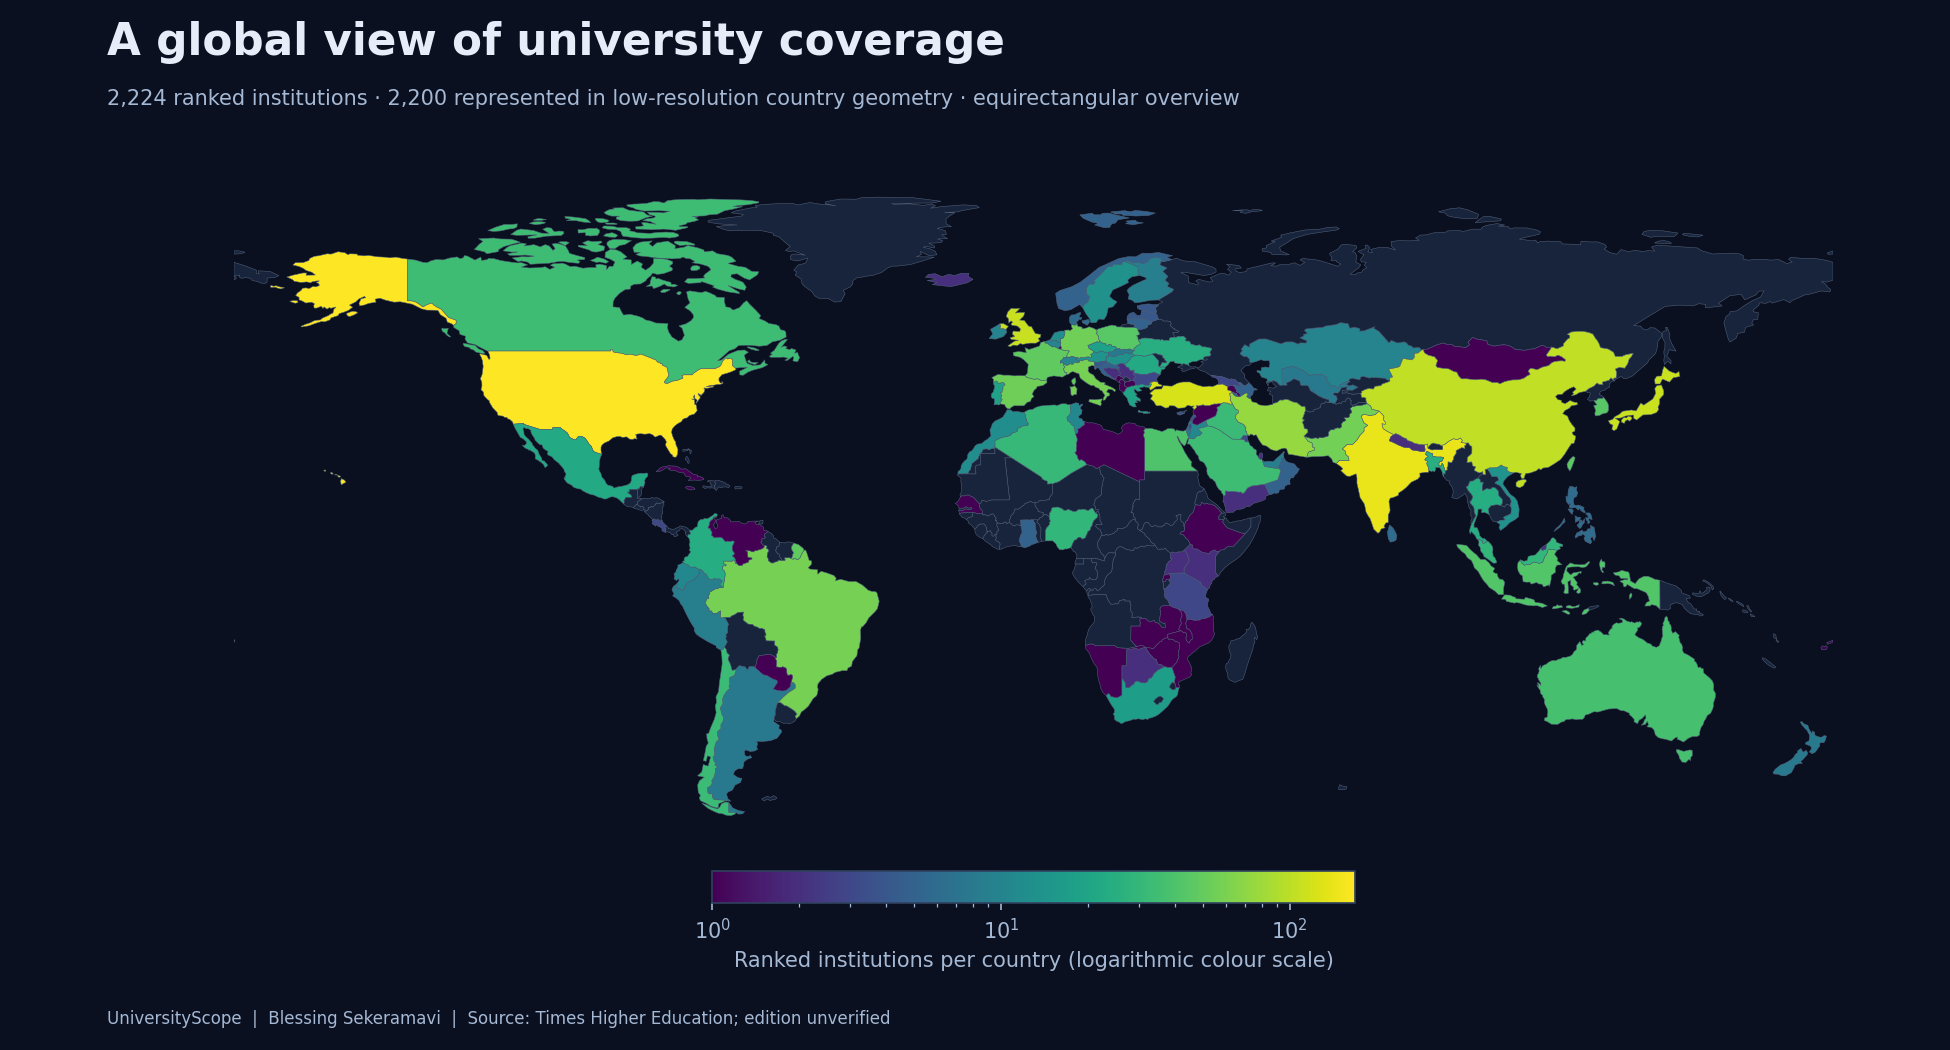

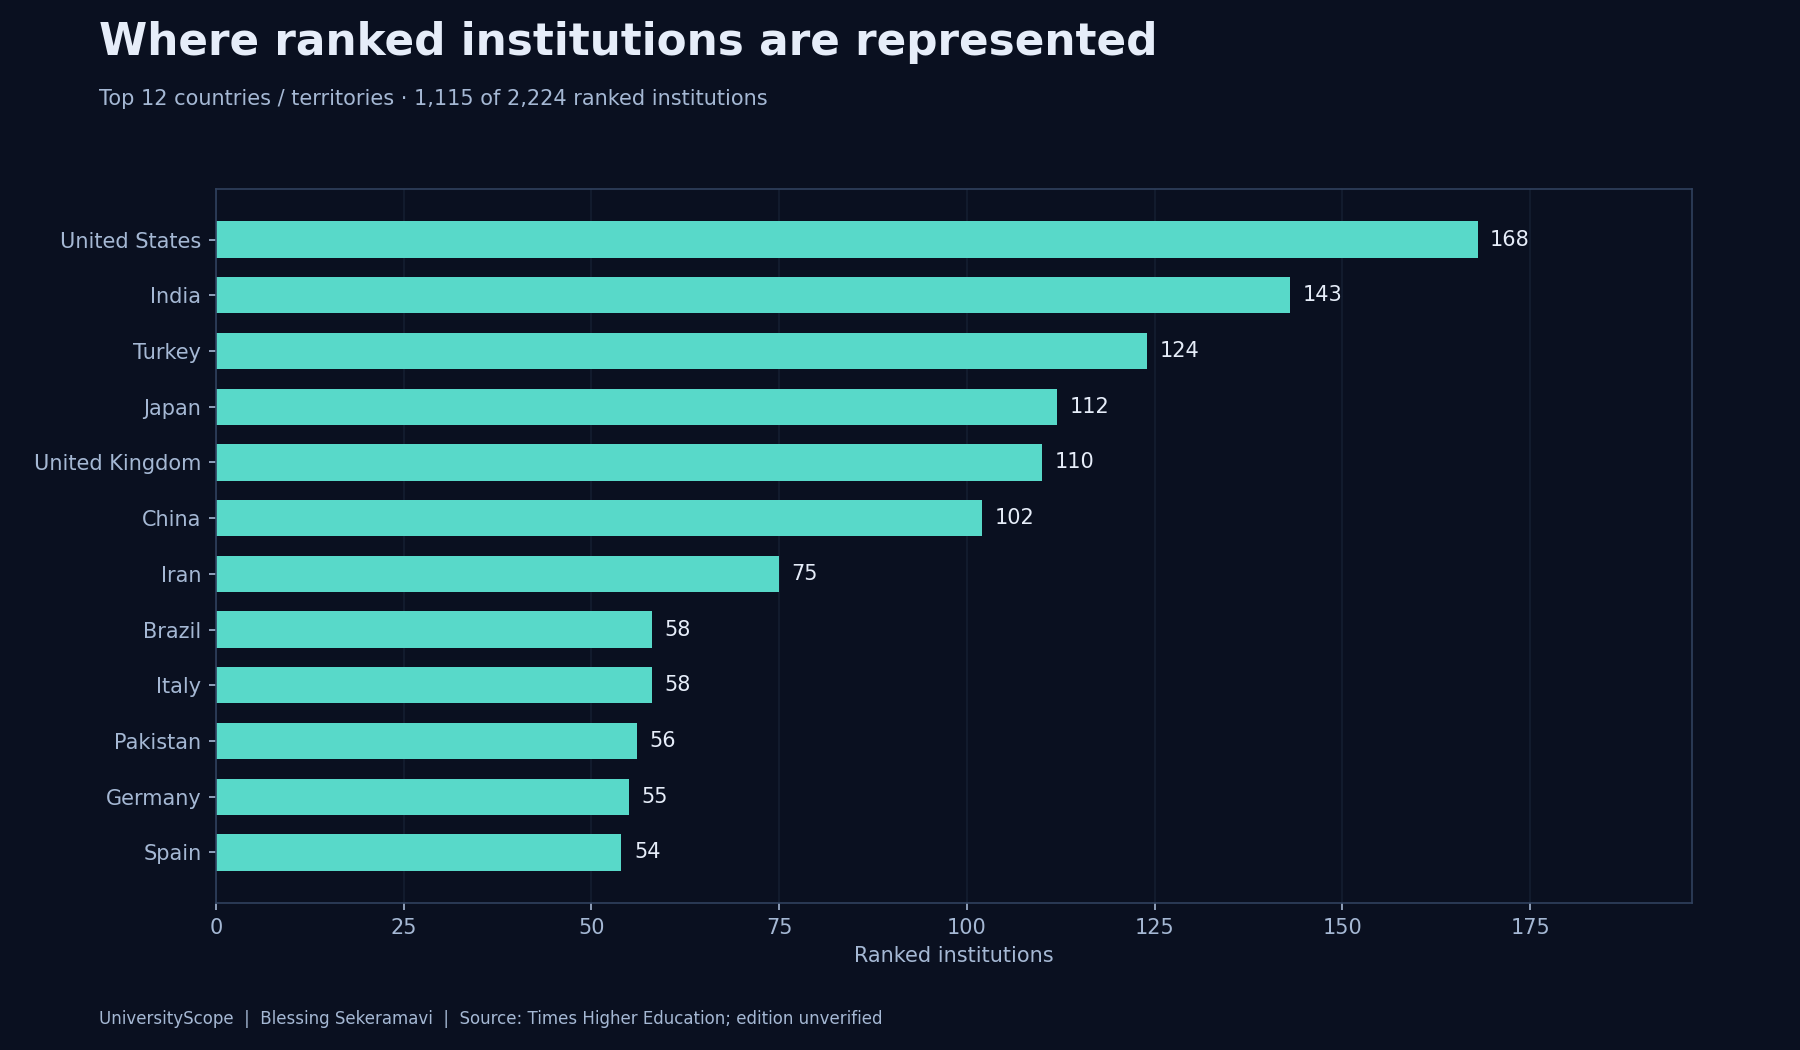

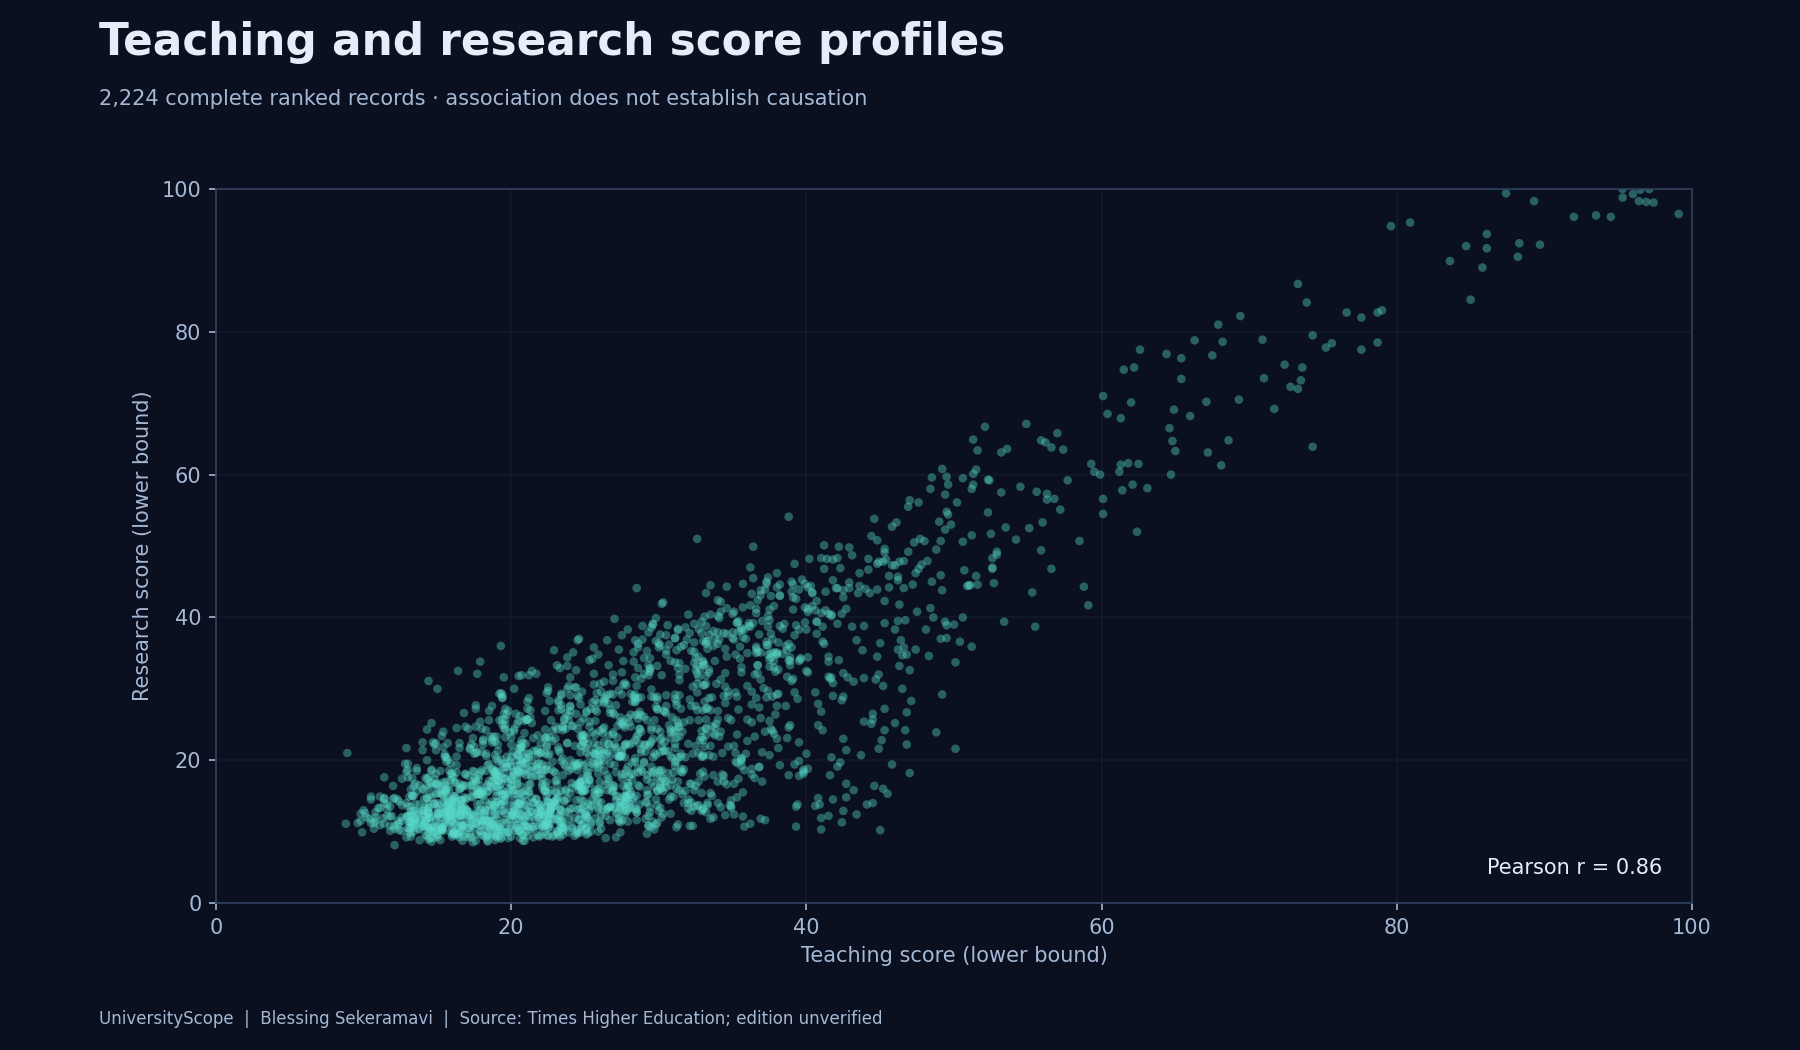

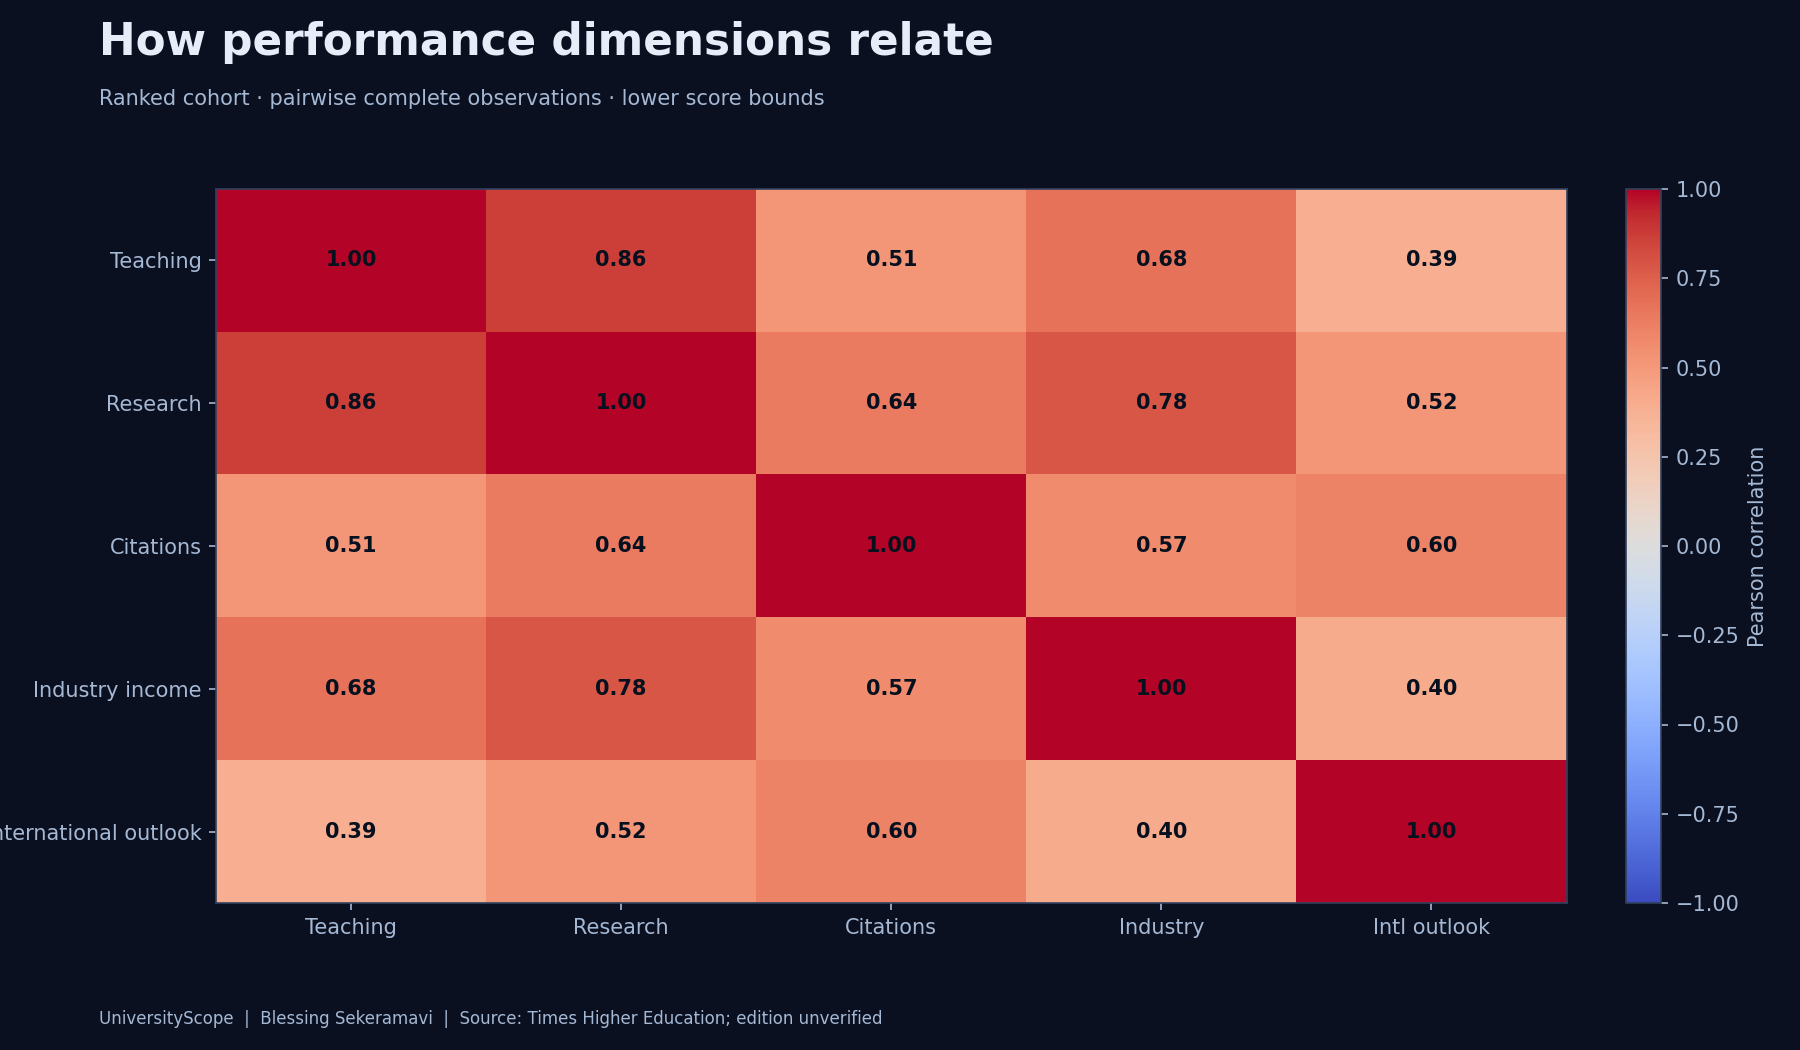

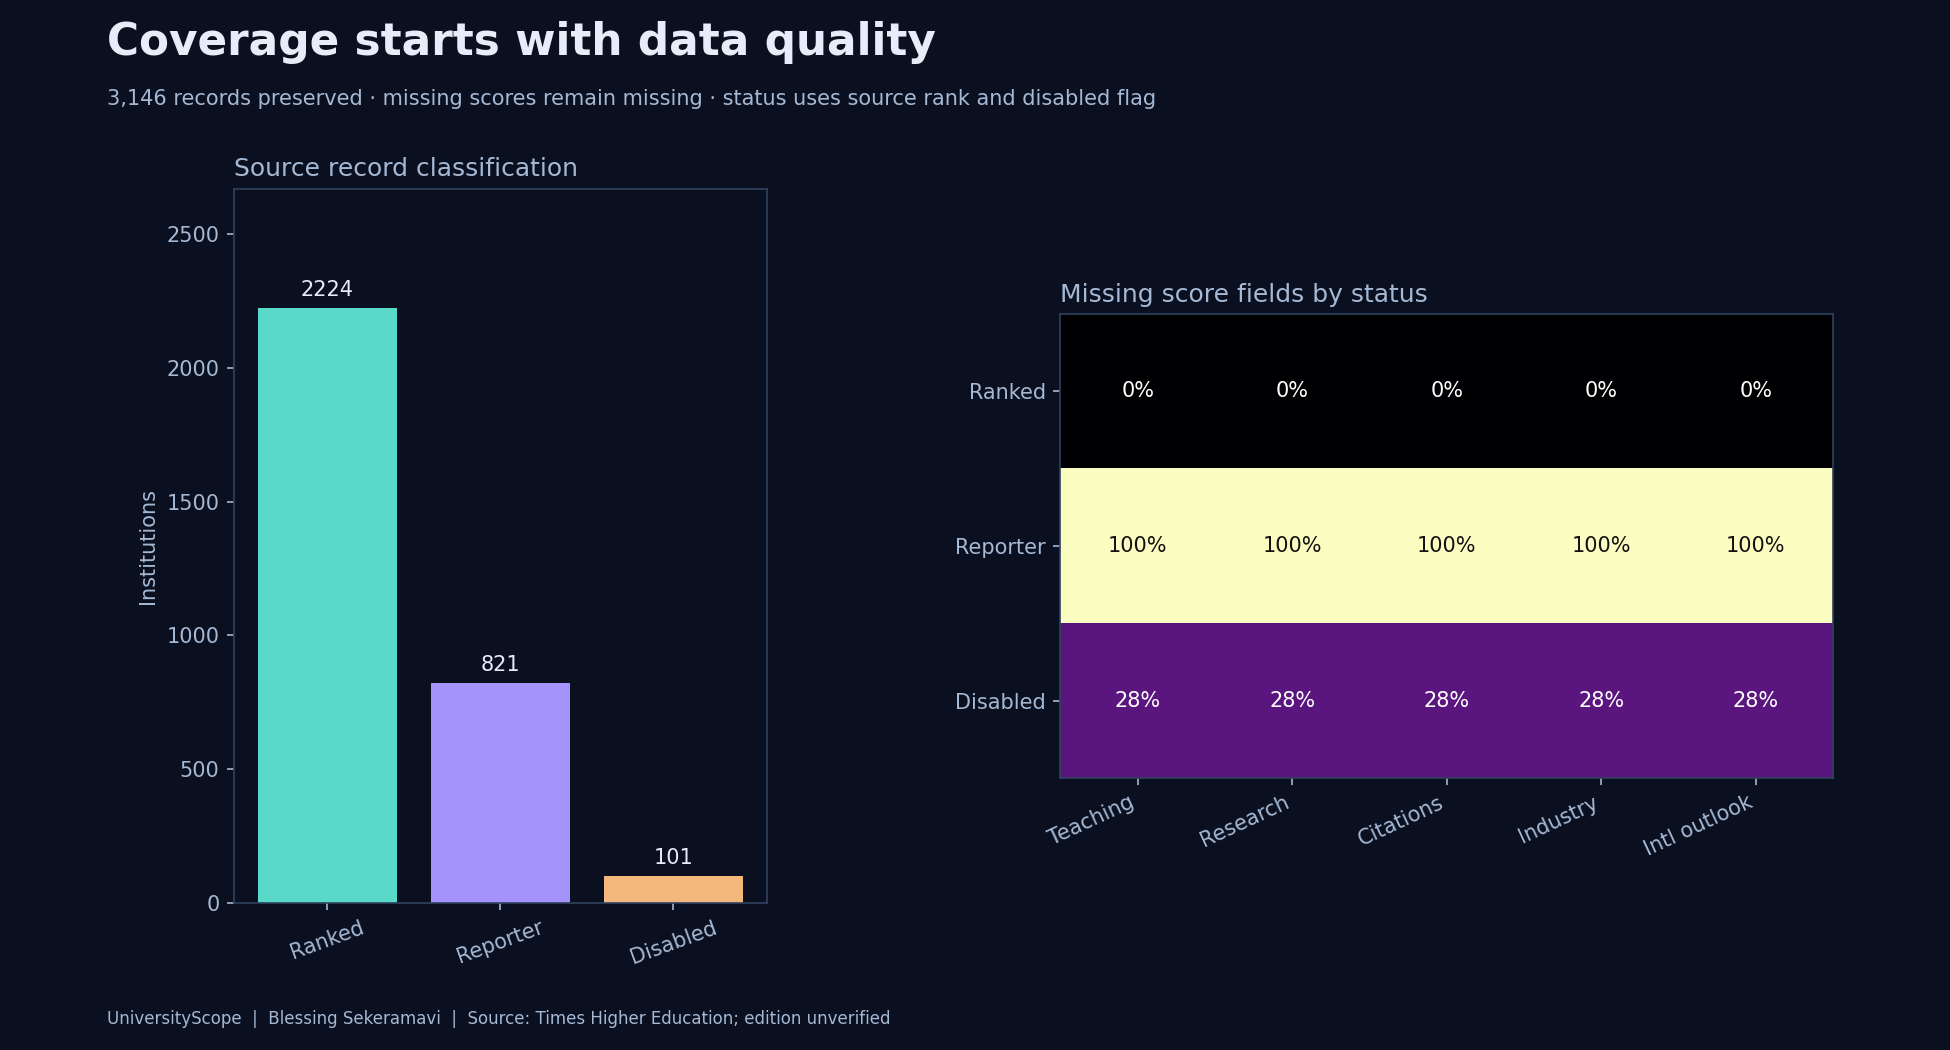

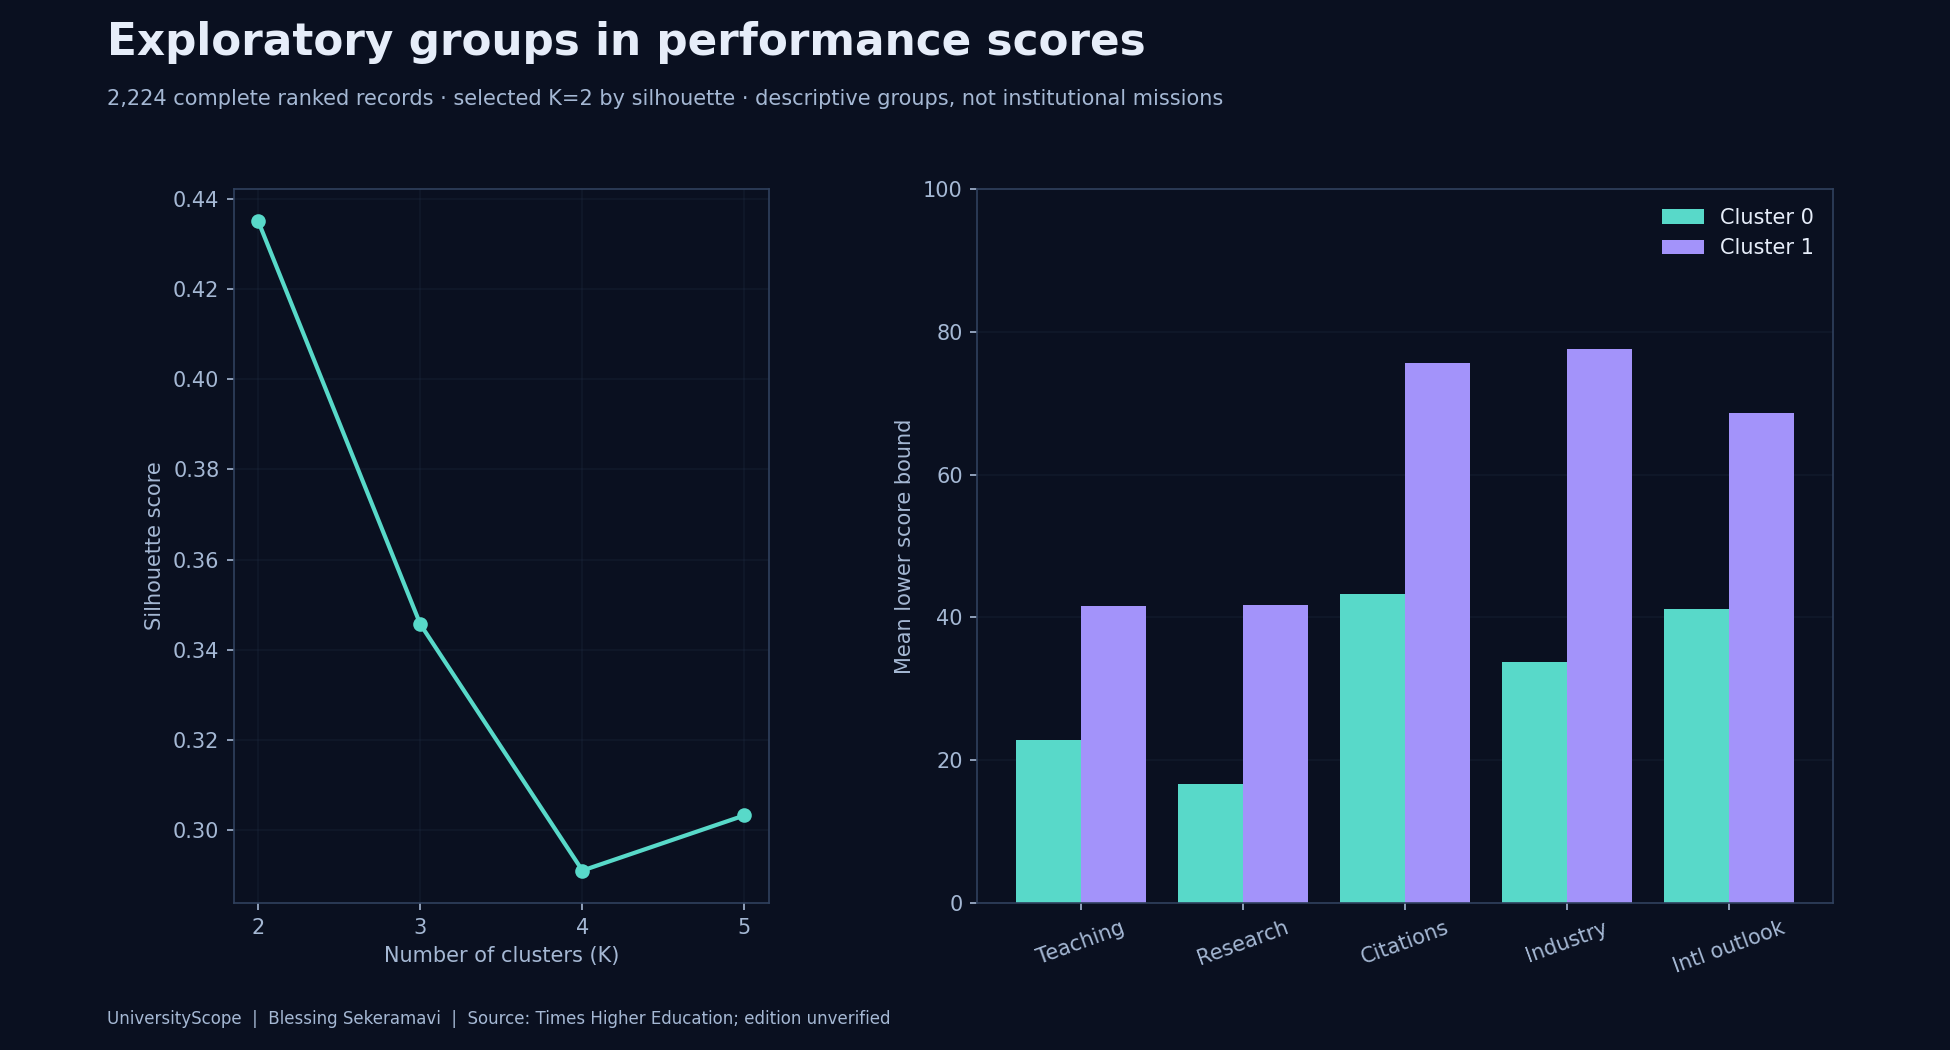

In [ ]:
for name in report['visuals']:
    display(Image(filename=f'assets/{name}.png'))


## 4. Interactive dashboard and maps
Explore the 3D globe or 2D map, search and filter institutions, compare up to four universities and export a shortlist. Cluster profiles use fitted full-cohort labels; filtering changes displayed members, not the fitted model.

The dashboard appears in the frame below. Scroll inside it for comparisons and the institution table. JavaScript libraries need CDN access. If WebGL fails, the 2D map is used. Country boundaries are embedded. Low-resolution geometry omits some small territories; coverage is reported separately from country-code matches.

Download `universityscope_dashboard.html` from Colab's Files sidebar to open it in a browser. GitHub notebook previews do not execute interactive JavaScript.


In [ ]:
from dashboard import build_dashboard, show_dashboard
document=build_dashboard(df,provenance)
show_dashboard(document,height=1150)
print('Dashboard displayed above. Standalone file: universityscope_dashboard.html')
